# Supplementary experiment figures

This notebook contains **editable Matplotlib code and saved outputs for all 10 figures**.
The eight figures used in the appendix appear first, followed by two additional mechanism plots.
The embedded data snapshot corresponds to commit `d614c2f`. Experiment (a) uses **6,000 paired realizations**.
Figures A.1 and A.3 retain the central **95% sample ranges**. Legends use **σ**, and the default font is **Times New Roman**.

## Instructions

1. Open this file in JupyterLab, Jupyter Notebook, or VS Code and select a Python 3 kernel.
2. Run the **Common settings**, **Data**, and **Plotting helpers** cells before running individual figure cells.
3. Common settings control the font, font scale, colors, figure sizes, shaded ranges, and export options. Individual figure cells can also be edited to change axis labels, titles, line styles, and legends.
4. The notebook uses the embedded results by default and **does not resample the experiments**. Set `EXPORT_FIGURES = True` to export PNG and PDF files when running figure cells. Add `"svg"` to `EXPORT_FORMATS` for SVG output.

NumPy, Matplotlib, and a Jupyter Python kernel are required. All plotting data and helper functions are embedded,
so this notebook can also be used independently in another directory. The settings cell registers installed Times New Roman fonts when the kernel has a stale font cache. If needed, set `FONT_DIR` to a folder containing the font files. The font itself is not distributed.
To load results from a new simulation run, set `USE_LOCAL_DATA = True` and specify `DATA_DIR`.
To change experimental parameters, first rerun the experiment scripts and then load the resulting data here.
This notebook edits and displays figures from existing results.

| Order | Appendix figure | Export file stem |
|---|---|---|
| 1 | A.1 | fig06_mean_minimum_comparison |
| 2 | A.2 | fig02_history_variability |
| 3 | A.3 | fig07_history_rate_comparison |
| 4 | A.4 | fig03_rate_drift |
| 5 | A.5 | fig08_drift_allocation_comparison |
| 6 | A.6 | fig04_combined |
| 7 | A.7 | fig09_static_theory_comparison |
| 8 | A.8 | fig10_half_workers_paired |
| 9 | — | fig01_minimum_rate |
| 10 | — | fig05_many_workers_histories |


## Common settings

After changing these parameters, rerun the settings cell and the figure cells to be updated.


In [1]:
from pathlib import Path
import csv
import json
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D
from IPython import get_ipython
from IPython.display import display

get_ipython().run_line_magic("matplotlib", "inline")

# Global appearance settings
FONT_FAMILY = "Times New Roman"
# Optional folder containing installed/licensed TTF or OTF files.
FONT_DIR = None
FONT_SCALE = 1.0
FIGURE_SCALE = 1.0
COLORS = ["#246a9d", "#d07b27", "#31816b", "#8c558c"]
LINE_WIDTH = 1.5
SHOW_95_RANGE = True
BAND_ALPHA_SCALE = 1.0
PREVIEW_DPI = 120
PNG_DPI = 220

# Export settings: display only by default; enable exports to notebook_figures.
EXPORT_FIGURES = False
EXPORT_DIR = Path("notebook_figures")
EXPORT_FORMATS = ("png", "pdf")

# Use the embedded snapshot by default. If True, DATA_DIR must point to the results directory.
USE_LOCAL_DATA = False
DATA_DIR = Path("results")

# Figure sizes in inches; FIGURE_SCALE scales all figures together.
FIG_SIZES = {
    "fig01_minimum_rate": (7.3, 4.3),
    "fig02_history_variability": (10.2, 4.0),
    "fig03_rate_drift": (10.2, 4.0),
    "fig04_combined": (10.2, 4.2),
    "fig05_many_workers_histories": (10.2, 4.1),
    "fig06_mean_minimum_comparison": (10.2, 5.0),
    "fig07_history_rate_comparison": (10.2, 5.0),
    "fig08_drift_allocation_comparison": (10.2, 5.0),
    "fig09_static_theory_comparison": (10.2, 5.0),
    "fig10_half_workers_paired": (10.2, 5.0),
}

# Preserve font sizes for the comparison and mechanism plots, or override them here.
TEXT_SIZES = {
    "comparison": {"font.size": 14, "axes.labelsize": 14,
                   "axes.titlesize": 13, "legend.fontsize": 12},
    "original": {"font.size": 10, "axes.labelsize": 10,
                 "axes.titlesize": 12, "legend.fontsize": 9},
}

CASE_NAMES = {
    "node_only": "Node differences",
    "history_only": "History variability",
    "drift_only": "Rate drift",
    "combined": "Combined",
}

def register_plot_font(family, font_dir=None):
    """Discover installed fonts even when the current kernel has a stale cache."""
    if font_dir is None:
        try:
            return font_manager.findfont(family, fallback_to_default=False)
        except ValueError:
            candidates = font_manager.findSystemFonts()
    else:
        directory = Path(font_dir).expanduser()
        if not directory.is_dir():
            raise FileNotFoundError(f"Font directory does not exist: {directory}")
        candidates = [str(p) for p in directory.rglob("*")
                      if p.suffix.lower() in (".ttf", ".otf", ".ttc")]
    for filename in sorted(candidates):
        try:
            if font_manager.FontProperties(fname=filename).get_name() == family:
                font_manager.fontManager.addfont(filename)
        except (OSError, RuntimeError, ValueError):
            continue
    try:
        return font_manager.findfont(family, fallback_to_default=False)
    except ValueError as error:
        raise RuntimeError(
            f"{family} was not found. Install this font in the kernel's environment, "
            "or set FONT_DIR to its font folder, then rerun this cell."
        ) from error


FONT_PATH = register_plot_font(FONT_FAMILY, FONT_DIR)
print(f"Plot font: {FONT_FAMILY} ({Path(FONT_PATH).name})")

Plot font: Times New Roman (times.ttf)


## Data

The collapsed cell below stores the current data snapshot and usually does not need to be edited.
All figure cells share the same data.


In [2]:
EMBEDDED_DATA = json.loads(r'''
{
  "original": {
    "metadata": {
      "seed": 20261014,
      "numpy": "2.5.4",
      "matplotlib": "3.11.2",
      "python": "3.12.14",
      "minimum_repeats": 6000,
      "history_repeats": 12000,
      "combined_repeats": 128,
      "combined_workers": 256,
      "histories_per_worker": 256,
      "poisson_mean": 20,
      "overhead_work": 5,
      "mixture_probabilities": [
        0.9,
        0.1
      ],
      "mixture_intensities": [
        4,
        164
      ],
      "rate_bounds": [
        0.2,
        1.8
      ],
      "combined_node_parent_std": 0.1,
      "combined_affected_probability": 0.25,
      "combined_rate_drop": 0.4,
      "normalized_thermal_onset": 0.3,
      "normalized_ramp_duration": 0.25
    },
    "minimum_rates": [
      {
        "parent_std": 0.01,
        "workers": 1,
        "repeats": 6000,
        "mean_minimum": 0.9998309462998124,
        "p025": 0.9804143478650031,
        "p975": 1.0194532808282257,
        "standard_deviation": 0.01008352660656585
      },
      {
        "parent_std": 0.01,
        "workers": 2,
        "repeats": 6000,
        "mean_minimum": 0.9942151447651252,
        "p025": 0.9776230792071353,
        "p975": 1.0099103375483953,
        "standard_deviation": 0.00833922432616533
      },
      {
        "parent_std": 0.01,
        "workers": 4,
        "repeats": 6000,
        "mean_minimum": 0.9895822791758749,
        "p025": 0.9750682503040262,
        "p975": 1.0025065137273599,
        "standard_deviation": 0.0070937320674059525
      },
      {
        "parent_std": 0.01,
        "workers": 8,
        "repeats": 6000,
        "mean_minimum": 0.9856541442720828,
        "p025": 0.972703610371107,
        "p975": 0.9965945046957708,
        "standard_deviation": 0.006186340523879624
      },
      {
        "parent_std": 0.01,
        "workers": 16,
        "repeats": 6000,
        "mean_minimum": 0.9822409707525848,
        "p025": 0.9704950994091313,
        "p975": 0.9917332956178323,
        "standard_deviation": 0.005509354124049858
      },
      {
        "parent_std": 0.01,
        "workers": 32,
        "repeats": 6000,
        "mean_minimum": 0.9792125648729219,
        "p025": 0.9684171089656901,
        "p975": 0.9876239059463564,
        "standard_deviation": 0.0049912691569886135
      },
      {
        "parent_std": 0.01,
        "workers": 64,
        "repeats": 6000,
        "mean_minimum": 0.9764785965628374,
        "p025": 0.9664499932752233,
        "p975": 0.984063361366067,
        "standard_deviation": 0.004584658536043891
      },
      {
        "parent_std": 0.01,
        "workers": 128,
        "repeats": 6000,
        "mean_minimum": 0.9739754052595384,
        "p025": 0.9645783910925044,
        "p975": 0.9809127857917682,
        "standard_deviation": 0.004257858904201403
      },
      {
        "parent_std": 0.01,
        "workers": 256,
        "repeats": 6000,
        "mean_minimum": 0.9716572793999512,
        "p025": 0.9627900772694657,
        "p975": 0.9780759046921585,
        "standard_deviation": 0.003989470065213962
      },
      {
        "parent_std": 0.01,
        "workers": 512,
        "repeats": 6000,
        "mean_minimum": 0.969490719564925,
        "p025": 0.9610751641889896,
        "p975": 0.9754848349444517,
        "standard_deviation": 0.0037647927446706527
      },
      {
        "parent_std": 0.01,
        "workers": 1024,
        "repeats": 6000,
        "mean_minimum": 0.9674506561953664,
        "p025": 0.9594255371829976,
        "p975": 0.9730907757681905,
        "standard_deviation": 0.0035735420475385095
      },
      {
        "parent_std": 0.01,
        "workers": 2048,
        "repeats": 6000,
        "mean_minimum": 0.9655179373176976,
        "p025": 0.9578344486372028,
        "p975": 0.970857915409796,
        "standard_deviation": 0.0034083792506290397
      },
      {
        "parent_std": 0.01,
        "workers": 4096,
        "repeats": 6000,
        "mean_minimum": 0.9636776409881237,
        "p025": 0.9562962213217708,
        "p975": 0.9687594217256142,
        "standard_deviation": 0.003263962810331869
      },
      {
        "parent_std": 0.01,
        "workers": 8192,
        "repeats": 6000,
        "mean_minimum": 0.9619179259250847,
        "p025": 0.954806028059644,
        "p975": 0.9667747786503598,
        "standard_deviation": 0.003136328385728352
      },
      {
        "parent_std": 0.01,
        "workers": 16384,
        "repeats": 6000,
        "mean_minimum": 0.9602292364412046,
        "p025": 0.9533597255731915,
        "p975": 0.9648879944441343,
        "standard_deviation": 0.0030224783877212083
      },
      {
        "parent_std": 0.01,
        "workers": 32768,
        "repeats": 6000,
        "mean_minimum": 0.9586037433059582,
        "p025": 0.9519537273704742,
        "p975": 0.9630863787199326,
        "standard_deviation": 0.0029201061548893305
      },
      {
        "parent_std": 0.01,
        "workers": 65536,
        "repeats": 6000,
        "mean_minimum": 0.9570349438216584,
        "p025": 0.9505849051809805,
        "p975": 0.9613596943772428,
        "standard_deviation": 0.00282740762849848
      },
      {
        "parent_std": 0.01,
        "workers": 131072,
        "repeats": 6000,
        "mean_minimum": 0.9555173709137977,
        "p025": 0.9492505115675536,
        "p975": 0.9596995597130613,
        "standard_deviation": 0.002742950648349304
      },
      {
        "parent_std": 0.01,
        "workers": 262144,
        "repeats": 6000,
        "mean_minimum": 0.9540463780104959,
        "p025": 0.9479481184585411,
        "p975": 0.9580990197905865,
        "standard_deviation": 0.0026655827366981128
      },
      {
        "parent_std": 0.01,
        "workers": 524288,
        "repeats": 6000,
        "mean_minimum": 0.9526179774372322,
        "p025": 0.9466755678017391,
        "p975": 0.9565522340143889,
        "standard_deviation": 0.002594364975179884
      },
      {
        "parent_std": 0.01,
        "workers": 1048576,
        "repeats": 6000,
        "mean_minimum": 0.9512287171889927,
        "p025": 0.9454309315585054,
        "p975": 0.9550542447118002,
        "standard_deviation": 0.002528523841648768
      },
      {
        "parent_std": 0.05,
        "workers": 1,
        "repeats": 6000,
        "mean_minimum": 1.0006262229189673,
        "p025": 0.9007596808553898,
        "p975": 1.0951838197901365,
        "standard_deviation": 0.04972053146970743
      },
      {
        "parent_std": 0.05,
        "workers": 2,
        "repeats": 6000,
        "mean_minimum": 0.9723145880316539,
        "p025": 0.8869212806989194,
        "p975": 1.0479560609340461,
        "standard_deviation": 0.04109956119490398
      },
      {
        "parent_std": 0.05,
        "workers": 4,
        "repeats": 6000,
        "mean_minimum": 0.948981130834099,
        "p025": 0.8742411178566469,
        "p975": 1.0112755983757182,
        "standard_deviation": 0.03494638352294802
      },
      {
        "parent_std": 0.05,
        "workers": 8,
        "repeats": 6000,
        "mean_minimum": 0.9292147503273192,
        "p025": 0.8624944112956907,
        "p975": 0.9819527912520176,
        "standard_deviation": 0.03046564086186786
      },
      {
        "parent_std": 0.05,
        "workers": 16,
        "repeats": 6000,
        "mean_minimum": 0.9120531986759496,
        "p025": 0.8515153168878625,
        "p975": 0.9578151422828184,
        "standard_deviation": 0.02712428581850782
      },
      {
        "parent_std": 0.05,
        "workers": 32,
        "repeats": 6000,
        "mean_minimum": 0.8968365654714097,
        "p025": 0.8411789121320448,
        "p975": 0.9373899354354709,
        "standard_deviation": 0.024568425548067253
      },
      {
        "parent_std": 0.05,
        "workers": 64,
        "repeats": 6000,
        "mean_minimum": 0.8831071987406218,
        "p025": 0.8313891922950848,
        "p975": 0.9196771754131022,
        "standard_deviation": 0.022563377675887147
      },
      {
        "parent_std": 0.05,
        "workers": 128,
        "repeats": 6000,
        "mean_minimum": 0.8705427234398282,
        "p025": 0.8220709662875514,
        "p975": 0.903992376279993,
        "standard_deviation": 0.02095251225352519
      },
      {
        "parent_std": 0.05,
        "workers": 256,
        "repeats": 6000,
        "mean_minimum": 0.8589117787639685,
        "p025": 0.813164302983096,
        "p975": 0.8898607443663885,
        "standard_deviation": 0.019630008339276805
      },
      {
        "parent_std": 0.05,
        "workers": 512,
        "repeats": 6000,
        "mean_minimum": 0.8480449059067062,
        "p025": 0.8046206637129351,
        "p975": 0.8769472656068348,
        "standard_deviation": 0.01852320957926387
      },
      {
        "parent_std": 0.05,
        "workers": 1024,
        "repeats": 6000,
        "mean_minimum": 0.8378153592356232,
        "p025": 0.7964001638371742,
        "p975": 0.865010913514929,
        "standard_deviation": 0.01758130004304229
      },
      {
        "parent_std": 0.05,
        "workers": 2048,
        "repeats": 6000,
        "mean_minimum": 0.8281263641929757,
        "p025": 0.7884696010481363,
        "p975": 0.8538746726229276,
        "standard_deviation": 0.016768034747842248
      },
      {
        "parent_std": 0.05,
        "workers": 4096,
        "repeats": 6000,
        "mean_minimum": 0.8189025607453254,
        "p025": 0.7808010121429407,
        "p975": 0.8434058079614369,
        "standard_deviation": 0.016057042460318298
      },
      {
        "parent_std": 0.05,
        "workers": 8192,
        "repeats": 6000,
        "mean_minimum": 0.8100841776017484,
        "p025": 0.7733705996529804,
        "p975": 0.8335027520146681,
        "standard_deviation": 0.015428758084887608
      },
      {
        "parent_std": 0.05,
        "workers": 16384,
        "repeats": 6000,
        "mean_minimum": 0.801623003707267,
        "p025": 0.766157921329949,
        "p975": 0.8240862789468464,
        "standard_deviation": 0.014868392495829193
      },
      {
        "parent_std": 0.05,
        "workers": 32768,
        "repeats": 6000,
        "mean_minimum": 0.7934795562317797,
        "p025": 0.7591452692957157,
        "p975": 0.8150934769658866,
        "standard_deviation": 0.014364568736490217
      },
      {
        "parent_std": 0.05,
        "workers": 65536,
        "repeats": 6000,
        "mean_minimum": 0.7856210557543246,
        "p025": 0.7523171880731349,
        "p975": 0.806473565862331,
        "standard_deviation": 0.013908391170974806
      },
      {
        "parent_std": 0.05,
        "workers": 131072,
        "repeats": 6000,
        "mean_minimum": 0.778019953966248,
        "p025": 0.7456600957580533,
        "p975": 0.79818494646915,
        "standard_deviation": 0.013492799653848076
      },
      {
        "parent_std": 0.05,
        "workers": 262144,
        "repeats": 6000,
        "mean_minimum": 0.7706528453714903,
        "p025": 0.7391619828238756,
        "p975": 0.790193084037118,
        "standard_deviation": 0.013112114017581533
      },
      {
        "parent_std": 0.05,
        "workers": 524288,
        "repeats": 6000,
        "mean_minimum": 0.7634996500385153,
        "p025": 0.7328121701015358,
        "p975": 0.7824689644785495,
        "standard_deviation": 0.012761707545923165
      },
      {
        "parent_std": 0.05,
        "workers": 1048576,
        "repeats": 6000,
        "mean_minimum": 0.7565429906646887,
        "p025": 0.7266011124028058,
        "p975": 0.7749879501867142,
        "standard_deviation": 0.01243776920231282
      },
      {
        "parent_std": 0.1,
        "workers": 1,
        "repeats": 6000,
        "mean_minimum": 0.9988228707832502,
        "p025": 0.8015856601344795,
        "p975": 1.1976065840654595,
        "standard_deviation": 0.10028569730334556
      },
      {
        "parent_std": 0.1,
        "workers": 2,
        "repeats": 6000,
        "mean_minimum": 0.9426019654604585,
        "p025": 0.7739029359498582,
        "p975": 1.1014563849029524,
        "standard_deviation": 0.08285130052106349
      },
      {
        "parent_std": 0.1,
        "workers": 4,
        "repeats": 6000,
        "mean_minimum": 0.8962257304784973,
        "p025": 0.7485378852930753,
        "p975": 1.0269169581364213,
        "standard_deviation": 0.07040976277864858
      },
      {
        "parent_std": 0.1,
        "workers": 8,
        "repeats": 6000,
        "mean_minimum": 0.8569076354144327,
        "p025": 0.725040623031294,
        "p975": 0.9674458903246065,
        "standard_deviation": 0.061352156108931494
      },
      {
        "parent_std": 0.1,
        "workers": 16,
        "repeats": 6000,
        "mean_minimum": 0.8227468986549111,
        "p025": 0.7030792383539741,
        "p975": 0.9185848000417741,
        "standard_deviation": 0.054599937414567194
      },
      {
        "parent_std": 0.1,
        "workers": 32,
        "repeats": 6000,
        "mean_minimum": 0.7924394483508234,
        "p025": 0.6824037303170271,
        "p975": 0.8773110119263475,
        "standard_deviation": 0.049436932212229126
      },
      {
        "parent_std": 0.1,
        "workers": 64,
        "repeats": 6000,
        "mean_minimum": 0.7650805054736143,
        "p025": 0.662821978192223,
        "p975": 0.841572734486183,
        "standard_deviation": 0.045388162760448096
      },
      {
        "parent_std": 0.1,
        "workers": 128,
        "repeats": 6000,
        "mean_minimum": 0.7400324339129944,
        "p025": 0.6441835189364737,
        "p975": 0.809966540074134,
        "standard_deviation": 0.04213661295825154
      },
      {
        "parent_std": 0.1,
        "workers": 256,
        "repeats": 6000,
        "mean_minimum": 0.7168373915824001,
        "p025": 0.626368430439234,
        "p975": 0.7815199322219124,
        "standard_deviation": 0.03946811204022986
      },
      {
        "parent_std": 0.1,
        "workers": 512,
        "repeats": 6000,
        "mean_minimum": 0.6951598643659785,
        "p025": 0.6092795902619135,
        "p975": 0.75554755777863,
        "standard_deviation": 0.03723562688332292
      },
      {
        "parent_std": 0.1,
        "workers": 1024,
        "repeats": 6000,
        "mean_minimum": 0.6747487780213565,
        "p025": 0.5928371945651518,
        "p975": 0.73155699909133,
        "standard_deviation": 0.035336339259534694
      },
      {
        "parent_std": 0.1,
        "workers": 2048,
        "repeats": 6000,
        "mean_minimum": 0.6554123319242738,
        "p025": 0.5769748118305509,
        "p975": 0.7091871138685485,
        "standard_deviation": 0.03369692819042815
      },
      {
        "parent_std": 0.1,
        "workers": 4096,
        "repeats": 6000,
        "mean_minimum": 0.6370010944005603,
        "p025": 0.5616364944013723,
        "p975": 0.6881674713159319,
        "standard_deviation": 0.03226405915457254
      },
      {
        "parent_std": 0.1,
        "workers": 8192,
        "repeats": 6000,
        "mean_minimum": 0.6193964894030746,
        "p025": 0.546774630327281,
        "p975": 0.6682914132640972,
        "standard_deviation": 0.030998172680374143
      },
      {
        "parent_std": 0.1,
        "workers": 16384,
        "repeats": 6000,
        "mean_minimum": 0.6025028324082831,
        "p025": 0.5323483213233577,
        "p975": 0.6493979393866572,
        "standard_deviation": 0.029869373738490045
      },
      {
        "parent_std": 0.1,
        "workers": 32768,
        "repeats": 6000,
        "mean_minimum": 0.586241729740948,
        "p025": 0.5183221403334453,
        "p975": 0.6313593481464648,
        "standard_deviation": 0.028854670613219092
      },
      {
        "parent_std": 0.1,
        "workers": 65536,
        "repeats": 6000,
        "mean_minimum": 0.5705480727878152,
        "p025": 0.5046651670490325,
        "p975": 0.6140726703627064,
        "standard_deviation": 0.027936090566541987
      },
      {
        "parent_std": 0.1,
        "workers": 131072,
        "repeats": 6000,
        "mean_minimum": 0.5553671242205903,
        "p025": 0.4913502298484088,
        "p975": 0.5974536326879498,
        "standard_deviation": 0.027099372679085895
      },
      {
        "parent_std": 0.1,
        "workers": 262144,
        "repeats": 6000,
        "mean_minimum": 0.5406523633909674,
        "p025": 0.4783533031011463,
        "p975": 0.5814323320102263,
        "standard_deviation": 0.02633304605940234
      },
      {
        "parent_std": 0.1,
        "workers": 524288,
        "repeats": 6000,
        "mean_minimum": 0.52636386777103,
        "p025": 0.46565302289851174,
        "p975": 0.5659500840218372,
        "standard_deviation": 0.025627769198681916
      },
      {
        "parent_std": 0.1,
        "workers": 1048576,
        "repeats": 6000,
        "mean_minimum": 0.5124670787997754,
        "p025": 0.45323029413012067,
        "p975": 0.5509570899337574,
        "standard_deviation": 0.024975848989258975
      },
      {
        "parent_std": 0.2,
        "workers": 1,
        "repeats": 6000,
        "mean_minimum": 0.9991993957312079,
        "p025": 0.606820963769795,
        "p975": 1.3946555130807317,
        "standard_deviation": 0.20120926840091818
      },
      {
        "parent_std": 0.2,
        "workers": 2,
        "repeats": 6000,
        "mean_minimum": 0.8864924690116884,
        "p025": 0.551225226538484,
        "p975": 1.2025488158037285,
        "standard_deviation": 0.1661286826651573
      },
      {
        "parent_std": 0.2,
        "workers": 4,
        "repeats": 6000,
        "mean_minimum": 0.7935610429774207,
        "p025": 0.5004052343362281,
        "p975": 1.0535584869537922,
        "standard_deviation": 0.14101880744665646
      },
      {
        "parent_std": 0.2,
        "workers": 8,
        "repeats": 6000,
        "mean_minimum": 0.7148318867453395,
        "p025": 0.453511086381114,
        "p975": 0.9346757427443529,
        "standard_deviation": 0.1226634088394698
      },
      {
        "parent_std": 0.2,
        "workers": 16,
        "repeats": 6000,
        "mean_minimum": 0.6465057603775639,
        "p025": 0.4099935615620342,
        "p975": 0.8369988403980864,
        "standard_deviation": 0.10885366759379443
      },
      {
        "parent_std": 0.2,
        "workers": 32,
        "repeats": 6000,
        "mean_minimum": 0.5859970082489377,
        "p025": 0.36957908001260387,
        "p975": 0.7544910914029227,
        "standard_deviation": 0.09808831220611561
      },
      {
        "parent_std": 0.2,
        "workers": 64,
        "repeats": 6000,
        "mean_minimum": 0.5315466093983232,
        "p025": 0.3322995790499562,
        "p975": 0.683057181951981,
        "standard_deviation": 0.08932533154463516
      },
      {
        "parent_std": 0.2,
        "workers": 128,
        "repeats": 6000,
        "mean_minimum": 0.48197129140917877,
        "p025": 0.2985620548321065,
        "p975": 0.619901233358967,
        "standard_deviation": 0.08180758503220856
      },
      {
        "parent_std": 0.2,
        "workers": 256,
        "repeats": 6000,
        "mean_minimum": 0.43650935058391027,
        "p025": 0.2691855920770716,
        "p975": 0.5630960887879569,
        "standard_deviation": 0.0749478315701688
      },
      {
        "parent_std": 0.2,
        "workers": 512,
        "repeats": 6000,
        "mean_minimum": 0.3947332521309914,
        "p025": 0.24522474959230156,
        "p975": 0.5113029216593327,
        "standard_deviation": 0.06826291911430775
      },
      {
        "parent_std": 0.2,
        "workers": 1024,
        "repeats": 6000,
        "mean_minimum": 0.3565048502764333,
        "p025": 0.2274148591138758,
        "p975": 0.4635960002715693,
        "standard_deviation": 0.06135214161598913
      },
      {
        "parent_std": 0.2,
        "workers": 2048,
        "repeats": 6000,
        "mean_minimum": 0.3219479903386454,
        "p025": 0.21553024694805195,
        "p975": 0.4193636335257907,
        "standard_deviation": 0.05392068533926626
      },
      {
        "parent_std": 0.2,
        "workers": 4096,
        "repeats": 6000,
        "mean_minimum": 0.29140711684239684,
        "p025": 0.20835970441901122,
        "p975": 0.3782704462014285,
        "standard_deviation": 0.04584449493798277
      },
      {
        "parent_std": 0.2,
        "workers": 8192,
        "repeats": 6000,
        "mean_minimum": 0.2653550918956425,
        "p025": 0.20435343850798068,
        "p975": 0.340275552119548,
        "standard_deviation": 0.037251093787883924
      },
      {
        "parent_std": 0.2,
        "workers": 16384,
        "repeats": 6000,
        "mean_minimum": 0.2442217906376424,
        "p025": 0.20222395682236108,
        "p975": 0.30569650524946695,
        "standard_deviation": 0.02856295772066773
      },
      {
        "parent_std": 0.2,
        "workers": 32768,
        "repeats": 6000,
        "mean_minimum": 0.2281620415600172,
        "p025": 0.201124325496798,
        "p975": 0.27526507728957594,
        "standard_deviation": 0.020433852804948794
      },
      {
        "parent_std": 0.2,
        "workers": 65536,
        "repeats": 6000,
        "mean_minimum": 0.21686543187877297,
        "p025": 0.20056532083148748,
        "p975": 0.2500179713984342,
        "standard_deviation": 0.013541770546266587
      },
      {
        "parent_std": 0.2,
        "workers": 131072,
        "repeats": 6000,
        "mean_minimum": 0.20954821662780443,
        "p025": 0.20028345912479015,
        "p975": 0.2308241951781814,
        "standard_deviation": 0.008314266817542056
      },
      {
        "parent_std": 0.2,
        "workers": 262144,
        "repeats": 6000,
        "mean_minimum": 0.20516499056042592,
        "p025": 0.20014193040594336,
        "p975": 0.21770384240955548,
        "standard_deviation": 0.004770251302795173
      },
      {
        "parent_std": 0.2,
        "workers": 524288,
        "repeats": 6000,
        "mean_minimum": 0.2027045517095168,
        "p025": 0.20007101556077375,
        "p975": 0.20962254763020866,
        "standard_deviation": 0.0025961536756936225
      },
      {
        "parent_std": 0.2,
        "workers": 1048576,
        "repeats": 6000,
        "mean_minimum": 0.2013872009283622,
        "p025": 0.20003552038827313,
        "p975": 0.20504099064697273,
        "standard_deviation": 0.0013626955205825382
      }
    ],
    "history_variability": [
      {
        "model": "poisson",
        "histories": 1,
        "repeats": 12000,
        "mean_work": 25.0,
        "work_variance": 20.0,
        "empirical_time_cv": 0.18028649094210542,
        "analytic_time_cv": 0.17888543819998318,
        "speed_median": 1.0,
        "speed_p025": 0.7352941176470589,
        "speed_p975": 1.4705882352941178
      },
      {
        "model": "poisson",
        "histories": 2,
        "repeats": 12000,
        "mean_work": 25.0,
        "work_variance": 20.0,
        "empirical_time_cv": 0.12554920230018932,
        "analytic_time_cv": 0.12649110640673517,
        "speed_median": 1.0,
        "speed_p025": 0.7936507936507936,
        "speed_p975": 1.3157894736842106
      },
      {
        "model": "poisson",
        "histories": 4,
        "repeats": 12000,
        "mean_work": 25.0,
        "work_variance": 20.0,
        "empirical_time_cv": 0.09012666774477308,
        "analytic_time_cv": 0.08944271909999159,
        "speed_median": 1.0,
        "speed_p025": 0.847457627118644,
        "speed_p975": 1.2048192771084338
      },
      {
        "model": "poisson",
        "histories": 8,
        "repeats": 12000,
        "mean_work": 25.0,
        "work_variance": 20.0,
        "empirical_time_cv": 0.06358141890074384,
        "analytic_time_cv": 0.06324555320336758,
        "speed_median": 1.0,
        "speed_p025": 0.8849557522123894,
        "speed_p975": 1.1363636363636365
      },
      {
        "model": "poisson",
        "histories": 16,
        "repeats": 12000,
        "mean_work": 25.0,
        "work_variance": 20.0,
        "empirical_time_cv": 0.044894731647325326,
        "analytic_time_cv": 0.044721359549995794,
        "speed_median": 1.0,
        "speed_p025": 0.9195402298850575,
        "speed_p975": 1.095890410958904
      },
      {
        "model": "poisson",
        "histories": 32,
        "repeats": 12000,
        "mean_work": 25.0,
        "work_variance": 20.0,
        "empirical_time_cv": 0.03152201247406813,
        "analytic_time_cv": 0.03162277660168379,
        "speed_median": 1.0,
        "speed_p025": 0.9411764705882353,
        "speed_p975": 1.0652463382157125
      },
      {
        "model": "poisson",
        "histories": 64,
        "repeats": 12000,
        "mean_work": 25.0,
        "work_variance": 20.0,
        "empirical_time_cv": 0.022235406786668903,
        "analytic_time_cv": 0.022360679774997897,
        "speed_median": 1.0,
        "speed_p025": 0.9586578789694428,
        "speed_p975": 1.0450685826257349
      },
      {
        "model": "poisson",
        "histories": 128,
        "repeats": 12000,
        "mean_work": 25.0,
        "work_variance": 20.0,
        "empirical_time_cv": 0.01583835491690823,
        "analytic_time_cv": 0.015811388300841896,
        "speed_median": 1.0,
        "speed_p025": 0.9694032111481369,
        "speed_p975": 1.0315925209542232
      },
      {
        "model": "poisson",
        "histories": 256,
        "repeats": 12000,
        "mean_work": 25.0,
        "work_variance": 20.0,
        "empirical_time_cv": 0.011115156640121812,
        "analytic_time_cv": 0.011180339887498949,
        "speed_median": 1.0,
        "speed_p025": 0.9787391856810209,
        "speed_p975": 1.0223642172523961
      },
      {
        "model": "poisson",
        "histories": 512,
        "repeats": 12000,
        "mean_work": 25.0,
        "work_variance": 20.0,
        "empirical_time_cv": 0.007933580988755583,
        "analytic_time_cv": 0.007905694150420948,
        "speed_median": 0.9999218811030388,
        "speed_p025": 0.9847668872134174,
        "speed_p975": 1.0157117917790828
      },
      {
        "model": "poisson",
        "histories": 1024,
        "repeats": 12000,
        "mean_work": 25.0,
        "work_variance": 20.0,
        "empirical_time_cv": 0.0056400894180666985,
        "analytic_time_cv": 0.005590169943749474,
        "speed_median": 1.0000781311039926,
        "speed_p025": 0.9889897624106625,
        "speed_p975": 1.0111393190400702
      },
      {
        "model": "mixed_poisson",
        "histories": 1,
        "repeats": 12000,
        "mean_work": 25.0,
        "work_variance": 2324.0,
        "empirical_time_cv": 1.9245542824460706,
        "analytic_time_cv": 1.928315326911032,
        "speed_median": 2.7777777777777777,
        "speed_p025": 0.1404494382022472,
        "speed_p975": 4.166666666666667
      },
      {
        "model": "mixed_poisson",
        "histories": 2,
        "repeats": 12000,
        "mean_work": 25.0,
        "work_variance": 2324.0,
        "empirical_time_cv": 1.3758009782202552,
        "analytic_time_cv": 1.363524843924745,
        "speed_median": 2.6315789473684212,
        "speed_p025": 0.2564102564102564,
        "speed_p975": 3.8461538461538463
      },
      {
        "model": "mixed_poisson",
        "histories": 4,
        "repeats": 12000,
        "mean_work": 25.0,
        "work_variance": 2324.0,
        "empirical_time_cv": 0.9658490458530978,
        "analytic_time_cv": 0.964157663455516,
        "speed_median": 2.5641025641025643,
        "speed_p025": 0.2777777777777778,
        "speed_p975": 3.4482758620689653
      },
      {
        "model": "mixed_poisson",
        "histories": 8,
        "repeats": 12000,
        "mean_work": 25.0,
        "work_variance": 2324.0,
        "empirical_time_cv": 0.6749087978938975,
        "analytic_time_cv": 0.6817624219623725,
        "speed_median": 0.9090909090909091,
        "speed_p025": 0.3669724770642202,
        "speed_p975": 3.1746031746031744
      },
      {
        "model": "mixed_poisson",
        "histories": 16,
        "repeats": 12000,
        "mean_work": 25.0,
        "work_variance": 2324.0,
        "empirical_time_cv": 0.4839287293611666,
        "analytic_time_cv": 0.482078831727758,
        "speed_median": 1.2195121951219512,
        "speed_p025": 0.49627791563275436,
        "speed_p975": 2.962962962962963
      },
      {
        "model": "mixed_poisson",
        "histories": 32,
        "repeats": 12000,
        "mean_work": 25.0,
        "work_variance": 2324.0,
        "empirical_time_cv": 0.34329791728918924,
        "analytic_time_cv": 0.34088121098118623,
        "speed_median": 1.0389610389610389,
        "speed_p025": 0.5718370264474625,
        "speed_p975": 2.7210884353741496
      },
      {
        "model": "mixed_poisson",
        "histories": 64,
        "repeats": 12000,
        "mean_work": 25.0,
        "work_variance": 2324.0,
        "empirical_time_cv": 0.238637573437472,
        "analytic_time_cv": 0.241039415863879,
        "speed_median": 1.0223642172523961,
        "speed_p025": 0.6625258799171843,
        "speed_p975": 1.7797552836484982
      },
      {
        "model": "mixed_poisson",
        "histories": 128,
        "repeats": 12000,
        "mean_work": 25.0,
        "work_variance": 2324.0,
        "empirical_time_cv": 0.1701335989884481,
        "analytic_time_cv": 0.17044060549059312,
        "speed_median": 1.0078740157480315,
        "speed_p025": 0.7422785671194254,
        "speed_p975": 1.44405961975699
      },
      {
        "model": "mixed_poisson",
        "histories": 256,
        "repeats": 12000,
        "mean_work": 25.0,
        "work_variance": 2324.0,
        "empirical_time_cv": 0.11991347021608054,
        "analytic_time_cv": 0.1205197079319395,
        "speed_median": 1.0048673261108494,
        "speed_p025": 0.8048289738430584,
        "speed_p975": 1.2900624874017335
      },
      {
        "model": "mixed_poisson",
        "histories": 512,
        "repeats": 12000,
        "mean_work": 25.0,
        "work_variance": 2324.0,
        "empirical_time_cv": 0.0851134463562165,
        "analytic_time_cv": 0.08522030274529656,
        "speed_median": 1.0016433210736364,
        "speed_p025": 0.8526497925086295,
        "speed_p975": 1.1870564480288222
      },
      {
        "model": "mixed_poisson",
        "histories": 1024,
        "repeats": 12000,
        "mean_work": 25.0,
        "work_variance": 2324.0,
        "empirical_time_cv": 0.06015035752479108,
        "analytic_time_cv": 0.06025985396596975,
        "speed_median": 0.9999609390258193,
        "speed_p025": 0.8912710273641558,
        "speed_p975": 1.1303426351112682
      }
    ],
    "rate_drift": [
      {
        "profile": "step",
        "drop": 0.2,
        "onset": 0.3,
        "transition": 0.0,
        "work": 1.0,
        "predicted_time": 1.0,
        "completion_time": 1.1749999999999998,
        "time_increase_pct": 17.499999999999982
      },
      {
        "profile": "step",
        "drop": 0.4,
        "onset": 0.3,
        "transition": 0.0,
        "work": 1.0,
        "predicted_time": 1.0,
        "completion_time": 1.4666666666666668,
        "time_increase_pct": 46.66666666666668
      },
      {
        "profile": "step",
        "drop": 0.6,
        "onset": 0.3,
        "transition": 0.0,
        "work": 1.0,
        "predicted_time": 1.0,
        "completion_time": 2.05,
        "time_increase_pct": 104.99999999999999
      },
      {
        "profile": "ramp",
        "drop": 0.2,
        "onset": 0.3,
        "transition": 0.25,
        "work": 1.0,
        "predicted_time": 1.0,
        "completion_time": 1.1437499999999998,
        "time_increase_pct": 14.374999999999982
      },
      {
        "profile": "ramp",
        "drop": 0.4,
        "onset": 0.3,
        "transition": 0.25,
        "work": 1.0,
        "predicted_time": 1.0,
        "completion_time": 1.3833333333333333,
        "time_increase_pct": 38.33333333333333
      },
      {
        "profile": "ramp",
        "drop": 0.6,
        "onset": 0.3,
        "transition": 0.25,
        "work": 1.0,
        "predicted_time": 1.0,
        "completion_time": 1.8624999999999998,
        "time_increase_pct": 86.24999999999999
      }
    ],
    "combined": [
      {
        "case": "node_only",
        "workers": 256,
        "repeats": 128,
        "total_histories": 256,
        "pilot_histories": 1,
        "pilot_fraction": 0.00390625,
        "mean_abs_error_pct": 0.0,
        "p90_abs_error_pct": 0.0,
        "median_signed_error_pct": 0.0,
        "nominal_mean_abs_error_pct": 7.913882099544869,
        "mean_affected_abs_error_pct": null
      },
      {
        "case": "node_only",
        "workers": 256,
        "repeats": 128,
        "total_histories": 256,
        "pilot_histories": 4,
        "pilot_fraction": 0.015625,
        "mean_abs_error_pct": 0.0,
        "p90_abs_error_pct": 0.0,
        "median_signed_error_pct": 0.0,
        "nominal_mean_abs_error_pct": 7.913882099544869,
        "mean_affected_abs_error_pct": null
      },
      {
        "case": "node_only",
        "workers": 256,
        "repeats": 128,
        "total_histories": 256,
        "pilot_histories": 16,
        "pilot_fraction": 0.0625,
        "mean_abs_error_pct": 0.0,
        "p90_abs_error_pct": 0.0,
        "median_signed_error_pct": 0.0,
        "nominal_mean_abs_error_pct": 7.913882099544869,
        "mean_affected_abs_error_pct": null
      },
      {
        "case": "node_only",
        "workers": 256,
        "repeats": 128,
        "total_histories": 256,
        "pilot_histories": 64,
        "pilot_fraction": 0.25,
        "mean_abs_error_pct": 0.0,
        "p90_abs_error_pct": 0.0,
        "median_signed_error_pct": 0.0,
        "nominal_mean_abs_error_pct": 7.913882099544869,
        "mean_affected_abs_error_pct": null
      },
      {
        "case": "node_only",
        "workers": 256,
        "repeats": 128,
        "total_histories": 256,
        "pilot_histories": 128,
        "pilot_fraction": 0.5,
        "mean_abs_error_pct": 0.0,
        "p90_abs_error_pct": 0.0,
        "median_signed_error_pct": 0.0,
        "nominal_mean_abs_error_pct": 7.913882099544869,
        "mean_affected_abs_error_pct": null
      },
      {
        "case": "node_only",
        "workers": 256,
        "repeats": 128,
        "total_histories": 256,
        "pilot_histories": 256,
        "pilot_fraction": 1.0,
        "mean_abs_error_pct": 0.0,
        "p90_abs_error_pct": 0.0,
        "median_signed_error_pct": 0.0,
        "nominal_mean_abs_error_pct": 7.913882099544869,
        "mean_affected_abs_error_pct": null
      },
      {
        "case": "history_only",
        "workers": 256,
        "repeats": 128,
        "total_histories": 256,
        "pilot_histories": 1,
        "pilot_fraction": 0.00390625,
        "mean_abs_error_pct": 113.13842157808611,
        "p90_abs_error_pct": 82.39412396895432,
        "median_signed_error_pct": -63.04657269109523,
        "nominal_mean_abs_error_pct": 9.928404187586223,
        "mean_affected_abs_error_pct": null
      },
      {
        "case": "history_only",
        "workers": 256,
        "repeats": 128,
        "total_histories": 256,
        "pilot_histories": 4,
        "pilot_fraction": 0.015625,
        "mean_abs_error_pct": 82.12840855276049,
        "p90_abs_error_pct": 120.53253245143189,
        "median_signed_error_pct": -59.16036943744752,
        "nominal_mean_abs_error_pct": 9.928404187586223,
        "mean_affected_abs_error_pct": null
      },
      {
        "case": "history_only",
        "workers": 256,
        "repeats": 128,
        "total_histories": 256,
        "pilot_histories": 16,
        "pilot_fraction": 0.0625,
        "mean_abs_error_pct": 37.905442868556186,
        "p90_abs_error_pct": 68.70413600737734,
        "median_signed_error_pct": -7.683075705782977,
        "nominal_mean_abs_error_pct": 9.928404187586223,
        "mean_affected_abs_error_pct": null
      },
      {
        "case": "history_only",
        "workers": 256,
        "repeats": 128,
        "total_histories": 256,
        "pilot_histories": 64,
        "pilot_fraction": 0.25,
        "mean_abs_error_pct": 16.569620152639637,
        "p90_abs_error_pct": 33.97602422837247,
        "median_signed_error_pct": -0.5322035277628923,
        "nominal_mean_abs_error_pct": 9.928404187586223,
        "mean_affected_abs_error_pct": null
      },
      {
        "case": "history_only",
        "workers": 256,
        "repeats": 128,
        "total_histories": 256,
        "pilot_histories": 128,
        "pilot_fraction": 0.5,
        "mean_abs_error_pct": 9.639080314295704,
        "p90_abs_error_pct": 19.903253179023277,
        "median_signed_error_pct": -0.08045293071191617,
        "nominal_mean_abs_error_pct": 9.928404187586223,
        "mean_affected_abs_error_pct": null
      },
      {
        "case": "history_only",
        "workers": 256,
        "repeats": 128,
        "total_histories": 256,
        "pilot_histories": 256,
        "pilot_fraction": 1.0,
        "mean_abs_error_pct": 0.0,
        "p90_abs_error_pct": 0.0,
        "median_signed_error_pct": 0.0,
        "nominal_mean_abs_error_pct": 9.928404187586223,
        "mean_affected_abs_error_pct": null
      },
      {
        "case": "drift_only",
        "workers": 256,
        "repeats": 128,
        "total_histories": 256,
        "pilot_histories": 1,
        "pilot_fraction": 0.00390625,
        "mean_abs_error_pct": 6.882044780685241,
        "p90_abs_error_pct": 27.710843373493976,
        "median_signed_error_pct": 0.0,
        "nominal_mean_abs_error_pct": 6.882044780685241,
        "mean_affected_abs_error_pct": 27.710843373493965
      },
      {
        "case": "drift_only",
        "workers": 256,
        "repeats": 128,
        "total_histories": 256,
        "pilot_histories": 4,
        "pilot_fraction": 0.015625,
        "mean_abs_error_pct": 6.882044780685241,
        "p90_abs_error_pct": 27.710843373493976,
        "median_signed_error_pct": 0.0,
        "nominal_mean_abs_error_pct": 6.882044780685241,
        "mean_affected_abs_error_pct": 27.710843373493965
      },
      {
        "case": "drift_only",
        "workers": 256,
        "repeats": 128,
        "total_histories": 256,
        "pilot_histories": 16,
        "pilot_fraction": 0.0625,
        "mean_abs_error_pct": 6.882044780685241,
        "p90_abs_error_pct": 27.710843373493976,
        "median_signed_error_pct": 0.0,
        "nominal_mean_abs_error_pct": 6.882044780685241,
        "mean_affected_abs_error_pct": 27.710843373493965
      },
      {
        "case": "drift_only",
        "workers": 256,
        "repeats": 128,
        "total_histories": 256,
        "pilot_histories": 64,
        "pilot_fraction": 0.25,
        "mean_abs_error_pct": 6.882044780685241,
        "p90_abs_error_pct": 27.710843373493976,
        "median_signed_error_pct": 0.0,
        "nominal_mean_abs_error_pct": 6.882044780685241,
        "mean_affected_abs_error_pct": 27.710843373493965
      },
      {
        "case": "drift_only",
        "workers": 256,
        "repeats": 128,
        "total_histories": 256,
        "pilot_histories": 128,
        "pilot_fraction": 0.5,
        "mean_abs_error_pct": 5.086728750941267,
        "p90_abs_error_pct": 20.481927710843383,
        "median_signed_error_pct": 0.0,
        "nominal_mean_abs_error_pct": 6.882044780685241,
        "mean_affected_abs_error_pct": 20.48192771084338
      },
      {
        "case": "drift_only",
        "workers": 256,
        "repeats": 128,
        "total_histories": 256,
        "pilot_histories": 256,
        "pilot_fraction": 1.0,
        "mean_abs_error_pct": 0.0,
        "p90_abs_error_pct": 0.0,
        "median_signed_error_pct": 0.0,
        "nominal_mean_abs_error_pct": 6.882044780685241,
        "mean_affected_abs_error_pct": 0.0
      },
      {
        "case": "combined",
        "workers": 256,
        "repeats": 128,
        "total_histories": 256,
        "pilot_histories": 1,
        "pilot_fraction": 0.00390625,
        "mean_abs_error_pct": 111.05285592980681,
        "p90_abs_error_pct": 86.35472454854596,
        "median_signed_error_pct": -65.50077862049066,
        "nominal_mean_abs_error_pct": 16.30220284055288,
        "mean_affected_abs_error_pct": 102.84021716513443
      },
      {
        "case": "combined",
        "workers": 256,
        "repeats": 128,
        "total_histories": 256,
        "pilot_histories": 4,
        "pilot_fraction": 0.015625,
        "mean_abs_error_pct": 78.78050581198876,
        "p90_abs_error_pct": 113.80717284826525,
        "median_signed_error_pct": -60.6547544425025,
        "nominal_mean_abs_error_pct": 16.30220284055288,
        "mean_affected_abs_error_pct": 68.27041005395998
      },
      {
        "case": "combined",
        "workers": 256,
        "repeats": 128,
        "total_histories": 256,
        "pilot_histories": 16,
        "pilot_fraction": 0.0625,
        "mean_abs_error_pct": 37.81773163665784,
        "p90_abs_error_pct": 70.44189539765672,
        "median_signed_error_pct": -15.090495353534806,
        "nominal_mean_abs_error_pct": 16.30220284055288,
        "mean_affected_abs_error_pct": 37.54354368950106
      },
      {
        "case": "combined",
        "workers": 256,
        "repeats": 128,
        "total_histories": 256,
        "pilot_histories": 64,
        "pilot_fraction": 0.25,
        "mean_abs_error_pct": 19.469060530478224,
        "p90_abs_error_pct": 39.16834705228714,
        "median_signed_error_pct": -7.636825286098387,
        "nominal_mean_abs_error_pct": 16.30220284055288,
        "mean_affected_abs_error_pct": 27.918227846502795
      },
      {
        "case": "combined",
        "workers": 256,
        "repeats": 128,
        "total_histories": 256,
        "pilot_histories": 128,
        "pilot_fraction": 0.5,
        "mean_abs_error_pct": 12.292398400796165,
        "p90_abs_error_pct": 26.227073988264603,
        "median_signed_error_pct": -3.8332649377639303,
        "nominal_mean_abs_error_pct": 16.30220284055288,
        "mean_affected_abs_error_pct": 20.22192715214658
      },
      {
        "case": "combined",
        "workers": 256,
        "repeats": 128,
        "total_histories": 256,
        "pilot_histories": 256,
        "pilot_fraction": 1.0,
        "mean_abs_error_pct": 0.0,
        "p90_abs_error_pct": 0.0,
        "median_signed_error_pct": 0.0,
        "nominal_mean_abs_error_pct": 16.30220284055288,
        "mean_affected_abs_error_pct": 0.0
      }
    ]
  },
  "allocation": {
    "seed": 20261018,
    "definitions": {
      "theory": "integrated aggregate capacity equals realized total workload",
      "rate": "realized total workload / (worker count * completion time)",
      "pilot": "retained, globally synchronized; remaining counts weighted by k / pilot time",
      "speedup": "mean of paired static/theory time ratios minus one",
      "paired_half": "exactly the same 128 of 256 workers selected without replacement in each pair; reductions of 0.4 and 1-1/3.343; same realized histories, initial rates, onset and ramp duration"
    },
    "a": [
      {
        "parent_std": 0.01,
        "workers": 1,
        "repeats": 6000,
        "static_time": 0.9999823158107402,
        "theory_time": 0.9999823158107402,
        "static_rate": 1.0001158710124622,
        "theory_rate": 1.0001158710124622,
        "speedup_pct": 0.0,
        "time_saved_pct": 0.0,
        "static_time_p025": 0.9808470079703417,
        "static_time_p975": 1.0196745605082558,
        "theory_time_p025": 0.9808470079703417,
        "theory_time_p975": 1.0196745605082558,
        "static_rate_p025": 0.9807050590054177,
        "static_rate_p975": 1.0195269923617258,
        "theory_rate_p025": 0.9807050590054177,
        "theory_rate_p975": 1.0195269923617258,
        "speedup_pct_p025": 0.0,
        "speedup_pct_p975": 0.0
      },
      {
        "parent_std": 0.01,
        "workers": 2,
        "repeats": 6000,
        "static_time": 1.0056233299520945,
        "theory_time": 0.9999302741358418,
        "static_rate": 0.9944753071504018,
        "theory_rate": 1.0001188166217438,
        "speedup_pct": 0.5693257586687637,
        "time_saved_pct": 0.564303088496722,
        "static_time_p025": 0.989825464859832,
        "static_time_p975": 1.0223759739249554,
        "theory_time_p025": 0.9860749647605067,
        "theory_time_p975": 1.013497416660867,
        "static_rate_p025": 0.9781137521958382,
        "static_rate_p975": 1.0102791204124302,
        "theory_rate_p025": 0.9866823374078106,
        "theory_rate_p975": 1.0141216801330313,
        "speedup_pct_p025": 0.024245094638899456,
        "speedup_pct_p975": 1.5688506322519273
      },
      {
        "parent_std": 0.01,
        "workers": 4,
        "repeats": 6000,
        "static_time": 1.0102857750887109,
        "theory_time": 0.9999417353885136,
        "static_rate": 0.9898672441651751,
        "theory_rate": 1.000083368292742,
        "speedup_pct": 1.0344651893108403,
        "time_saved_pct": 1.0215260673062416,
        "static_time_p025": 0.9973810737466492,
        "static_time_p975": 1.0255092372927117,
        "theory_time_p025": 0.990023701833989,
        "theory_time_p975": 1.0097742811203996,
        "static_rate_p025": 0.9751252973993434,
        "static_rate_p975": 1.0026258030378705,
        "theory_rate_p025": 0.9903203306918166,
        "theory_rate_p975": 1.010076827603128,
        "speedup_pct_p025": 0.2828000710251105,
        "speedup_pct_p975": 2.2013848543707204
      },
      {
        "parent_std": 0.01,
        "workers": 8,
        "repeats": 6000,
        "static_time": 1.0143033335049623,
        "theory_time": 0.9999476222915603,
        "static_rate": 0.9859343929991763,
        "theory_rate": 1.000064790542686,
        "speedup_pct": 1.435646711416636,
        "time_saved_pct": 1.4129478314535324,
        "static_time_p025": 1.0033046112716943,
        "static_time_p975": 1.027401030957602,
        "theory_time_p025": 0.9930552428524877,
        "theory_time_p975": 1.0069222344865227,
        "static_rate_p025": 0.9733297610991519,
        "static_rate_p975": 0.9967062732168033,
        "theory_rate_p025": 0.9931253534291729,
        "theory_rate_p975": 1.0069933240852686,
        "speedup_pct_p025": 0.6177665594211695,
        "speedup_pct_p975": 2.596034899768801
      },
      {
        "parent_std": 0.01,
        "workers": 16,
        "repeats": 6000,
        "static_time": 1.0178947187969092,
        "theory_time": 0.9999727506275861,
        "static_rate": 0.9824489557323594,
        "theory_rate": 1.0000334880958157,
        "speedup_pct": 1.792246901734884,
        "time_saved_pct": 1.7583930136690296,
        "static_time_p025": 1.0083595120816027,
        "static_time_p975": 1.0302400688509734,
        "theory_time_p025": 0.9949889588390051,
        "theory_time_p975": 1.0049320018815815,
        "static_rate_p025": 0.9706475515429875,
        "static_rate_p975": 0.9917097900307544,
        "theory_rate_p025": 0.9950922033806736,
        "theory_rate_p975": 1.0050362781585003,
        "speedup_pct_p025": 1.0014028735285474,
        "speedup_pct_p975": 2.9208533000359505
      },
      {
        "parent_std": 0.01,
        "workers": 32,
        "repeats": 6000,
        "static_time": 1.0209669528868386,
        "theory_time": 0.9999824767223613,
        "static_rate": 0.9794878200741371,
        "theory_rate": 1.0000206989874736,
        "speedup_pct": 2.0984733429751983,
        "time_saved_pct": 2.053255913722046,
        "static_time_p025": 1.0123272475640221,
        "static_time_p975": 1.0323561627305626,
        "theory_time_p025": 0.9965951387103084,
        "theory_time_p975": 1.00351933537486,
        "static_rate_p025": 0.9686579459034884,
        "static_rate_p975": 0.9878228630542252,
        "theory_rate_p025": 0.9964930069118053,
        "theory_rate_p975": 1.003416493977793,
        "speedup_pct_p025": 1.3287140058954754,
        "speedup_pct_p975": 3.180649263062196
      },
      {
        "parent_std": 0.01,
        "workers": 64,
        "repeats": 6000,
        "static_time": 1.0239490922596104,
        "theory_time": 1.0000088147524702,
        "static_rate": 0.9766316479976361,
        "theory_rate": 0.9999927805626616,
        "speedup_pct": 2.3940004601562914,
        "time_saved_pct": 2.336135943714263,
        "static_time_p025": 1.0162082730351014,
        "static_time_p975": 1.0345058966919476,
        "theory_time_p025": 0.9975415007870578,
        "theory_time_p975": 1.002461656727334,
        "static_rate_p025": 0.9666450459382412,
        "static_rate_p975": 0.9840502449495989,
        "theory_rate_p025": 0.9975443881463014,
        "theory_rate_p975": 1.0024645583287553,
        "speedup_pct_p025": 1.671005630493414,
        "speedup_pct_p975": 3.395564738720019
      },
      {
        "parent_std": 0.01,
        "workers": 128,
        "repeats": 6000,
        "static_time": 1.0265495740502517,
        "theory_time": 1.0000106194177496,
        "static_rate": 0.9741548600197321,
        "theory_rate": 0.9999901923705768,
        "speedup_pct": 2.653862753164364,
        "time_saved_pct": 2.583562822126522,
        "static_time_p025": 1.0194904021297893,
        "static_time_p975": 1.0365485315372596,
        "theory_time_p025": 0.9982072763756455,
        "theory_time_p975": 1.0018017982471412,
        "static_rate_p025": 0.9647401637076015,
        "static_rate_p975": 0.9808822112666518,
        "theory_rate_p025": 0.9982014423947723,
        "theory_rate_p975": 1.0017959432545633,
        "speedup_pct_p025": 1.964212905895674,
        "speedup_pct_p975": 3.647175968433103
      },
      {
        "parent_std": 0.01,
        "workers": 256,
        "repeats": 6000,
        "static_time": 1.0290117816732816,
        "theory_time": 1.000007758060743,
        "static_rate": 0.9718216406650767,
        "theory_rate": 0.9999926312588344,
        "speedup_pct": 2.9003779805161036,
        "time_saved_pct": 2.817121608690775,
        "static_time_p025": 1.0223846606698204,
        "static_time_p975": 1.0381919447808174,
        "theory_time_p025": 0.9987762507768629,
        "theory_time_p975": 1.0012258462242223,
        "static_rate_p025": 0.9632130214859677,
        "static_rate_p975": 0.9781054415912429,
        "theory_rate_p025": 0.9987756546349295,
        "theory_rate_p975": 1.0012252486211408,
        "speedup_pct_p025": 2.251272913841314,
        "speedup_pct_p975": 3.8208383182989833
      },
      {
        "parent_std": 0.01,
        "workers": 512,
        "repeats": 6000,
        "static_time": 1.0313942880411562,
        "theory_time": 1.000008488143105,
        "static_rate": 0.9695749764128831,
        "theory_rate": 0.9999917075285693,
        "speedup_pct": 3.138551500715282,
        "time_saved_pct": 3.0417000630527604,
        "static_time_p025": 1.0252528875694267,
        "static_time_p975": 1.040465362180862,
        "theory_time_p025": 0.9991343745258198,
        "theory_time_p975": 1.0008855968532129,
        "static_rate_p025": 0.9611084004798177,
        "static_rate_p975": 0.9753691134398289,
        "theory_rate_p025": 0.9991151867346343,
        "theory_rate_p975": 1.0008663754308234,
        "speedup_pct_p025": 2.53276479077496,
        "speedup_pct_p975": 4.034760520934707
      },
      {
        "parent_std": 0.01,
        "workers": 1024,
        "repeats": 6000,
        "static_time": 1.0335689545493816,
        "theory_time": 0.9999978283795751,
        "static_rate": 0.9675345110598457,
        "theory_rate": 1.0000022681291387,
        "speedup_pct": 3.3571185197080404,
        "time_saved_pct": 3.246769630901865,
        "static_time_p025": 1.027584849711323,
        "static_time_p975": 1.0424757893352063,
        "theory_time_p025": 0.9993890377862474,
        "theory_time_p975": 1.0006155136662833,
        "static_rate_p025": 0.9592548913449278,
        "static_rate_p975": 0.9731556477132489,
        "theory_rate_p025": 0.9993848649577418,
        "theory_rate_p975": 1.0006113357167754,
        "speedup_pct_p025": 2.764214929569696,
        "speedup_pct_p975": 4.251141334590364
      },
      {
        "parent_std": 0.01,
        "workers": 2048,
        "repeats": 6000,
        "static_time": 1.035629503794491,
        "theory_time": 0.9999988796912879,
        "static_rate": 0.965607989384509,
        "theory_rate": 1.0000011696980973,
        "speedup_pct": 3.5630660746846807,
        "time_saved_pct": 3.4393143063320224,
        "static_time_p025": 1.0299613234270473,
        "static_time_p975": 1.0439848503963516,
        "theory_time_p025": 0.9995535998962116,
        "theory_time_p975": 1.0004337359312023,
        "static_rate_p025": 0.957868305868938,
        "static_rate_p975": 0.9709102441565968,
        "theory_rate_p025": 0.9995664521140939,
        "theory_rate_p975": 1.0004465994658365,
        "speedup_pct_p025": 2.996545511186371,
        "speedup_pct_p975": 4.394294131928355
      },
      {
        "parent_std": 0.01,
        "workers": 4096,
        "repeats": 6000,
        "static_time": 1.0375611975625028,
        "theory_time": 0.99999828129807,
        "static_rate": 0.9638090737584819,
        "theory_rate": 1.0000017436761381,
        "speedup_pct": 3.756297374543301,
        "time_saved_pct": 3.619261334775066,
        "static_time_p025": 1.03215711855172,
        "static_time_p975": 1.0455499417324357,
        "theory_time_p025": 0.9996872640637907,
        "theory_time_p975": 1.0003012431598448,
        "static_rate_p025": 0.956434465814362,
        "static_rate_p975": 0.9688447446872113,
        "theory_rate_p025": 0.9996988475602777,
        "theory_rate_p975": 1.0003128337705747,
        "speedup_pct_p025": 3.221535882947992,
        "speedup_pct_p975": 4.547934844882857
      },
      {
        "parent_std": 0.01,
        "workers": 8192,
        "repeats": 6000,
        "static_time": 1.039475017911849,
        "theory_time": 0.9999988520951362,
        "static_rate": 0.9620338073547091,
        "theory_rate": 1.0000011607345771,
        "speedup_pct": 3.9476204211654107,
        "time_saved_pct": 3.796731567321772,
        "static_time_p025": 1.034254305700518,
        "static_time_p975": 1.047188715571144,
        "theory_time_p025": 0.9997762363990046,
        "theory_time_p975": 1.0002184589190914,
        "static_rate_p025": 0.9549377157437527,
        "static_rate_p975": 0.966880190382903,
        "theory_rate_p025": 0.9997815887947844,
        "theory_rate_p975": 1.0002238136823514,
        "speedup_pct_p025": 3.4293034717693254,
        "speedup_pct_p975": 4.71094348989014
      },
      {
        "parent_std": 0.01,
        "workers": 16384,
        "repeats": 6000,
        "static_time": 1.041270767025676,
        "theory_time": 0.9999983673203517,
        "static_rate": 0.9603736331670822,
        "theory_rate": 1.0000016389122748,
        "speedup_pct": 4.12724627448195,
        "time_saved_pct": 3.9627944804333683,
        "static_time_p025": 1.0364132503301304,
        "static_time_p975": 1.0485567072718993,
        "theory_time_p025": 0.9998443778986096,
        "theory_time_p975": 1.0001512912105557,
        "static_rate_p025": 0.9536918633632979,
        "static_rate_p975": 0.9648660895471276,
        "theory_rate_p025": 0.9998487316750125,
        "theory_rate_p975": 1.0001556463233998,
        "speedup_pct_p025": 3.6404717863287477,
        "speedup_pct_p975": 4.854377480666807
      },
      {
        "parent_std": 0.01,
        "workers": 32768,
        "repeats": 6000,
        "static_time": 1.0430842205662822,
        "theory_time": 0.9999982307760347,
        "static_rate": 0.9587035338694124,
        "theory_rate": 1.0000017722910153,
        "speedup_pct": 4.308606410502362,
        "time_saved_pct": 4.129816697474304,
        "static_time_p025": 1.0382993888299243,
        "static_time_p975": 1.0500118005785792,
        "theory_time_p025": 0.9998881706664594,
        "theory_time_p975": 1.0001059996465007,
        "static_rate_p025": 0.9523702490288033,
        "static_rate_p975": 0.9631133474205934,
        "theory_rate_p025": 0.9998940115882347,
        "theory_rate_p975": 1.0001118418407393,
        "speedup_pct_p025": 3.8279917476087304,
        "speedup_pct_p975": 4.99846494142336
      },
      {
        "parent_std": 0.01,
        "workers": 65536,
        "repeats": 6000,
        "static_time": 1.044804813964533,
        "theory_time": 0.999998820291954,
        "static_rate": 0.9571243829878974,
        "theory_rate": 1.0000011812390543,
        "speedup_pct": 4.480604713911726,
        "time_saved_pct": 4.287674703521021,
        "static_time_p025": 1.0401394158783648,
        "static_time_p975": 1.0519127692992658,
        "theory_time_p025": 0.9999234187991167,
        "theory_time_p975": 1.0000766534957186,
        "static_rate_p025": 0.9506491690133327,
        "static_rate_p975": 0.9614095809988522,
        "theory_rate_p025": 0.9999233523795897,
        "theory_rate_p975": 1.000076587066013,
        "speedup_pct_p025": 4.013315489677145,
        "speedup_pct_p975": 5.194337159927307
      },
      {
        "parent_std": 0.01,
        "workers": 131072,
        "repeats": 6000,
        "static_time": 1.0464568069355775,
        "theory_time": 0.9999993394652528,
        "static_rate": 0.9556128737398217,
        "theory_rate": 1.0000006612907901,
        "speedup_pct": 4.645749929559122,
        "time_saved_pct": 4.438775715714251,
        "static_time_p025": 1.0419280229585466,
        "static_time_p975": 1.0532698306920703,
        "theory_time_p025": 0.999943974791051,
        "theory_time_p975": 1.0000505285830532,
        "static_rate_p025": 0.949424326853695,
        "static_rate_p975": 0.9597591944612192,
        "theory_rate_p025": 0.9999494739699556,
        "theory_rate_p975": 1.0000560283479492,
        "speedup_pct_p025": 4.191827406514192,
        "speedup_pct_p975": 5.326875619515727
      },
      {
        "parent_std": 0.01,
        "workers": 262144,
        "repeats": 6000,
        "static_time": 1.0480686239766335,
        "theory_time": 0.999999860205775,
        "static_rate": 0.9541430390086683,
        "theory_rate": 1.000000140179062,
        "speedup_pct": 4.806877045292972,
        "time_saved_pct": 4.585709477769544,
        "static_time_p025": 1.0436605358201723,
        "static_time_p975": 1.054927874990926,
        "theory_time_p025": 0.9999615912405335,
        "theory_time_p975": 1.000038542113736,
        "static_rate_p025": 0.9479321038986973,
        "static_rate_p975": 0.9581659607490466,
        "theory_rate_p025": 0.9999614593717012,
        "theory_rate_p975": 1.0000384102347561,
        "speedup_pct_p025": 4.36598832387607,
        "speedup_pct_p975": 5.49236968274369
      },
      {
        "parent_std": 0.01,
        "workers": 524288,
        "repeats": 6000,
        "static_time": 1.049632512379206,
        "theory_time": 0.9999997645811954,
        "static_rate": 0.952720976860672,
        "theory_rate": 1.0000002356124371,
        "speedup_pct": 4.963275957752848,
        "time_saved_pct": 4.72792475228969,
        "static_time_p025": 1.0453800335798793,
        "static_time_p975": 1.0561550848668217,
        "theory_time_p025": 0.9999726410330272,
        "theory_time_p975": 1.0000267992769076,
        "static_rate_p025": 0.9468306448212194,
        "static_rate_p975": 0.956589917425938,
        "theory_rate_p025": 0.9999732014412743,
        "theory_rate_p975": 1.0000273597155065,
        "speedup_pct_p025": 4.537025762489919,
        "speedup_pct_p975": 5.61484945503458
      },
      {
        "parent_std": 0.01,
        "workers": 1048576,
        "repeats": 6000,
        "static_time": 1.0511715336604033,
        "theory_time": 0.9999998726422931,
        "static_rate": 0.9513258387361863,
        "theory_rate": 1.0000001274567958,
        "speedup_pct": 5.117166745335347,
        "time_saved_pct": 4.8674282590035505,
        "static_time_p025": 1.0469938446559892,
        "static_time_p975": 1.0575071655592165,
        "theory_time_p025": 0.9999805930541487,
        "theory_time_p975": 1.000019116162213,
        "static_rate_p025": 0.9456200700742665,
        "static_rate_p975": 0.955115452783391,
        "theory_rate_p025": 0.9999808842032079,
        "theory_rate_p975": 1.0000194073224882,
        "speedup_pct_p025": 4.699411251218703,
        "speedup_pct_p975": 5.750034580198191
      },
      {
        "parent_std": 0.05,
        "workers": 1,
        "repeats": 6000,
        "static_time": 1.0033500476348898,
        "theory_time": 1.0033500476348898,
        "static_rate": 0.9992170439282548,
        "theory_rate": 0.9992170439282548,
        "speedup_pct": 0.0,
        "time_saved_pct": 0.0,
        "static_time_p025": 0.9121421861951828,
        "static_time_p975": 1.1114278813141465,
        "theory_time_p025": 0.9121421861951828,
        "theory_time_p975": 1.1114278813141465,
        "static_rate_p025": 0.8997434892765518,
        "static_rate_p975": 1.096320305326705,
        "theory_rate_p025": 0.8997434892765518,
        "theory_rate_p975": 1.096320305326705,
        "speedup_pct_p025": 0.0,
        "speedup_pct_p975": 0.0
      },
      {
        "parent_std": 0.05,
        "workers": 2,
        "repeats": 6000,
        "static_time": 1.0311860410329772,
        "theory_time": 1.001610673744045,
        "static_rate": 0.9715953090153839,
        "theory_rate": 0.9996565558238805,
        "speedup_pct": 2.946690062864281,
        "time_saved_pct": 2.8126807404498506,
        "static_time_p025": 0.9503903730842465,
        "static_time_p975": 1.1266079779969824,
        "theory_time_p025": 0.9347799098566432,
        "theory_time_p975": 1.07624871839191,
        "static_rate_p025": 0.8876202037374824,
        "static_rate_p975": 1.052199212111355,
        "theory_rate_p025": 0.929153255122305,
        "theory_rate_p975": 1.069770530427383,
        "speedup_pct_p025": 0.11455008880092266,
        "speedup_pct_p975": 8.767325439574414
      },
      {
        "parent_std": 0.05,
        "workers": 4,
        "repeats": 6000,
        "static_time": 1.0564355463553396,
        "theory_time": 1.0009501421074443,
        "static_rate": 0.9479012088386456,
        "theory_rate": 0.9996696725010039,
        "speedup_pct": 5.539542310907387,
        "time_saved_pct": 5.1819143269245656,
        "static_time_p025": 0.9889558866180637,
        "static_time_p975": 1.141179480245226,
        "theory_time_p025": 0.9539255055358637,
        "theory_time_p975": 1.0504255922683285,
        "static_rate_p025": 0.8762863503355568,
        "static_rate_p975": 1.0111674500409378,
        "theory_rate_p025": 0.9519950840878716,
        "theory_rate_p975": 1.0482998873618548,
        "speedup_pct_p025": 1.4098932426028625,
        "speedup_pct_p975": 12.393088654338351
      },
      {
        "parent_std": 0.05,
        "workers": 8,
        "repeats": 6000,
        "static_time": 1.078953871921966,
        "theory_time": 1.000448097588163,
        "static_rate": 0.9278396587097947,
        "theory_rate": 0.9998614111425277,
        "speedup_pct": 7.845774471030641,
        "time_saved_pct": 7.2042576534056115,
        "static_time_p025": 1.0171484744819845,
        "static_time_p975": 1.1587944693337435,
        "theory_time_p025": 0.9666486555780026,
        "theory_time_p975": 1.035105063184415,
        "static_rate_p025": 0.8629658067974973,
        "static_rate_p975": 0.9831406378594697,
        "theory_rate_p025": 0.9660855074840119,
        "theory_rate_p975": 1.0345020337976445,
        "speedup_pct_p025": 3.2386827543003154,
        "speedup_pct_p975": 14.986263589821826
      },
      {
        "parent_std": 0.05,
        "workers": 16,
        "repeats": 6000,
        "static_time": 1.0983077154090957,
        "theory_time": 1.0002504719147955,
        "static_rate": 0.9113063006212494,
        "theory_rate": 0.9999082558091226,
        "speedup_pct": 9.802235011917231,
        "time_saved_pct": 8.861854259952102,
        "static_time_p025": 1.043625033184108,
        "static_time_p975": 1.174834823511858,
        "theory_time_p025": 0.9757405980189915,
        "theory_time_p975": 1.024855073776216,
        "static_rate_p025": 0.8511834858238319,
        "static_rate_p975": 0.9581985562354584,
        "theory_rate_p025": 0.975747718478482,
        "theory_rate_p975": 1.0248625526406085,
        "speedup_pct_p025": 5.227171884881688,
        "speedup_pct_p975": 16.945255997906415
      },
      {
        "parent_std": 0.05,
        "workers": 32,
        "repeats": 6000,
        "static_time": 1.1166593850707685,
        "theory_time": 1.0002773238734661,
        "static_rate": 0.896237800499669,
        "theory_rate": 0.9998019653878573,
        "speedup_pct": 11.634153154162888,
        "time_saved_pct": 10.35911489469335,
        "static_time_p025": 1.0660786487220086,
        "static_time_p975": 1.1879657902240892,
        "theory_time_p025": 0.9828385550931393,
        "theory_time_p975": 1.0175856621372814,
        "static_rate_p025": 0.8417750815988393,
        "static_rate_p975": 0.938017097711235,
        "theory_rate_p025": 0.9827182489040694,
        "theory_rate_p975": 1.0174611026585438,
        "speedup_pct_p025": 7.106518683161373,
        "speedup_pct_p975": 18.494506274081935
      },
      {
        "parent_std": 0.05,
        "workers": 64,
        "repeats": 6000,
        "static_time": 1.1333613058317993,
        "theory_time": 1.0000914639192213,
        "static_rate": 0.8829171531394874,
        "theory_rate": 0.9999477032116862,
        "speedup_pct": 13.325336390872797,
        "time_saved_pct": 11.703999004966155,
        "static_time_p025": 1.0873623636785021,
        "static_time_p975": 1.2033644246472746,
        "theory_time_p025": 0.9878312471374593,
        "theory_time_p975": 1.0124463574818916,
        "static_rate_p025": 0.8310034597865328,
        "static_rate_p975": 0.9196566236099518,
        "theory_rate_p025": 0.9877066499858466,
        "theory_rate_p975": 1.0123186555373747,
        "speedup_pct_p025": 8.911460508848958,
        "speedup_pct_p975": 20.085797990924576
      },
      {
        "parent_std": 0.05,
        "workers": 128,
        "repeats": 6000,
        "static_time": 1.1493350708054122,
        "theory_time": 1.000061880358215,
        "static_rate": 0.8705695756055692,
        "theory_rate": 0.9999585354505577,
        "speedup_pct": 14.926074344736708,
        "time_saved_pct": 12.939671655590876,
        "static_time_p025": 1.1057715289107375,
        "static_time_p975": 1.216261554739416,
        "theory_time_p025": 0.991114679863153,
        "theory_time_p975": 1.0090511387664485,
        "static_rate_p025": 0.8221915741388883,
        "static_rate_p975": 0.904345946762726,
        "theory_rate_p025": 0.9910300495002542,
        "theory_rate_p975": 1.0089649768325064,
        "speedup_pct_p025": 10.706870672895679,
        "speedup_pct_p975": 21.51658611857297
      },
      {
        "parent_std": 0.05,
        "workers": 256,
        "repeats": 6000,
        "static_time": 1.1650568803868517,
        "theory_time": 1.0000504938994907,
        "static_rate": 0.8587835652378509,
        "theory_rate": 0.9999592149978044,
        "speedup_pct": 16.499599627448948,
        "time_saved_pct": 14.118293404632794,
        "static_time_p025": 1.1227186883123088,
        "static_time_p975": 1.2291336188064605,
        "theory_time_p025": 0.9938342301802521,
        "theory_time_p975": 1.0062184155669174,
        "static_rate_p025": 0.8135811964343512,
        "static_rate_p975": 0.8906950694281642,
        "theory_rate_p025": 0.9938200141538025,
        "theory_rate_p975": 1.0062040223952027,
        "speedup_pct_p025": 12.405734911389183,
        "speedup_pct_p975": 22.85703874123323
      },
      {
        "parent_std": 0.05,
        "workers": 512,
        "repeats": 6000,
        "static_time": 1.1801776575885172,
        "theory_time": 1.0000316263987994,
        "static_rate": 0.8477369744352496,
        "theory_rate": 0.9999732235795903,
        "speedup_pct": 18.01385334545678,
        "time_saved_pct": 15.22416188649894,
        "static_time_p025": 1.1402170713851667,
        "static_time_p975": 1.2408767339363003,
        "theory_time_p025": 0.9956774124539052,
        "theory_time_p975": 1.004315273968315,
        "static_rate_p025": 0.8058818194047354,
        "static_rate_p975": 0.8770259848805783,
        "theory_rate_p025": 0.9957032676091745,
        "theory_rate_p975": 1.0043413534263488,
        "speedup_pct_p025": 14.061859797616272,
        "speedup_pct_p975": 23.985905335744334
      },
      {
        "parent_std": 0.05,
        "workers": 1024,
        "repeats": 6000,
        "static_time": 1.1943314881613112,
        "theory_time": 1.0000318006315587,
        "static_rate": 0.8376649410561879,
        "theory_rate": 0.9999705960631339,
        "speedup_pct": 19.429259046326887,
        "time_saved_pct": 16.231107031504845,
        "static_time_p025": 1.1555999071012986,
        "static_time_p975": 1.2536108602317002,
        "theory_time_p025": 0.9970324246155243,
        "theory_time_p975": 1.0031047283481114,
        "static_rate_p025": 0.7976957058725238,
        "static_rate_p975": 0.8653514022114445,
        "theory_rate_p025": 0.9969048811559205,
        "theory_rate_p975": 1.0029764081002297,
        "speedup_pct_p025": 15.577050107825324,
        "speedup_pct_p975": 25.384130007102808
      },
      {
        "parent_std": 0.05,
        "workers": 2048,
        "repeats": 6000,
        "static_time": 1.208613371438004,
        "theory_time": 1.0000091472860617,
        "static_rate": 0.8277631600222536,
        "theory_rate": 0.9999920424759994,
        "speedup_pct": 20.86022547168839,
        "time_saved_pct": 17.223028959541036,
        "static_time_p025": 1.1704857082150115,
        "static_time_p975": 1.2708877694747416,
        "theory_time_p025": 0.9978750819740926,
        "theory_time_p975": 1.0021518874134099,
        "static_rate_p025": 0.7868515411306041,
        "static_rate_p975": 0.8543461855133129,
        "theory_rate_p025": 0.9978527332628614,
        "theory_rate_p975": 1.0021294429183307,
        "speedup_pct_p025": 17.054649726038946,
        "speedup_pct_p975": 27.086891069096232
      },
      {
        "parent_std": 0.05,
        "workers": 4096,
        "repeats": 6000,
        "static_time": 1.2222037194062583,
        "theory_time": 1.000004638906904,
        "static_rate": 0.8185301038385372,
        "theory_rate": 0.9999959581729138,
        "speedup_pct": 22.219820541190767,
        "time_saved_pct": 18.14664894863646,
        "static_time_p025": 1.1846044259682122,
        "static_time_p975": 1.2807791845366852,
        "theory_time_p025": 0.9985248674157812,
        "theory_time_p975": 1.0015493244559868,
        "static_rate_p025": 0.7807747128958681,
        "static_rate_p975": 0.8441636533513126,
        "theory_rate_p025": 0.9984530722370493,
        "theory_rate_p975": 1.0014773118151576,
        "speedup_pct_p025": 18.48050594264636,
        "speedup_pct_p975": 28.060110292811338
      },
      {
        "parent_std": 0.05,
        "workers": 8192,
        "repeats": 6000,
        "static_time": 1.23532015129977,
        "theory_time": 0.9999942250585392,
        "static_rate": 0.8098217249263938,
        "theory_rate": 1.0000060697469817,
        "speedup_pct": 23.532701444142244,
        "time_saved_pct": 19.018336646845242,
        "static_time_p025": 1.198559238911703,
        "static_time_p975": 1.2930677862167386,
        "theory_time_p025": 0.9989354322926227,
        "theory_time_p975": 1.0010681406176722,
        "static_rate_p025": 0.7733546614564771,
        "static_rate_p975": 0.834335064579728,
        "theory_rate_p025": 0.9989329990896401,
        "theory_rate_p975": 1.001065702219631,
        "speedup_pct_p025": 19.850249447068343,
        "speedup_pct_p975": 29.309275072713156
      },
      {
        "parent_std": 0.05,
        "workers": 16384,
        "repeats": 6000,
        "static_time": 1.2485359761595787,
        "theory_time": 0.9999969289737407,
        "static_rate": 0.8012280258912897,
        "theory_rate": 1.0000032209706726,
        "speedup_pct": 24.853946945480782,
        "time_saved_pct": 19.877477023605987,
        "static_time_p025": 1.2117095352274767,
        "static_time_p975": 1.305442219859949,
        "theory_time_p025": 0.9992307397662639,
        "theory_time_p975": 1.0007535369039464,
        "static_rate_p025": 0.7660239459209053,
        "static_rate_p975": 0.8252802927847673,
        "theory_rate_p025": 0.9992470304863922,
        "theory_rate_p975": 1.0007698524506123,
        "speedup_pct_p025": 21.20059951710453,
        "speedup_pct_p975": 30.54514055582874
      },
      {
        "parent_std": 0.05,
        "workers": 32768,
        "repeats": 6000,
        "static_time": 1.2612025777851519,
        "theory_time": 1.0000000911884679,
        "static_rate": 0.7931651982038516,
        "theory_rate": 0.99999998384537,
        "speedup_pct": 26.120225380997415,
        "time_saved_pct": 20.683492059887122,
        "static_time_p025": 1.2248948343468011,
        "static_time_p975": 1.3184987091079898,
        "theory_time_p025": 0.9994570761501984,
        "theory_time_p975": 1.0005320508064455,
        "static_rate_p025": 0.758438361073394,
        "static_rate_p975": 0.8163966179566703,
        "theory_rate_p025": 0.9994682321211809,
        "theory_rate_p975": 1.0005432187763996,
        "speedup_pct_p025": 22.506148683769243,
        "speedup_pct_p975": 31.841115376441962
      },
      {
        "parent_std": 0.05,
        "workers": 65536,
        "repeats": 6000,
        "static_time": 1.2737832587898992,
        "theory_time": 0.9999992955791798,
        "static_rate": 0.7853081574140067,
        "theory_rate": 1.000000742182883,
        "speedup_pct": 27.378412852703416,
        "time_saved_pct": 21.46924408505038,
        "static_time_p025": 1.2391652242938438,
        "static_time_p975": 1.328914490386721,
        "theory_time_p025": 0.9996227206537696,
        "theory_time_p975": 1.0003818455751663,
        "static_rate_p025": 0.7524938641580947,
        "static_rate_p975": 0.8069948868912675,
        "theory_rate_p025": 0.9996183001752271,
        "theory_rate_p975": 1.0003774217396593,
        "speedup_pct_p025": 23.906536688633757,
        "speedup_pct_p975": 32.8874569484919
      },
      {
        "parent_std": 0.05,
        "workers": 131072,
        "repeats": 6000,
        "static_time": 1.2861756887518039,
        "theory_time": 1.0000003275481966,
        "static_rate": 0.7777302232005656,
        "theory_rate": 0.9999996918995967,
        "speedup_pct": 28.6175266485254,
        "time_saved_pct": 22.226953831990055,
        "static_time_p025": 1.2518384519488266,
        "static_time_p975": 1.3397416237030804,
        "theory_time_p025": 0.9997227828266901,
        "theory_time_p975": 1.0002776503050042,
        "static_rate_p025": 0.7464125785983651,
        "static_rate_p975": 0.7988251187229731,
        "theory_rate_p025": 0.9997224267632927,
        "theory_rate_p975": 1.0002772940440021,
        "speedup_pct_p025": 25.184675540406353,
        "speedup_pct_p975": 33.9796473940841
      },
      {
        "parent_std": 0.05,
        "workers": 262144,
        "repeats": 6000,
        "static_time": 1.2987083186041888,
        "theory_time": 1.0000004382572005,
        "static_rate": 0.7702180897643163,
        "theory_rate": 0.9999995713213125,
        "speedup_pct": 29.870772695891617,
        "time_saved_pct": 22.97815935171202,
        "static_time_p025": 1.265054790422596,
        "static_time_p975": 1.3523780583364737,
        "theory_time_p025": 0.9998063308536465,
        "theory_time_p975": 1.0001944315732623,
        "static_rate_p025": 0.7394382021222037,
        "static_rate_p975": 0.7904795962767478,
        "theory_rate_p025": 0.9998056062230276,
        "theory_rate_p975": 1.0001937066613582,
        "speedup_pct_p025": 26.51552683345901,
        "speedup_pct_p975": 35.2351454492032
      },
      {
        "parent_std": 0.05,
        "workers": 524288,
        "repeats": 6000,
        "static_time": 1.3106960754057584,
        "theory_time": 0.9999998964832092,
        "static_rate": 0.7631686845553738,
        "theory_rate": 1.0000001083015053,
        "speedup_pct": 31.069619849209793,
        "time_saved_pct": 23.683140548067808,
        "static_time_p025": 1.2772306638108202,
        "static_time_p975": 1.363717980264215,
        "theory_time_p025": 0.9998624818846481,
        "theory_time_p975": 1.0001336970262777,
        "static_rate_p025": 0.7332894443559806,
        "static_rate_p975": 0.7829439335808253,
        "theory_rate_p025": 0.9998663208462276,
        "theory_rate_p975": 1.000137537029185,
        "speedup_pct_p025": 27.731545842456438,
        "speedup_pct_p975": 36.366205183768955
      },
      {
        "parent_std": 0.05,
        "workers": 1048576,
        "repeats": 6000,
        "static_time": 1.3224417710289968,
        "theory_time": 1.000000238610978,
        "static_rate": 0.7563806404701066,
        "theory_rate": 0.999999763763884,
        "speedup_pct": 32.244145783835975,
        "time_saved_pct": 24.36191797610361,
        "static_time_p025": 1.290130675581259,
        "static_time_p975": 1.3744881963091573,
        "theory_time_p025": 0.9999038845353438,
        "theory_time_p975": 1.000094130993003,
        "static_rate_p025": 0.7275435341878149,
        "static_rate_p975": 0.7751152801382512,
        "theory_rate_p025": 0.9999058778668071,
        "theory_rate_p975": 1.0000961247037268,
        "speedup_pct_p025": 29.012945955946297,
        "speedup_pct_p975": 37.4529229084552
      },
      {
        "parent_std": 0.1,
        "workers": 1,
        "repeats": 6000,
        "static_time": 1.0121325003382513,
        "theory_time": 1.0121325003382513,
        "static_rate": 0.9984858941783356,
        "theory_rate": 0.9984858941783356,
        "speedup_pct": 0.0,
        "time_saved_pct": 0.0,
        "static_time_p025": 0.8341182354487513,
        "static_time_p975": 1.2508165626283163,
        "theory_time_p025": 0.8341182354487513,
        "theory_time_p975": 1.2508165626283163,
        "static_rate_p025": 0.7994777415664895,
        "static_rate_p975": 1.1988708046690884,
        "theory_rate_p025": 0.7994777415664895,
        "theory_rate_p975": 1.1988708046690884,
        "speedup_pct_p025": 0.0,
        "speedup_pct_p975": 0.0
      },
      {
        "parent_std": 0.1,
        "workers": 2,
        "repeats": 6000,
        "static_time": 1.0707852907516453,
        "theory_time": 1.0063990175887283,
        "static_rate": 0.9414315613065752,
        "theory_rate": 0.9986951834949965,
        "speedup_pct": 6.3582248444777045,
        "time_saved_pct": 5.766438530218544,
        "static_time_p025": 0.9113168592281401,
        "static_time_p975": 1.2882810209025615,
        "theory_time_p025": 0.8792454057087449,
        "theory_time_p975": 1.162857741043465,
        "static_rate_p025": 0.7762281554031738,
        "static_rate_p975": 1.0973131792537798,
        "theory_rate_p025": 0.8599504175915762,
        "theory_rate_p975": 1.1373388978180876,
        "speedup_pct_p025": 0.22929928201433966,
        "speedup_pct_p975": 19.459358933585843
      },
      {
        "parent_std": 0.1,
        "workers": 4,
        "repeats": 6000,
        "static_time": 1.1220500059620981,
        "theory_time": 1.003037451175172,
        "static_rate": 0.8968297429620382,
        "theory_rate": 0.9994271130093969,
        "speedup_pct": 11.827174530700436,
        "time_saved_pct": 10.293999586233474,
        "static_time_p025": 0.9750549446394985,
        "static_time_p975": 1.330489282218019,
        "theory_time_p025": 0.9116080695229163,
        "theory_time_p975": 1.1066447162345605,
        "static_rate_p025": 0.7516031987153947,
        "static_rate_p975": 1.0255832310012118,
        "theory_rate_p025": 0.9036323825202732,
        "theory_rate_p975": 1.0969626459355764,
        "speedup_pct_p025": 2.836163198761847,
        "speedup_pct_p975": 27.538410708418013
      },
      {
        "parent_std": 0.1,
        "workers": 8,
        "repeats": 6000,
        "static_time": 1.1710613066352018,
        "theory_time": 1.0009723661922938,
        "static_rate": 0.8584521609658446,
        "theory_rate": 1.0002657775821953,
        "speedup_pct": 16.964900478234146,
        "time_saved_pct": 14.196693451655698,
        "static_time_p025": 1.0333447380241383,
        "static_time_p975": 1.3805406094232093,
        "theory_time_p025": 0.9357987906963512,
        "theory_time_p975": 1.0732884681829118,
        "static_rate_p025": 0.724353918765774,
        "static_rate_p975": 0.9677312548820904,
        "theory_rate_p025": 0.931715964220201,
        "theory_rate_p975": 1.068605783820869,
        "speedup_pct_p025": 6.634124239197211,
        "speedup_pct_p975": 34.86974847512683
      },
      {
        "parent_std": 0.1,
        "workers": 16,
        "repeats": 6000,
        "static_time": 1.218535429532679,
        "theory_time": 1.0001937290554241,
        "static_rate": 0.8243329238871435,
        "theory_rate": 1.0004217387156245,
        "speedup_pct": 21.813142147531074,
        "time_saved_pct": 17.61242418764372,
        "static_time_p025": 1.088070601883988,
        "static_time_p975": 1.4152020864165409,
        "theory_time_p025": 0.9535430044988856,
        "theory_time_p975": 1.0503193005360312,
        "static_rate_p025": 0.7066128732763327,
        "static_rate_p975": 0.9190580085540433,
        "theory_rate_p025": 0.9520914258319,
        "theory_rate_p975": 1.0487203994977516,
        "speedup_pct_p025": 10.84854576095462,
        "speedup_pct_p975": 39.87460459434017
      },
      {
        "parent_std": 0.1,
        "workers": 32,
        "repeats": 6000,
        "static_time": 1.2653349515551378,
        "theory_time": 1.0001074883521215,
        "static_rate": 0.793381632384519,
        "theory_rate": 1.0001963645234981,
        "speedup_pct": 26.510369567299353,
        "time_saved_pct": 20.683215383162885,
        "static_time_p025": 1.1408514499478795,
        "static_time_p975": 1.455034752483891,
        "theory_time_p025": 0.967045568438113,
        "theory_time_p975": 1.0349292749856116,
        "static_rate_p025": 0.6872688082327965,
        "static_rate_p975": 0.8765383083465079,
        "theory_rate_p025": 0.9662496019491568,
        "theory_rate_p975": 1.0340774340315413,
        "speedup_pct_p025": 15.401863268170302,
        "speedup_pct_p975": 44.95366504013777
      },
      {
        "parent_std": 0.1,
        "workers": 64,
        "repeats": 6000,
        "static_time": 1.30993025754963,
        "theory_time": 1.0000860197886492,
        "static_rate": 0.7660976369235374,
        "theory_rate": 1.0000730680613397,
        "speedup_pct": 30.975150979124766,
        "time_saved_pct": 23.39955205444464,
        "static_time_p025": 1.1911995154960222,
        "static_time_p975": 1.5007515135122582,
        "theory_time_p025": 0.9761329974663744,
        "theory_time_p975": 1.0255779153445967,
        "static_rate_p025": 0.6663328287317685,
        "static_rate_p975": 0.839489931796685,
        "theory_rate_p025": 0.9750599979183235,
        "theory_rate_p975": 1.0244505642117023,
        "speedup_pct_p025": 19.769497101167584,
        "speedup_pct_p975": 49.397961854043466
      },
      {
        "parent_std": 0.1,
        "workers": 128,
        "repeats": 6000,
        "static_time": 1.3523694421618342,
        "theory_time": 0.9998338867185539,
        "static_rate": 0.7418530606798092,
        "theory_rate": 1.0002428248386608,
        "speedup_pct": 35.255939551745286,
        "time_saved_pct": 25.834590061571294,
        "static_time_p025": 1.2353778243262488,
        "static_time_p975": 1.5475179154586458,
        "theory_time_p025": 0.9827588853140772,
        "theory_time_p975": 1.017017892584137,
        "static_rate_p025": 0.6461960733319735,
        "static_rate_p975": 0.8094689579788169,
        "theory_rate_p025": 0.9832668700443498,
        "theory_rate_p975": 1.0175435856702824,
        "speedup_pct_p025": 23.885894965290007,
        "speedup_pct_p975": 54.55460044429243
      },
      {
        "parent_std": 0.1,
        "workers": 256,
        "repeats": 6000,
        "static_time": 1.3965902037071791,
        "theory_time": 0.9999638390176914,
        "static_rate": 0.7182380605256717,
        "theory_rate": 1.000075727301723,
        "speedup_pct": 39.66234424755317,
        "time_saved_pct": 28.182498345611652,
        "static_time_p025": 1.2806338323726878,
        "static_time_p975": 1.5937440025444054,
        "theory_time_p025": 0.9877042924557574,
        "theory_time_p975": 1.0121168232289424,
        "static_rate_p025": 0.627453342031021,
        "static_rate_p975": 0.7808633309535853,
        "theory_rate_p025": 0.9880282365676674,
        "theory_rate_p975": 1.0124487740298471,
        "speedup_pct_p025": 28.33583827119795,
        "speedup_pct_p975": 58.92234298500951
      },
      {
        "parent_std": 0.1,
        "workers": 512,
        "repeats": 6000,
        "static_time": 1.4422377160755875,
        "theory_time": 0.999970650426224,
        "static_rate": 0.695435566560624,
        "theory_rate": 1.0000495353716945,
        "speedup_pct": 44.22615539145161,
        "time_saved_pct": 30.46077860519451,
        "static_time_p025": 1.3213616765458827,
        "static_time_p975": 1.6310425994583728,
        "theory_time_p025": 0.9911788329912592,
        "theory_time_p975": 1.008887434259996,
        "static_rate_p025": 0.6131047713648373,
        "static_rate_p975": 0.7567950695639342,
        "theory_rate_p025": 0.9911908564245265,
        "theory_rate_p975": 1.0088996725063317,
        "speedup_pct_p025": 32.34081158183113,
        "speedup_pct_p975": 62.852757738111286
      },
      {
        "parent_std": 0.1,
        "workers": 1024,
        "repeats": 6000,
        "static_time": 1.4838453569248262,
        "theory_time": 0.9999945993542454,
        "static_rate": 0.6757801218612496,
        "theory_rate": 1.0000150671613268,
        "speedup_pct": 48.38476529783327,
        "time_saved_pct": 32.423271177394824,
        "static_time_p025": 1.3664731173920228,
        "static_time_p975": 1.66619074683704,
        "theory_time_p025": 0.9938095399483478,
        "theory_time_p975": 1.0060020850837519,
        "static_rate_p025": 0.6001713800792194,
        "static_rate_p975": 0.7318109572626482,
        "theory_rate_p025": 0.9940337250165808,
        "theory_rate_p975": 1.0062290205546671,
        "speedup_pct_p025": 36.735285336594465,
        "speedup_pct_p975": 66.83597632874444
      },
      {
        "parent_std": 0.1,
        "workers": 2048,
        "repeats": 6000,
        "static_time": 1.5288344840771932,
        "theory_time": 1.0000016190103285,
        "static_rate": 0.6558907751901144,
        "theory_rate": 1.0000032123743232,
        "speedup_pct": 52.88271025526874,
        "time_saved_pct": 34.411343398285744,
        "static_time_p025": 1.4102802576140707,
        "static_time_p975": 1.7263813527458136,
        "theory_time_p025": 0.9957338515459385,
        "theory_time_p975": 1.00426191974023,
        "static_rate_p025": 0.5792462941485907,
        "static_rate_p975": 0.7090789186344506,
        "theory_rate_p025": 0.9957561671354644,
        "theory_rate_p975": 1.0042844264726591,
        "speedup_pct_p025": 41.081271693301034,
        "speedup_pct_p975": 72.58712728895345
      },
      {
        "parent_std": 0.1,
        "workers": 4096,
        "repeats": 6000,
        "static_time": 1.5741732184372823,
        "theory_time": 1.000009098407601,
        "static_rate": 0.6369340743137567,
        "theory_rate": 0.9999932365789117,
        "speedup_pct": 57.41560692143584,
        "time_saved_pct": 36.30627262787963,
        "static_time_p025": 1.455713452883221,
        "static_time_p975": 1.7733134076404853,
        "theory_time_p025": 0.9970196321483397,
        "theory_time_p975": 1.0030324477724613,
        "static_rate_p025": 0.5639161114330989,
        "static_rate_p975": 0.6869483816208208,
        "theory_rate_p025": 0.9969767201659733,
        "theory_rate_p975": 1.0029892769968864,
        "speedup_pct_p025": 45.58470711080571,
        "speedup_pct_p975": 77.4238556194794
      },
      {
        "parent_std": 0.1,
        "workers": 8192,
        "repeats": 6000,
        "static_time": 1.617980918133989,
        "theory_time": 0.9999964795474373,
        "static_rate": 0.6195856313643145,
        "theory_rate": 1.000004688433065,
        "speedup_pct": 61.79850046800775,
        "time_saved_pct": 38.04178765293283,
        "static_time_p025": 1.498573018603844,
        "static_time_p975": 1.8226017152159628,
        "theory_time_p025": 0.997887488855412,
        "theory_time_p975": 1.002093570272782,
        "static_rate_p025": 0.5486662272707638,
        "static_rate_p975": 0.6673014845439817,
        "theory_rate_p025": 0.9979108036071515,
        "theory_rate_p975": 1.002116983295399,
        "speedup_pct_p025": 49.85564150710899,
        "speedup_pct_p975": 82.17376931840995
      },
      {
        "parent_std": 0.1,
        "workers": 16384,
        "repeats": 6000,
        "static_time": 1.6640133681293396,
        "theory_time": 0.999991683963209,
        "static_rate": 0.6024903659587316,
        "theory_rate": 1.0000088982142386,
        "speedup_pct": 66.402610946385,
        "time_saved_pct": 39.75154026788206,
        "static_time_p025": 1.5394030946271344,
        "static_time_p975": 1.8738419567954063,
        "theory_time_p025": 0.9984730954352702,
        "theory_time_p975": 1.0014714188378087,
        "static_rate_p025": 0.5336629358594341,
        "static_rate_p975": 0.6496024358856023,
        "theory_rate_p025": 0.9985307430554439,
        "theory_rate_p975": 1.0015292395681001,
        "speedup_pct_p025": 53.936104169216556,
        "speedup_pct_p975": 87.32959689724456
      },
      {
        "parent_std": 0.1,
        "workers": 32768,
        "repeats": 6000,
        "static_time": 1.7083984070985547,
        "theory_time": 1.0000006635329812,
        "static_rate": 0.5868094858542534,
        "theory_rate": 0.9999996370868278,
        "speedup_pct": 70.8396738776883,
        "time_saved_pct": 41.319044557716126,
        "static_time_p025": 1.5832475445727663,
        "static_time_p975": 1.915330006090229,
        "theory_time_p025": 0.9989142743970434,
        "theory_time_p975": 1.0010573482322747,
        "static_rate_p025": 0.5221032435670878,
        "static_rate_p975": 0.6316131697948519,
        "theory_rate_p025": 0.99894376857237,
        "theory_rate_p975": 1.0010869056844438,
        "speedup_pct_p025": 58.30114293336796,
        "speedup_pct_p975": 91.50012958693183
      },
      {
        "parent_std": 0.1,
        "workers": 65536,
        "repeats": 6000,
        "static_time": 1.755164554800245,
        "theory_time": 1.000002813763833,
        "static_rate": 0.5711792954978167,
        "theory_rate": 0.9999973367216041,
        "speedup_pct": 75.51590253825358,
        "time_saved_pct": 42.881936024160424,
        "static_time_p025": 1.627437907638194,
        "static_time_p975": 1.97481855232047,
        "theory_time_p025": 0.9992409565264087,
        "theory_time_p975": 1.0007490423932899,
        "static_rate_p025": 0.5063756358187904,
        "static_rate_p975": 0.6144627670996733,
        "theory_rate_p025": 0.9992515182512706,
        "theory_rate_p975": 1.0007596200584514,
        "speedup_pct_p025": 62.73965014834129,
        "speedup_pct_p975": 97.51244925993282
      },
      {
        "parent_std": 0.1,
        "workers": 131072,
        "repeats": 6000,
        "static_time": 1.8045072900452348,
        "theory_time": 1.0000003317027701,
        "static_rate": 0.5555643669562778,
        "theory_rate": 0.9999997427751505,
        "speedup_pct": 80.45059520099753,
        "time_saved_pct": 44.44357046828182,
        "static_time_p025": 1.6737372483106236,
        "static_time_p975": 2.0318020627715234,
        "theory_time_p025": 0.9994667135307671,
        "theory_time_p975": 1.0005288550820963,
        "static_rate_p025": 0.4921739269861087,
        "static_rate_p975": 0.5974653441696746,
        "theory_rate_p025": 0.9994714244577679,
        "theory_rate_p975": 1.0005335710154368,
        "speedup_pct_p025": 67.35564015410063,
        "speedup_pct_p975": 103.11337402159864
      },
      {
        "parent_std": 0.1,
        "workers": 262144,
        "repeats": 6000,
        "static_time": 1.853549387842079,
        "theory_time": 1.0000018073147499,
        "static_rate": 0.5408164540609552,
        "theory_rate": 0.9999982295861285,
        "speedup_pct": 85.35458246001198,
        "time_saved_pct": 45.91826484685569,
        "static_time_p025": 1.7206152684698373,
        "static_time_p975": 2.081319854090545,
        "theory_time_p025": 0.9996219480940204,
        "theory_time_p975": 1.000372651473812,
        "static_rate_p025": 0.48046435457968284,
        "static_rate_p975": 0.5811874498234851,
        "theory_rate_p025": 0.9996274873436827,
        "theory_rate_p975": 1.0003781948832768,
        "speedup_pct_p025": 72.07039216059114,
        "speedup_pct_p975": 108.13900513876543
      },
      {
        "parent_std": 0.1,
        "workers": 524288,
        "repeats": 6000,
        "static_time": 1.902797507836567,
        "theory_time": 0.9999997827435217,
        "static_rate": 0.5268285822661408,
        "theory_rate": 1.000000236248121,
        "speedup_pct": 90.27978265899391,
        "time_saved_pct": 47.31715693511322,
        "static_time_p025": 1.7661739346241547,
        "static_time_p975": 2.147419403557766,
        "theory_time_p025": 0.9997260130718701,
        "theory_time_p975": 1.0002697836440753,
        "static_rate_p025": 0.46567521916195,
        "static_rate_p975": 0.5661956506095767,
        "theory_rate_p025": 0.9997302891195128,
        "theory_rate_p975": 1.000274062017541,
        "speedup_pct_p025": 76.62415538839268,
        "speedup_pct_p975": 114.76105704738887
      },
      {
        "parent_std": 0.1,
        "workers": 1048576,
        "repeats": 6000,
        "static_time": 1.954873431799042,
        "theory_time": 1.000000320786659,
        "static_rate": 0.5128041854689791,
        "theory_rate": 0.9999996884356708,
        "speedup_pct": 95.48725688663905,
        "time_saved_pct": 48.719571257838425,
        "static_time_p025": 1.8171233847472559,
        "static_time_p975": 2.1976216889462123,
        "theory_time_p025": 0.999811636808729,
        "theory_time_p975": 1.0001861691712024,
        "static_rate_p025": 0.45503737308966885,
        "static_rate_p975": 0.5503203628557649,
        "theory_rate_p025": 0.9998138654813069,
        "theory_rate_p975": 1.0001883986786542,
        "speedup_pct_p025": 81.71107851256744,
        "speedup_pct_p975": 119.76628176048582
      },
      {
        "parent_std": 0.2,
        "workers": 1,
        "repeats": 6000,
        "static_time": 1.0484711118896861,
        "theory_time": 1.0484711118896861,
        "static_rate": 0.9978408149369131,
        "theory_rate": 0.9978408149369131,
        "speedup_pct": 0.0,
        "time_saved_pct": 0.0,
        "static_time_p025": 0.7175232993618635,
        "static_time_p975": 1.6431886263461164,
        "theory_time_p025": 0.7175232993618635,
        "theory_time_p975": 1.6431886263461164,
        "static_rate_p025": 0.608572858958798,
        "static_rate_p975": 1.3936829710945038,
        "theory_rate_p025": 0.608572858958798,
        "theory_rate_p975": 1.3936829710945038,
        "speedup_pct_p025": 0.0,
        "speedup_pct_p975": 0.0
      },
      {
        "parent_std": 0.2,
        "workers": 2,
        "repeats": 6000,
        "static_time": 1.1758799398417714,
        "theory_time": 1.0232096006704785,
        "static_rate": 0.8855671212765112,
        "theory_rate": 0.9979726833473411,
        "speedup_pct": 14.439997729285729,
        "time_saved_pct": 11.523124907227054,
        "static_time_p025": 0.8353853534406286,
        "static_time_p975": 1.8086723573628003,
        "theory_time_p025": 0.7876711307056513,
        "theory_time_p975": 1.3837225016686987,
        "static_rate_p025": 0.5528917457245169,
        "static_rate_p975": 1.1970523901549985,
        "theory_rate_p025": 0.7226882565192482,
        "theory_rate_p975": 1.269565382152976,
        "speedup_pct_p025": 0.4509818668227228,
        "speedup_pct_p975": 50.20490076616538
      },
      {
        "parent_std": 0.2,
        "workers": 4,
        "repeats": 6000,
        "static_time": 1.314450232020517,
        "theory_time": 1.0128523185471157,
        "static_rate": 0.7904575283511944,
        "theory_rate": 0.9977385363679295,
        "speedup_pct": 29.29122008476458,
        "time_saved_pct": 20.996492497124947,
        "static_time_p025": 0.9552501767140901,
        "static_time_p975": 2.0518059541787994,
        "theory_time_p025": 0.8397039413938088,
        "theory_time_p975": 1.2487414035331938,
        "static_rate_p025": 0.487375525216687,
        "static_rate_p975": 1.0468461950917323,
        "theory_rate_p025": 0.8008063137375092,
        "theory_rate_p975": 1.190895922619207,
        "speedup_pct_p025": 5.7603893098750705,
        "speedup_pct_p975": 83.63488553333245
      },
      {
        "parent_std": 0.2,
        "workers": 8,
        "repeats": 6000,
        "static_time": 1.4564150010024484,
        "theory_time": 1.0069028319103002,
        "static_rate": 0.7108283483009235,
        "theory_rate": 0.9982322299269942,
        "speedup_pct": 44.28387972141033,
        "time_saved_pct": 28.93535191057426,
        "static_time_p025": 1.076222930871859,
        "static_time_p975": 2.214717599322693,
        "theory_time_p025": 0.8786293305707942,
        "theory_time_p975": 1.1646983375743805,
        "static_rate_p025": 0.4515248357531064,
        "static_rate_p975": 0.9291755189320243,
        "theory_rate_p025": 0.8585914204462576,
        "theory_rate_p975": 1.1381363757612895,
        "speedup_pct_p025": 14.40224049761951,
        "speedup_pct_p975": 111.2902027418429
      },
      {
        "parent_std": 0.2,
        "workers": 16,
        "repeats": 6000,
        "static_time": 1.6073613659119679,
        "theory_time": 1.0036102309618675,
        "static_rate": 0.6439906909311438,
        "theory_rate": 0.998854498341853,
        "speedup_pct": 59.879686269929586,
        "time_saved_pct": 35.62045559981563,
        "static_time_p025": 1.1992525790167994,
        "static_time_p975": 2.502383795226911,
        "theory_time_p025": 0.914032568716106,
        "theory_time_p975": 1.107963546949066,
        "static_rate_p025": 0.39961895610568987,
        "static_rate_p975": 0.8338526991747972,
        "theory_rate_p025": 0.9025567698418886,
        "theory_rate_p975": 1.0940529194625972,
        "speedup_pct_p025": 24.989223258652416,
        "speedup_pct_p975": 143.40173922790524
      },
      {
        "parent_std": 0.2,
        "workers": 32,
        "repeats": 6000,
        "static_time": 1.7710363305545178,
        "theory_time": 1.001594099021519,
        "static_rate": 0.5845698234153173,
        "theory_rate": 0.999629230651376,
        "speedup_pct": 76.64079068002275,
        "time_saved_pct": 41.57433687285768,
        "static_time_p025": 1.3283760910877318,
        "static_time_p975": 2.7391055068078547,
        "theory_time_p025": 0.9352816851322621,
        "theory_time_p975": 1.0723693006983481,
        "static_rate_p025": 0.3650826996107083,
        "static_rate_p975": 0.7527988548081141,
        "theory_rate_p025": 0.9325145729845866,
        "theory_rate_p975": 1.0691966025752628,
        "speedup_pct_p025": 35.7421854121693,
        "speedup_pct_p975": 169.94147729700282
      },
      {
        "parent_std": 0.2,
        "workers": 64,
        "repeats": 6000,
        "static_time": 1.952763786250455,
        "theory_time": 1.0006487520309162,
        "static_rate": 0.5305831198643511,
        "theory_rate": 0.999977774744587,
        "speedup_pct": 95.02839439699952,
        "time_saved_pct": 46.969754327222475,
        "static_time_p025": 1.46700212362431,
        "static_time_p975": 3.062120859944639,
        "theory_time_p025": 0.9527912133650825,
        "theory_time_p975": 1.0507855183839878,
        "static_rate_p025": 0.32657104338259957,
        "static_rate_p975": 0.6816622725240571,
        "theory_rate_p025": 0.9516689966743053,
        "theory_rate_p975": 1.0495478820644042,
        "speedup_pct_p025": 48.67446964803116,
        "speedup_pct_p975": 202.97696123527226
      },
      {
        "parent_std": 0.2,
        "workers": 128,
        "repeats": 6000,
        "static_time": 2.152622573990383,
        "theory_time": 0.9999922610186756,
        "static_rate": 0.4809900554652078,
        "theory_rate": 1.0003178226904677,
        "speedup_pct": 115.17089018152429,
        "time_saved_pct": 51.93448216474682,
        "static_time_p025": 1.621657324921685,
        "static_time_p975": 3.394498488104124,
        "theory_time_p025": 0.9665285485969051,
        "theory_time_p975": 1.0353069279375307,
        "static_rate_p025": 0.2945943324298111,
        "static_rate_p975": 0.6166530908371425,
        "theory_rate_p025": 0.9658971393709396,
        "theory_rate_p975": 1.034630587478574,
        "speedup_pct_p025": 63.659595621583705,
        "speedup_pct_p975": 236.49105990058467
      },
      {
        "parent_std": 0.2,
        "workers": 256,
        "repeats": 6000,
        "static_time": 2.373162708071082,
        "theory_time": 0.9999450432854075,
        "static_rate": 0.43621979106018816,
        "theory_rate": 1.0002105922711646,
        "speedup_pct": 137.27837597342184,
        "time_saved_pct": 56.39594964056636,
        "static_time_p025": 1.7801801312325676,
        "static_time_p975": 3.734349918562025,
        "theory_time_p025": 0.9755364729588907,
        "theory_time_p975": 1.024495588090729,
        "static_rate_p025": 0.26778422692808396,
        "static_rate_p975": 0.561740906136099,
        "theory_rate_p025": 0.9760900990564794,
        "theory_rate_p975": 1.0250769989056605,
        "speedup_pct_p025": 78.41934498226475,
        "speedup_pct_p975": 271.0810354067997
      },
      {
        "parent_std": 0.2,
        "workers": 512,
        "repeats": 6000,
        "static_time": 2.6265420396718526,
        "theory_time": 0.9999577265258446,
        "static_rate": 0.3941923871583477,
        "theory_rate": 1.0001200141080981,
        "speedup_pct": 162.63139685039073,
        "time_saved_pct": 60.590037620885276,
        "static_time_p025": 1.9504263774951243,
        "static_time_p975": 4.1211687420938725,
        "theory_time_p025": 0.9827208226842158,
        "theory_time_p975": 1.0176700160834522,
        "static_rate_p025": 0.242649615656066,
        "static_rate_p975": 0.5127084073089886,
        "theory_rate_p025": 0.982636792173135,
        "theory_rate_p975": 1.0175829970423937,
        "speedup_pct_p025": 95.49737416165998,
        "speedup_pct_p975": 310.559837349983
      },
      {
        "parent_std": 0.2,
        "workers": 1024,
        "repeats": 6000,
        "static_time": 2.8945709840263163,
        "theory_time": 0.9998981921014115,
        "static_rate": 0.3568440028134163,
        "theory_rate": 1.00014078718135,
        "speedup_pct": 189.4718255435342,
        "time_saved_pct": 64.3223873847486,
        "static_time_p025": 2.167554940524827,
        "static_time_p975": 4.361962697771453,
        "theory_time_p025": 0.9876386279953485,
        "theory_time_p975": 1.0123695924354954,
        "static_rate_p025": 0.2292545969714924,
        "static_rate_p975": 0.4613493210831233,
        "theory_rate_p025": 0.9877815448857774,
        "theory_rate_p975": 1.0125160880248472,
        "speedup_pct_p025": 116.99348706017241,
        "speedup_pct_p975": 336.3483046980822
      },
      {
        "parent_std": 0.2,
        "workers": 2048,
        "repeats": 6000,
        "static_time": 3.192209670626157,
        "theory_time": 0.9999286394391699,
        "static_rate": 0.3228455791309723,
        "theory_rate": 1.0000906591156502,
        "speedup_pct": 219.2359847034329,
        "time_saved_pct": 67.71919855128262,
        "static_time_p025": 2.3808056772819985,
        "static_time_p975": 4.650814841156411,
        "theory_time_p025": 0.99145298248049,
        "theory_time_p975": 1.0087072798868244,
        "static_rate_p025": 0.21501608519350363,
        "static_rate_p975": 0.4200258802248974,
        "theory_rate_p025": 0.9913678823781658,
        "theory_rate_p975": 1.0086206987852284,
        "speedup_pct_p025": 138.39911229935097,
        "speedup_pct_p975": 364.5962168699652
      },
      {
        "parent_std": 0.2,
        "workers": 4096,
        "repeats": 6000,
        "static_time": 3.5195874933455027,
        "theory_time": 1.0000388134125928,
        "static_rate": 0.2914082917476458,
        "theory_rate": 0.9999710718637619,
        "speedup_pct": 251.94428079152584,
        "time_saved_pct": 70.85849583919827,
        "static_time_p025": 2.656148321596023,
        "static_time_p975": 4.813869730247676,
        "theory_time_p025": 0.9938731167517385,
        "theory_time_p975": 1.0062117739253666,
        "static_rate_p025": 0.20773308295333429,
        "static_rate_p975": 0.37648501845129967,
        "theory_rate_p025": 0.9938265740042589,
        "theory_rate_p975": 1.0061646533597168,
        "speedup_pct_p025": 165.72328812789664,
        "speedup_pct_p975": 381.5259810593047
      },
      {
        "parent_std": 0.2,
        "workers": 8192,
        "repeats": 6000,
        "static_time": 3.8440979102221804,
        "theory_time": 0.9999504606272762,
        "static_rate": 0.2652496345526651,
        "theory_rate": 1.0000544691439968,
        "speedup_pct": 284.42740642673374,
        "time_saved_pct": 73.47660712651403,
        "static_time_p025": 2.9383251540746196,
        "static_time_p975": 4.896666167335524,
        "theory_time_p025": 0.995458212053171,
        "theory_time_p975": 1.0042319180995656,
        "static_rate_p025": 0.2042205790445807,
        "static_rate_p975": 0.34032993528264377,
        "theory_rate_p025": 0.9957859155777498,
        "theory_rate_p975": 1.004562509901246,
        "speedup_pct_p025": 193.80823653933805,
        "speedup_pct_p975": 389.4379444207125
      },
      {
        "parent_std": 0.2,
        "workers": 16384,
        "repeats": 6000,
        "static_time": 4.148225661830706,
        "theory_time": 0.9999724993270495,
        "static_rate": 0.24427222382562142,
        "theory_rate": 1.0000299634778969,
        "speedup_pct": 314.8332596500987,
        "time_saved_pct": 75.57355423534193,
        "static_time_p025": 3.27196105465723,
        "static_time_p975": 4.953689138478871,
        "theory_time_p025": 0.9969121492113009,
        "theory_time_p975": 1.003066395063309,
        "static_rate_p025": 0.2018697524370682,
        "static_rate_p975": 0.30562710964511736,
        "theory_rate_p025": 0.9969429789716494,
        "theory_rate_p975": 1.003097415144522,
        "speedup_pct_p025": 227.31854331061444,
        "speedup_pct_p975": 395.42160400214044
      },
      {
        "parent_std": 0.2,
        "workers": 32768,
        "repeats": 6000,
        "static_time": 4.410316804415845,
        "theory_time": 1.0000076882478979,
        "static_rate": 0.22848602423651335,
        "theory_rate": 0.999993539640469,
        "speedup_pct": 341.0271686726783,
        "time_saved_pct": 77.15131121433426,
        "static_time_p025": 3.6158190959107928,
        "static_time_p975": 4.972360917109462,
        "theory_time_p025": 0.9978151804862849,
        "theory_time_p975": 1.0021457123981186,
        "static_rate_p025": 0.20111170870047693,
        "static_rate_p975": 0.27656250898478485,
        "theory_rate_p025": 0.9978588818257141,
        "theory_rate_p975": 1.0021896034021451,
        "speedup_pct_p025": 261.7794559553289,
        "speedup_pct_p975": 397.1656584881366
      },
      {
        "parent_std": 0.2,
        "workers": 65536,
        "repeats": 6000,
        "static_time": 4.6249582846240544,
        "theory_time": 0.9999993679466299,
        "static_rate": 0.21701233588096822,
        "theory_rate": 1.000001244748881,
        "speedup_pct": 362.49600594690577,
        "time_saved_pct": 78.29879914628272,
        "static_time_p025": 4.007795275003044,
        "static_time_p975": 4.986941753516719,
        "theory_time_p025": 0.9984756172164839,
        "theory_time_p975": 1.001544159351002,
        "static_rate_p025": 0.2005236975737806,
        "static_rate_p975": 0.24951374371954763,
        "theory_rate_p025": 0.9984582214008877,
        "theory_rate_p975": 1.0015267100741159,
        "speedup_pct_p025": 300.8926706414198,
        "speedup_pct_p975": 398.67667189073165
      },
      {
        "parent_std": 0.2,
        "workers": 131072,
        "repeats": 6000,
        "static_time": 4.780791039306799,
        "theory_time": 1.000002902791377,
        "static_rate": 0.20947375571626237,
        "theory_rate": 0.9999974106878947,
        "speedup_pct": 378.07794354270493,
        "time_saved_pct": 79.05256023724135,
        "static_time_p025": 4.338992590537976,
        "static_time_p975": 4.992561127255324,
        "theory_time_p025": 0.9988801620021027,
        "theory_time_p975": 1.001098245202992,
        "static_rate_p025": 0.20029799826412772,
        "static_rate_p975": 0.2304682432924105,
        "theory_rate_p025": 0.9989029596163468,
        "theory_rate_p975": 1.0011210934411088,
        "speedup_pct_p025": 334.0732901214629,
        "speedup_pct_p975": 399.30606042897625
      },
      {
        "parent_std": 0.2,
        "workers": 262144,
        "repeats": 6000,
        "static_time": 4.876367186835158,
        "theory_time": 1.000004696737489,
        "static_rate": 0.20517709047417293,
        "theory_rate": 0.9999954563950957,
        "speedup_pct": 387.6345080955816,
        "time_saved_pct": 79.4821943754048,
        "static_time_p025": 4.592836922102899,
        "static_time_p975": 4.997073031816647,
        "theory_time_p025": 0.999253961271301,
        "theory_time_p975": 1.0007825409055557,
        "static_rate_p025": 0.20011714730517363,
        "static_rate_p975": 0.21773035211498845,
        "theory_rate_p025": 0.9992180709858879,
        "theory_rate_p975": 1.0007465957180908,
        "speedup_pct_p025": 359.25836917953507,
        "speedup_pct_p975": 399.71077403068847
      },
      {
        "parent_std": 0.2,
        "workers": 524288,
        "repeats": 6000,
        "static_time": 4.934604542885621,
        "theory_time": 1.000001805281403,
        "static_rate": 0.2026819363319665,
        "theory_rate": 0.9999982710277303,
        "speedup_pct": 393.45960640907407,
        "time_saved_pct": 79.73176954139286,
        "static_time_p025": 4.774570743279203,
        "static_time_p975": 4.998348460446483,
        "theory_time_p025": 0.9994702015975389,
        "theory_time_p975": 1.0005519553294133,
        "static_rate_p025": 0.20006608341004734,
        "static_rate_p975": 0.20944291200366194,
        "theory_rate_p025": 0.9994483491572103,
        "theory_rate_p975": 1.0005300792375988,
        "speedup_pct_p025": 377.3957447558371,
        "speedup_pct_p975": 399.82971203160383
      },
      {
        "parent_std": 0.2,
        "workers": 1048576,
        "repeats": 6000,
        "static_time": 4.965723572797811,
        "theory_time": 0.9999953460781884,
        "static_rate": 0.20138912513177828,
        "theory_rate": 1.000004692002329,
        "speedup_pct": 396.5746857218216,
        "time_saved_pct": 79.8611812740278,
        "static_time_p025": 4.880055391857599,
        "static_time_p975": 4.999066263891795,
        "theory_time_p025": 0.9996197700046403,
        "theory_time_p975": 1.0003824742048912,
        "static_rate_p025": 0.20003735642054968,
        "static_rate_p975": 0.20491570683249857,
        "theory_rate_p025": 0.999617672025698,
        "theory_rate_p975": 1.0003803746252051,
        "speedup_pct_p025": 388.0005011552522,
        "speedup_pct_p975": 399.9366665780084
      }
    ],
    "b": [
      {
        "model": "poisson",
        "histories": 16,
        "parent_std": 0.0,
        "workers": 1,
        "repeats": 2000,
        "static_time": 0.9985475000000001,
        "theory_time": 0.9985475000000001,
        "static_rate": 1.0,
        "theory_rate": 1.0,
        "speedup_pct": 0.0,
        "time_saved_pct": 0.0,
        "static_time_p025": 0.9125,
        "static_time_p975": 1.09,
        "theory_time_p025": 0.9125,
        "theory_time_p975": 1.09,
        "static_rate_p025": 1.0,
        "static_rate_p975": 1.0,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 0.0,
        "speedup_pct_p975": 0.0
      },
      {
        "model": "poisson",
        "histories": 16,
        "parent_std": 0.0,
        "workers": 4,
        "repeats": 2000,
        "static_time": 1.04690375,
        "theory_time": 0.9997281250000001,
        "static_rate": 0.9553581885773541,
        "theory_rate": 1.0,
        "speedup_pct": 4.720014883575771,
        "time_saved_pct": 4.464181142264585,
        "static_time_p025": 0.99,
        "static_time_p975": 1.1125,
        "theory_time_p025": 0.95625,
        "theory_time_p975": 1.041875,
        "static_rate_p025": 0.9114262393976741,
        "static_rate_p975": 0.9878985068603713,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 1.2249734231041776,
        "speedup_pct_p975": 9.718149462863424
      },
      {
        "model": "poisson",
        "histories": 16,
        "parent_std": 0.0,
        "workers": 16,
        "repeats": 2000,
        "static_time": 1.0806975000000003,
        "theory_time": 1.000177890625,
        "static_rate": 0.9258799751211623,
        "theory_rate": 1.0,
        "speedup_pct": 8.051129643516033,
        "time_saved_pct": 7.412002487883777,
        "static_time_p025": 1.0375,
        "static_time_p975": 1.135,
        "theory_time_p025": 0.9784375,
        "theory_time_p975": 1.0225039062499999,
        "static_rate_p025": 0.8853133665532567,
        "static_rate_p975": 0.9584337532167504,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 4.336893044903393,
        "speedup_pct_p975": 12.954355266148664
      },
      {
        "model": "poisson",
        "histories": 16,
        "parent_std": 0.0,
        "workers": 64,
        "repeats": 2000,
        "static_time": 1.107245,
        "theory_time": 0.999976328125,
        "static_rate": 0.9034157677822792,
        "theory_rate": 1.0,
        "speedup_pct": 10.727602734937761,
        "time_saved_pct": 9.658423221772077,
        "static_time_p025": 1.0725,
        "static_time_p975": 1.1525,
        "theory_time_p025": 0.989296875,
        "theory_time_p975": 1.011056640625,
        "static_rate_p025": 0.8682080587626133,
        "static_rate_p975": 0.9305253663932005,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 7.466173015434217,
        "speedup_pct_p975": 15.179765119977011
      },
      {
        "model": "poisson",
        "histories": 16,
        "parent_std": 0.0,
        "workers": 256,
        "repeats": 2000,
        "static_time": 1.1294875,
        "theory_time": 0.9999350732421877,
        "static_rate": 0.8855167569920852,
        "theory_rate": 1.0,
        "speedup_pct": 12.956213479883605,
        "time_saved_pct": 11.448324300791487,
        "static_time_p025": 1.1,
        "static_time_p975": 1.17,
        "theory_time_p025": 0.99454052734375,
        "theory_time_p975": 1.0055473632812502,
        "static_rate_p025": 0.8544215133873045,
        "static_rate_p975": 0.9084546028993985,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 10.077047061369228,
        "speedup_pct_p975": 17.03825162928088
      },
      {
        "model": "poisson",
        "histories": 16,
        "parent_std": 0.0,
        "workers": 1024,
        "repeats": 2000,
        "static_time": 1.14899625,
        "theory_time": 0.9999877709960938,
        "static_rate": 0.8704864279410757,
        "theory_rate": 1.0,
        "speedup_pct": 14.901053319325216,
        "time_saved_pct": 12.951357205892425,
        "static_time_p025": 1.1225,
        "static_time_p975": 1.1875,
        "theory_time_p025": 0.9971378784179687,
        "theory_time_p975": 1.0026685180664063,
        "static_rate_p025": 0.8425287314967106,
        "static_rate_p975": 0.8908671287757516,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 12.250184985360706,
        "speedup_pct_p975": 18.690314361587962
      },
      {
        "model": "poisson",
        "histories": 16,
        "parent_std": 0.0,
        "workers": 4096,
        "repeats": 2000,
        "static_time": 1.16693375,
        "theory_time": 0.9999987484741212,
        "static_rate": 0.8570911397771797,
        "theory_rate": 1.0,
        "speedup_pct": 16.69353308984085,
        "time_saved_pct": 14.290886022282034,
        "static_time_p025": 1.1425,
        "static_time_p975": 1.2,
        "theory_time_p025": 0.9986150665283203,
        "theory_time_p975": 1.001348922729492,
        "static_rate_p025": 0.8331002667718408,
        "static_rate_p975": 0.87491909169003,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 14.296282889758627,
        "speedup_pct_p975": 20.033570978501285
      },
      {
        "model": "poisson",
        "histories": 16,
        "parent_std": 0.1,
        "workers": 1,
        "repeats": 2000,
        "static_time": 1.0065448598847977,
        "theory_time": 1.0065448598847977,
        "static_rate": 1.0028607137848427,
        "theory_rate": 1.0028607137848427,
        "speedup_pct": 0.0,
        "time_saved_pct": 0.0,
        "static_time_p025": 0.8036987886943304,
        "static_time_p975": 1.254592314208405,
        "theory_time_p025": 0.8036987886943304,
        "theory_time_p975": 1.254592314208405,
        "static_rate_p025": 0.8120173338848193,
        "static_rate_p975": 1.206052910935692,
        "theory_rate_p025": 0.8120173338848193,
        "theory_rate_p975": 1.206052910935692,
        "speedup_pct_p025": 0.0,
        "speedup_pct_p975": 0.0
      },
      {
        "model": "poisson",
        "histories": 16,
        "parent_std": 0.1,
        "workers": 4,
        "repeats": 2000,
        "static_time": 1.1320835241973415,
        "theory_time": 1.0023918013614403,
        "static_rate": 0.888769433972741,
        "theory_rate": 0.9998194920254991,
        "speedup_pct": 12.91377762953484,
        "time_saved_pct": 11.126014693987246,
        "static_time_p025": 0.9726306860631994,
        "static_time_p975": 1.3390307769727083,
        "theory_time_p025": 0.9030466714526575,
        "theory_time_p975": 1.1152332749824463,
        "static_rate_p025": 0.7447715008710872,
        "static_rate_p975": 1.0210147614840424,
        "theory_rate_p025": 0.904634921885345,
        "theory_rate_p975": 1.0985817340326132,
        "speedup_pct_p025": 3.496150553684229,
        "speedup_pct_p975": 29.78688641431901
      },
      {
        "model": "poisson",
        "histories": 16,
        "parent_std": 0.1,
        "workers": 16,
        "repeats": 2000,
        "static_time": 1.2339304074566213,
        "theory_time": 1.0004355268728478,
        "static_rate": 0.8144036827488621,
        "theory_rate": 1.0003800409052144,
        "speedup_pct": 23.316790349414184,
        "time_saved_pct": 18.6043578657726,
        "static_time_p025": 1.095299839297375,
        "static_time_p975": 1.4498558761399487,
        "theory_time_p025": 0.9496766897935445,
        "theory_time_p975": 1.0577303422164328,
        "static_rate_p025": 0.6916599553489342,
        "static_rate_p975": 0.91299091165421,
        "theory_rate_p025": 0.9505064746077755,
        "theory_rate_p975": 1.0502350154840814,
        "speedup_pct_p025": 11.859689816842168,
        "speedup_pct_p975": 41.84246654382613
      },
      {
        "model": "poisson",
        "histories": 16,
        "parent_std": 0.1,
        "workers": 64,
        "repeats": 2000,
        "static_time": 1.3363254203526835,
        "theory_time": 1.0002761217414402,
        "static_rate": 0.7512827271408167,
        "theory_rate": 0.9998561866520743,
        "speedup_pct": 33.58761760067869,
        "time_saved_pct": 24.86566996307585,
        "static_time_p025": 1.2091555265279677,
        "static_time_p975": 1.5512820795079203,
        "theory_time_p025": 0.9740435255582579,
        "theory_time_p975": 1.027791395964,
        "static_rate_p025": 0.6428738625652064,
        "static_rate_p975": 0.8265759918470806,
        "theory_rate_p025": 0.9739724205906244,
        "theory_rate_p975": 1.0240580150437755,
        "speedup_pct_p025": 21.569077579935406,
        "speedup_pct_p975": 54.41533264951571
      },
      {
        "model": "poisson",
        "histories": 16,
        "parent_std": 0.1,
        "workers": 256,
        "repeats": 2000,
        "static_time": 1.4284063276388246,
        "theory_time": 0.9999859984316849,
        "static_rate": 0.7021713535706819,
        "theory_rate": 0.9999891827263413,
        "speedup_pct": 42.840795206368085,
        "time_saved_pct": 29.782938191360607,
        "static_time_p025": 1.304280283649539,
        "static_time_p975": 1.6246453120694173,
        "theory_time_p025": 0.9862498828879352,
        "theory_time_p975": 1.0137574460222654,
        "static_rate_p025": 0.6159166986454883,
        "static_rate_p975": 0.7658185419196917,
        "theory_rate_p025": 0.9875758020930869,
        "theory_rate_p975": 1.0125655485338734,
        "speedup_pct_p025": 30.907083568256386,
        "speedup_pct_p975": 62.56450244451331
      },
      {
        "model": "poisson",
        "histories": 16,
        "parent_std": 0.1,
        "workers": 1024,
        "repeats": 2000,
        "static_time": 1.516424220416676,
        "theory_time": 0.9999947781947317,
        "static_rate": 0.6612435493566489,
        "theory_rate": 1.0000023434790881,
        "speedup_pct": 51.642228070810056,
        "time_saved_pct": 33.87629091112668,
        "static_time_p025": 1.3986064478442488,
        "static_time_p975": 1.7175247614862257,
        "theory_time_p025": 0.9934575842740141,
        "theory_time_p975": 1.0063240703393104,
        "static_rate_p025": 0.5817045511865099,
        "static_rate_p975": 0.715369564178147,
        "theory_rate_p025": 0.9942964606316128,
        "theory_rate_p975": 1.006064957686645,
        "speedup_pct_p025": 39.78801031663458,
        "speedup_pct_p975": 71.36527632730159
      },
      {
        "model": "poisson",
        "histories": 16,
        "parent_std": 0.1,
        "workers": 4096,
        "repeats": 2000,
        "static_time": 1.609371036608883,
        "theory_time": 1.0000081541727843,
        "static_rate": 0.6232705662098618,
        "theory_rate": 0.9999931613366271,
        "speedup_pct": 60.93528800329007,
        "time_saved_pct": 37.67267002215791,
        "static_time_p025": 1.4788998933174469,
        "static_time_p975": 1.830772625392535,
        "theory_time_p025": 0.9964612375552832,
        "theory_time_p975": 1.0034001256230975,
        "static_rate_p025": 0.5461071511319768,
        "static_rate_p975": 0.6760527502439685,
        "theory_rate_p025": 0.9968620560018231,
        "theory_rate_p975": 1.0032366677800897,
        "speedup_pct_p025": 48.08423268202338,
        "speedup_pct_p975": 83.18060409963374
      },
      {
        "model": "poisson",
        "histories": 64,
        "parent_std": 0.0,
        "workers": 1,
        "repeats": 2000,
        "static_time": 1.0001490624999998,
        "theory_time": 1.0001490624999998,
        "static_rate": 1.0,
        "theory_rate": 1.0,
        "speedup_pct": 0.0,
        "time_saved_pct": 0.0,
        "static_time_p025": 0.958125,
        "static_time_p975": 1.043125,
        "theory_time_p025": 0.958125,
        "theory_time_p975": 1.043125,
        "static_rate_p025": 1.0,
        "static_rate_p975": 1.0,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 0.0,
        "speedup_pct_p975": 0.0
      },
      {
        "model": "poisson",
        "histories": 64,
        "parent_std": 0.0,
        "workers": 4,
        "repeats": 2000,
        "static_time": 1.0229840625,
        "theory_time": 1.000168046875,
        "static_rate": 0.9778135941909276,
        "theory_rate": 1.0,
        "speedup_pct": 2.281250397525195,
        "time_saved_pct": 2.218640580907244,
        "static_time_p025": 0.995,
        "static_time_p975": 1.0556406249999999,
        "theory_time_p025": 0.97921875,
        "theory_time_p975": 1.02141015625,
        "static_rate_p025": 0.9534510625732003,
        "static_rate_p975": 0.9941344111290948,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 0.590019719828489,
        "speedup_pct_p975": 4.882153177517681
      },
      {
        "model": "poisson",
        "histories": 64,
        "parent_std": 0.0,
        "workers": 16,
        "repeats": 2000,
        "static_time": 1.0401065625,
        "theory_time": 1.00003125,
        "static_rate": 0.9615791737085201,
        "theory_rate": 1.0,
        "speedup_pct": 4.007269146473163,
        "time_saved_pct": 3.842082629147984,
        "static_time_p025": 1.01875,
        "static_time_p975": 1.0668906249999999,
        "theory_time_p025": 0.9889833984375,
        "theory_time_p975": 1.01109375,
        "static_rate_p025": 0.9383071942078547,
        "static_rate_p975": 0.9780596997246408,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 2.2432475550120827,
        "speedup_pct_p975": 6.57490491727538
      },
      {
        "model": "poisson",
        "histories": 64,
        "parent_std": 0.0,
        "workers": 64,
        "repeats": 2000,
        "static_time": 1.053276875,
        "theory_time": 1.0000158935546875,
        "static_rate": 0.9495198446012231,
        "theory_rate": 1.0,
        "speedup_pct": 5.326063268511942,
        "time_saved_pct": 5.0480155398776905,
        "static_time_p025": 1.035625,
        "static_time_p975": 1.07625,
        "theory_time_p025": 0.994628173828125,
        "theory_time_p975": 1.005713134765625,
        "static_rate_p025": 0.9294934506292687,
        "static_rate_p975": 0.9649178120442967,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 3.6357695511221944,
        "speedup_pct_p975": 7.585481082025879
      },
      {
        "model": "poisson",
        "histories": 64,
        "parent_std": 0.0,
        "workers": 256,
        "repeats": 2000,
        "static_time": 1.0640728125,
        "theory_time": 0.9999613305664062,
        "static_rate": 0.9398164501876397,
        "theory_rate": 1.0,
        "speedup_pct": 6.411361958375853,
        "time_saved_pct": 6.018354981236039,
        "static_time_p025": 1.049375,
        "static_time_p975": 1.085,
        "theory_time_p025": 0.9972728881835937,
        "theory_time_p975": 1.0028177490234376,
        "static_rate_p025": 0.9217000325156286,
        "static_rate_p975": 0.9527071021054132,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 4.96405430621933,
        "speedup_pct_p975": 8.49516815361647
      },
      {
        "model": "poisson",
        "histories": 64,
        "parent_std": 0.0,
        "workers": 1024,
        "repeats": 2000,
        "static_time": 1.0739474999999998,
        "theory_time": 0.9999920281982421,
        "static_rate": 0.9311913575420541,
        "theory_rate": 1.0,
        "speedup_pct": 7.395580354357251,
        "time_saved_pct": 6.880864245794595,
        "static_time_p025": 1.061234375,
        "static_time_p975": 1.093125,
        "theory_time_p025": 0.9986485443115235,
        "theory_time_p975": 1.0014569091796874,
        "static_rate_p025": 0.9147917271205357,
        "static_rate_p975": 0.9423566719097746,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 6.11693319998156,
        "speedup_pct_p975": 9.314499999547085
      },
      {
        "model": "poisson",
        "histories": 64,
        "parent_std": 0.0,
        "workers": 4096,
        "repeats": 2000,
        "static_time": 1.0825315625,
        "theory_time": 1.0000027370452882,
        "static_rate": 0.9238103066276194,
        "theory_rate": 1.0,
        "speedup_pct": 8.25285670248745,
        "time_saved_pct": 7.618969337238053,
        "static_time_p025": 1.070625,
        "static_time_p975": 1.100625,
        "theory_time_p025": 0.9993397483825683,
        "theory_time_p975": 1.0007013168334962,
        "static_rate_p025": 0.908673300193427,
        "static_rate_p975": 0.9338013768095983,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 7.089154592974206,
        "speedup_pct_p975": 10.050553906919
      },
      {
        "model": "poisson",
        "histories": 64,
        "parent_std": 0.1,
        "workers": 1,
        "repeats": 2000,
        "static_time": 1.0085087953093625,
        "theory_time": 1.0085087953093625,
        "static_rate": 1.002434887679825,
        "theory_rate": 1.002434887679825,
        "speedup_pct": 0.0,
        "time_saved_pct": 0.0,
        "static_time_p025": 0.8237635344798881,
        "static_time_p975": 1.2576654265785618,
        "theory_time_p025": 0.8237635344798881,
        "theory_time_p975": 1.2576654265785618,
        "static_rate_p025": 0.8038247113515162,
        "static_rate_p975": 1.2058955369844646,
        "theory_rate_p025": 0.8038247113515162,
        "theory_rate_p975": 1.2058955369844646,
        "speedup_pct_p025": 0.0,
        "speedup_pct_p975": 0.0
      },
      {
        "model": "poisson",
        "histories": 64,
        "parent_std": 0.1,
        "workers": 4,
        "repeats": 2000,
        "static_time": 1.1233277008195925,
        "theory_time": 1.00251270178367,
        "static_rate": 0.8963055195914928,
        "theory_rate": 1.0001424242920633,
        "speedup_pct": 12.00735372218098,
        "time_saved_pct": 10.41480069377257,
        "static_time_p025": 0.9708166985738094,
        "static_time_p975": 1.3517990751946865,
        "theory_time_p025": 0.9093992345089649,
        "theory_time_p975": 1.1145440452526114,
        "static_rate_p025": 0.7400095983232119,
        "static_rate_p975": 1.0256212891742613,
        "theory_rate_p025": 0.9022244698166467,
        "theory_rate_p975": 1.0953872045616342,
        "speedup_pct_p025": 2.828888580074981,
        "speedup_pct_p975": 29.419282433037065
      },
      {
        "model": "poisson",
        "histories": 64,
        "parent_std": 0.1,
        "workers": 16,
        "repeats": 2000,
        "static_time": 1.2267984635230305,
        "theory_time": 1.0008134874321946,
        "static_rate": 0.8190886514694018,
        "theory_rate": 0.9998408635499046,
        "speedup_pct": 22.55891904467009,
        "time_saved_pct": 18.092317360698775,
        "static_time_p025": 1.0902447372416666,
        "static_time_p975": 1.4315055335836628,
        "theory_time_p025": 0.9514421659504838,
        "theory_time_p975": 1.050760057071697,
        "static_rate_p025": 0.6980658349657481,
        "static_rate_p975": 0.9176430117080713,
        "theory_rate_p025": 0.9514772399300134,
        "theory_rate_p975": 1.0509949053930525,
        "speedup_pct_p025": 11.141899731124047,
        "speedup_pct_p975": 42.066540814382435
      },
      {
        "model": "poisson",
        "histories": 64,
        "parent_std": 0.1,
        "workers": 64,
        "repeats": 2000,
        "static_time": 1.3185392910119016,
        "theory_time": 1.000367183000924,
        "static_rate": 0.7611805965943255,
        "theory_rate": 0.9998063534075159,
        "speedup_pct": 31.801006155978897,
        "time_saved_pct": 23.869638182904932,
        "static_time_p025": 1.190309182362103,
        "static_time_p975": 1.5077830721265937,
        "theory_time_p025": 0.9752853078179585,
        "theory_time_p975": 1.0250914451419708,
        "static_rate_p025": 0.6624447199317103,
        "static_rate_p975": 0.8398996168886,
        "theory_rate_p025": 0.9759897837305547,
        "theory_rate_p975": 1.024820111036683,
        "speedup_pct_p025": 19.54421277983877,
        "speedup_pct_p975": 50.33667530929014
      },
      {
        "model": "poisson",
        "histories": 64,
        "parent_std": 0.1,
        "workers": 256,
        "repeats": 2000,
        "static_time": 1.405672561625934,
        "theory_time": 0.9999843747263466,
        "static_rate": 0.713469334819079,
        "theory_rate": 1.0000142013515891,
        "speedup_pct": 40.56899030120083,
        "time_saved_pct": 28.65423857006362,
        "static_time_p025": 1.2842343815388657,
        "static_time_p975": 1.583342648324055,
        "theory_time_p025": 0.9879326209569782,
        "theory_time_p975": 1.0123628434021232,
        "static_rate_p025": 0.6317467508733371,
        "static_rate_p975": 0.7791310547760211,
        "theory_rate_p025": 0.987937200035737,
        "theory_rate_p975": 1.0117707043136908,
        "speedup_pct_p025": 28.940844330700177,
        "speedup_pct_p975": 58.47985648854318
      },
      {
        "model": "poisson",
        "histories": 64,
        "parent_std": 0.1,
        "workers": 1024,
        "repeats": 2000,
        "static_time": 1.4925086304089106,
        "theory_time": 0.9999969903585304,
        "static_rate": 0.6718677696200467,
        "theory_rate": 1.0000048905184982,
        "speedup_pct": 49.25078298233746,
        "time_saved_pct": 32.81377871807048,
        "static_time_p025": 1.3755480810740701,
        "static_time_p975": 1.6917688796083254,
        "theory_time_p025": 0.9934830576121833,
        "theory_time_p975": 1.0062337918548727,
        "static_rate_p025": 0.590838614128786,
        "static_rate_p975": 0.726859541844704,
        "theory_rate_p025": 0.9937504219604385,
        "theory_rate_p975": 1.006252641082951,
        "speedup_pct_p025": 37.633516233144704,
        "speedup_pct_p975": 69.38732304023522
      },
      {
        "model": "poisson",
        "histories": 64,
        "parent_std": 0.1,
        "workers": 4096,
        "repeats": 2000,
        "static_time": 1.5822281315206501,
        "theory_time": 1.0000179229378827,
        "static_rate": 0.6337574942566747,
        "theory_rate": 0.9999873169486851,
        "speedup_pct": 58.21934975566969,
        "time_saved_pct": 36.62370715067744,
        "static_time_p025": 1.4592936358179893,
        "static_time_p975": 1.7802891854953606,
        "theory_time_p025": 0.9969378301071506,
        "theory_time_p975": 1.00318638343903,
        "static_rate_p025": 0.5616132771596481,
        "static_rate_p975": 0.6855177017718548,
        "theory_rate_p025": 0.9968365166357173,
        "theory_rate_p975": 1.0029421260577291,
        "speedup_pct_p025": 45.965603008438045,
        "speedup_pct_p975": 78.01509636565768
      },
      {
        "model": "poisson",
        "histories": 256,
        "parent_std": 0.0,
        "workers": 1,
        "repeats": 2000,
        "static_time": 1.000481953125,
        "theory_time": 1.000481953125,
        "static_rate": 1.0,
        "theory_rate": 1.0,
        "speedup_pct": 0.0,
        "time_saved_pct": 0.0,
        "static_time_p025": 0.97796484375,
        "static_time_p975": 1.02296875,
        "theory_time_p025": 0.97796484375,
        "theory_time_p975": 1.02296875,
        "static_rate_p025": 1.0,
        "static_rate_p975": 1.0,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 0.0,
        "speedup_pct_p975": 0.0
      },
      {
        "model": "poisson",
        "histories": 256,
        "parent_std": 0.0,
        "workers": 4,
        "repeats": 2000,
        "static_time": 1.011634765625,
        "theory_time": 1.00006939453125,
        "static_rate": 0.988597753206151,
        "theory_rate": 1.0,
        "speedup_pct": 1.1564419720608645,
        "time_saved_pct": 1.1402246793849087,
        "static_time_p025": 0.99703125,
        "static_time_p975": 1.02875,
        "theory_time_p025": 0.9889052734375,
        "theory_time_p975": 1.0112119140625,
        "static_rate_p025": 0.9758629241693254,
        "static_rate_p975": 0.9967785845180023,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 0.3231826538749377,
        "speedup_pct_p975": 2.4734084308193736
      },
      {
        "model": "poisson",
        "histories": 256,
        "parent_std": 0.0,
        "workers": 16,
        "repeats": 2000,
        "static_time": 1.019977734375,
        "theory_time": 1.0000603271484376,
        "static_rate": 0.9804997814584226,
        "theory_rate": 1.0,
        "speedup_pct": 1.9916373993769811,
        "time_saved_pct": 1.9500218541577425,
        "static_time_p025": 1.00921875,
        "static_time_p975": 1.033125,
        "theory_time_p025": 0.99442333984375,
        "theory_time_p975": 1.005576904296875,
        "static_rate_p025": 0.9694585706644145,
        "static_rate_p975": 0.9889987908398736,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 1.1123582038830582,
        "speedup_pct_p975": 3.1503594135293747
      },
      {
        "model": "poisson",
        "histories": 256,
        "parent_std": 0.0,
        "workers": 64,
        "repeats": 2000,
        "static_time": 1.026381484375,
        "theory_time": 1.0000118005371095,
        "static_rate": 0.9743298720687276,
        "theory_rate": 1.0,
        "speedup_pct": 2.636952458214826,
        "time_saved_pct": 2.567012793127244,
        "static_time_p025": 1.0178125,
        "static_time_p975": 1.03751171875,
        "theory_time_p025": 0.9973262939453126,
        "theory_time_p975": 1.0028079223632813,
        "static_rate_p025": 0.9639566826547866,
        "static_rate_p975": 0.9818492379217791,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 1.8486302558242336,
        "speedup_pct_p975": 3.7391013539263254
      },
      {
        "model": "poisson",
        "histories": 256,
        "parent_std": 0.0,
        "workers": 256,
        "repeats": 2000,
        "static_time": 1.031857734375,
        "theory_time": 0.9999886743164064,
        "static_rate": 0.9691327391032258,
        "theory_rate": 1.0,
        "speedup_pct": 3.1869313631725587,
        "time_saved_pct": 3.086726089677411,
        "static_time_p025": 1.0246875,
        "static_time_p975": 1.0420351562499999,
        "theory_time_p025": 0.9986387329101563,
        "theory_time_p975": 1.0013460235595704,
        "static_rate_p025": 0.9596952422586653,
        "static_rate_p975": 0.9757412339829802,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 2.486188466582066,
        "speedup_pct_p975": 4.199745511860297
      },
      {
        "model": "poisson",
        "histories": 256,
        "parent_std": 0.0,
        "workers": 1024,
        "repeats": 2000,
        "static_time": 1.03657546875,
        "theory_time": 0.999995309829712,
        "static_rate": 0.9647245155386716,
        "theory_rate": 1.0,
        "speedup_pct": 3.658029721242453,
        "time_saved_pct": 3.527548446132842,
        "static_time_p025": 1.0303125,
        "static_time_p975": 1.04578125,
        "theory_time_p025": 0.9993421897888184,
        "theory_time_p975": 1.0006821937561035,
        "static_rate_p025": 0.9562459113141397,
        "static_rate_p975": 0.9705484910171825,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 3.0345221570024874,
        "speedup_pct_p975": 4.575610537851142
      },
      {
        "model": "poisson",
        "histories": 256,
        "parent_std": 0.0,
        "workers": 4096,
        "repeats": 2000,
        "static_time": 1.0409771874999998,
        "theory_time": 1.0000000614356994,
        "static_rate": 0.9606485957068089,
        "theory_rate": 1.0,
        "speedup_pct": 4.097713731501284,
        "time_saved_pct": 3.935140429319111,
        "static_time_p025": 1.03515625,
        "static_time_p975": 1.05015625,
        "theory_time_p025": 0.9996665124893188,
        "theory_time_p975": 1.000339153289795,
        "static_rate_p025": 0.9522974865634243,
        "static_rate_p975": 0.9660584426909091,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 3.5134062091105904,
        "speedup_pct_p975": 5.009202933955118
      },
      {
        "model": "poisson",
        "histories": 256,
        "parent_std": 0.1,
        "workers": 1,
        "repeats": 2000,
        "static_time": 1.009219316350189,
        "theory_time": 1.009219316350189,
        "static_rate": 1.0013584486140361,
        "theory_rate": 1.0013584486140361,
        "speedup_pct": 0.0,
        "time_saved_pct": 0.0,
        "static_time_p025": 0.8372259188002315,
        "static_time_p975": 1.2360831457358203,
        "theory_time_p025": 0.8372259188002315,
        "theory_time_p975": 1.2360831457358203,
        "static_rate_p025": 0.8087997917354852,
        "static_rate_p975": 1.193458532830462,
        "theory_rate_p025": 0.8087997917354852,
        "theory_rate_p975": 1.193458532830462,
        "speedup_pct_p025": 0.0,
        "speedup_pct_p975": 0.0
      },
      {
        "model": "poisson",
        "histories": 256,
        "parent_std": 0.1,
        "workers": 4,
        "repeats": 2000,
        "static_time": 1.124131950295109,
        "theory_time": 1.0016714270732014,
        "static_rate": 0.8951354830319547,
        "theory_rate": 1.0007941549333692,
        "speedup_pct": 12.194325596822704,
        "time_saved_pct": 10.577945357035404,
        "static_time_p025": 0.9790890359413491,
        "static_time_p975": 1.3299005016070553,
        "theory_time_p025": 0.9109848658154857,
        "theory_time_p975": 1.1088005042518385,
        "static_rate_p025": 0.7522792726150399,
        "static_rate_p975": 1.0208278673296818,
        "theory_rate_p025": 0.9016703097178169,
        "theory_rate_p975": 1.0979761798820327,
        "speedup_pct_p025": 2.8804765242522112,
        "speedup_pct_p975": 28.10754305054202
      },
      {
        "model": "poisson",
        "histories": 256,
        "parent_std": 0.1,
        "workers": 16,
        "repeats": 2000,
        "static_time": 1.220302526330597,
        "theory_time": 1.0007694646850795,
        "static_rate": 0.823045255713967,
        "theory_rate": 0.9998904125540123,
        "speedup_pct": 21.920111312192642,
        "time_saved_pct": 17.696240562238113,
        "static_time_p025": 1.090659619893642,
        "static_time_p975": 1.4065143721986726,
        "theory_time_p025": 0.9524921109139153,
        "theory_time_p975": 1.0505618918691553,
        "static_rate_p025": 0.7107520263946485,
        "static_rate_p975": 0.9177600484111837,
        "theory_rate_p025": 0.9517497413238378,
        "theory_rate_p975": 1.0489615461126174,
        "speedup_pct_p025": 10.758942496287485,
        "speedup_pct_p975": 38.905368070016365
      },
      {
        "model": "poisson",
        "histories": 256,
        "parent_std": 0.1,
        "workers": 64,
        "repeats": 2000,
        "static_time": 1.3105248461056362,
        "theory_time": 1.0005901138212632,
        "static_rate": 0.7657884139117743,
        "theory_rate": 0.9995817335572397,
        "speedup_pct": 30.96662948129404,
        "time_saved_pct": 23.393961541403552,
        "static_time_p025": 1.191333146002556,
        "static_time_p975": 1.5064271435566134,
        "theory_time_p025": 0.9758162937367219,
        "theory_time_p975": 1.0257603277960228,
        "static_rate_p025": 0.6639749380567833,
        "static_rate_p975": 0.8391370607170361,
        "theory_rate_p025": 0.9753157154254848,
        "theory_rate_p975": 1.0245298570043986,
        "speedup_pct_p025": 19.54674127781203,
        "speedup_pct_p975": 49.69242442714208
      },
      {
        "model": "poisson",
        "histories": 256,
        "parent_std": 0.1,
        "workers": 256,
        "repeats": 2000,
        "static_time": 1.3999509148562033,
        "theory_time": 1.0000621226053497,
        "static_rate": 0.7165525947430653,
        "theory_rate": 0.9999640812766131,
        "speedup_pct": 39.98332010827801,
        "time_saved_pct": 28.343696696148413,
        "static_time_p025": 1.2821441911629665,
        "static_time_p975": 1.5974575658290295,
        "theory_time_p025": 0.9880863663990876,
        "theory_time_p975": 1.01217316358903,
        "static_rate_p025": 0.6261763835783426,
        "static_rate_p975": 0.7797025883075124,
        "theory_rate_p025": 0.9882012323813373,
        "theory_rate_p975": 1.0116360969752751,
        "speedup_pct_p025": 28.581477883320474,
        "speedup_pct_p975": 59.329283971698366
      },
      {
        "model": "poisson",
        "histories": 256,
        "parent_std": 0.1,
        "workers": 1024,
        "repeats": 2000,
        "static_time": 1.4891256332999827,
        "theory_time": 0.9999822157169042,
        "static_rate": 0.673456847752865,
        "theory_rate": 1.000022906279171,
        "speedup_pct": 48.91335967506294,
        "time_saved_pct": 32.65664974390039,
        "static_time_p025": 1.3704512149650032,
        "static_time_p975": 1.68093628132745,
        "theory_time_p025": 0.9939058907342357,
        "theory_time_p975": 1.0062949246193083,
        "static_rate_p025": 0.5949380926095099,
        "static_rate_p975": 0.729651320019597,
        "theory_rate_p025": 0.9937451188584596,
        "theory_rate_p975": 1.0062100023382208,
        "speedup_pct_p025": 36.99144319504818,
        "speedup_pct_p975": 68.07423653563062
      },
      {
        "model": "poisson",
        "histories": 256,
        "parent_std": 0.1,
        "workers": 4096,
        "repeats": 2000,
        "static_time": 1.5747552258745783,
        "theory_time": 1.0000364858874726,
        "static_rate": 0.6366601243291735,
        "theory_rate": 0.9999660221202491,
        "speedup_pct": 57.46911402447533,
        "time_saved_pct": 36.33208733651753,
        "static_time_p025": 1.4552815868302014,
        "static_time_p975": 1.775675384564725,
        "theory_time_p025": 0.9968176062190285,
        "theory_time_p975": 1.0031132610946112,
        "static_rate_p025": 0.5631579311121313,
        "static_rate_p975": 0.6871549916772922,
        "theory_rate_p025": 0.9969146167245143,
        "theory_rate_p975": 1.003169150848212,
        "speedup_pct_p025": 45.53900895375398,
        "speedup_pct_p975": 77.5922276393434
      },
      {
        "model": "mixed_poisson",
        "histories": 16,
        "parent_std": 0.0,
        "workers": 1,
        "repeats": 2000,
        "static_time": 0.9917549999999999,
        "theory_time": 0.9917549999999999,
        "static_rate": 1.0,
        "theory_rate": 1.0,
        "speedup_pct": 0.0,
        "time_saved_pct": 0.0,
        "static_time_p025": 0.3375,
        "static_time_p975": 2.0175625,
        "theory_time_p025": 0.3375,
        "theory_time_p975": 2.0175625,
        "static_rate_p025": 1.0,
        "static_rate_p975": 1.0,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 0.0,
        "speedup_pct_p975": 0.0
      },
      {
        "model": "mixed_poisson",
        "histories": 16,
        "parent_std": 0.0,
        "workers": 4,
        "repeats": 2000,
        "static_time": 1.5096612500000002,
        "theory_time": 0.998783125,
        "static_rate": 0.6769536948191628,
        "theory_rate": 1.0,
        "speedup_pct": 52.08500959859707,
        "time_saved_pct": 32.30463051808371,
        "static_time_p025": 0.7799375000000001,
        "static_time_p975": 2.4,
        "theory_time_p025": 0.5649687499999999,
        "theory_time_p975": 1.485015625,
        "static_rate_p025": 0.47608594551830313,
        "static_rate_p975": 0.9039371447161153,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 10.627161412712955,
        "speedup_pct_p975": 110.04610925379417
      },
      {
        "model": "mixed_poisson",
        "histories": 16,
        "parent_std": 0.0,
        "workers": 16,
        "repeats": 2000,
        "static_time": 1.9523962499999998,
        "theory_time": 1.0003236718750002,
        "static_rate": 0.5224224651218219,
        "theory_rate": 1.0,
        "speedup_pct": 95.84112527523916,
        "time_saved_pct": 47.757753487817794,
        "static_time_p025": 1.4474375,
        "static_time_p975": 2.7651249999999994,
        "theory_time_p025": 0.766078125,
        "theory_time_p975": 1.24485546875,
        "static_rate_p025": 0.36997761014510033,
        "static_rate_p975": 0.6733935046261564,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 48.50158141714272,
        "speedup_pct_p975": 170.28663243013685
      },
      {
        "model": "mixed_poisson",
        "histories": 16,
        "parent_std": 0.0,
        "workers": 64,
        "repeats": 2000,
        "static_time": 2.3296787500000002,
        "theory_time": 1.0001696679687502,
        "static_rate": 0.43561204561790906,
        "theory_rate": 1.0,
        "speedup_pct": 133.0864923162141,
        "time_saved_pct": 56.43879543820909,
        "static_time_p025": 1.8975,
        "static_time_p975": 3.0450625,
        "theory_time_p025": 0.884294921875,
        "theory_time_p975": 1.1211367187499999,
        "static_rate_p025": 0.3348912979896437,
        "static_rate_p975": 0.5340744460294464,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 87.23982039485064,
        "speedup_pct_p975": 198.60436879338624
      },
      {
        "model": "mixed_poisson",
        "histories": 16,
        "parent_std": 0.0,
        "workers": 256,
        "repeats": 2000,
        "static_time": 2.6738125,
        "theory_time": 1.0007446484375,
        "static_rate": 0.3780456714606615,
        "theory_rate": 1.0,
        "speedup_pct": 167.24157928757035,
        "time_saved_pct": 62.195432853933866,
        "static_time_p025": 2.2975,
        "static_time_p975": 3.2975,
        "theory_time_p025": 0.94396142578125,
        "theory_time_p975": 1.05634228515625,
        "static_rate_p025": 0.29896389754564917,
        "static_rate_p975": 0.4398218629535349,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 127.36477824691808,
        "speedup_pct_p975": 234.48855518428616
      },
      {
        "model": "mixed_poisson",
        "histories": 16,
        "parent_std": 0.0,
        "workers": 1024,
        "repeats": 2000,
        "static_time": 2.97713375,
        "theory_time": 1.0003360278320312,
        "static_rate": 0.3383399659009464,
        "theory_rate": 1.0,
        "speedup_pct": 197.63239609472006,
        "time_saved_pct": 66.16600340990537,
        "static_time_p025": 2.52,
        "static_time_p975": 3.5951249999999995,
        "theory_time_p025": 0.9717666015625,
        "theory_time_p975": 1.0291034545898436,
        "static_rate_p025": 0.2780720005008798,
        "static_rate_p975": 0.3938504754460281,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 153.90358842497636,
        "speedup_pct_p975": 259.61909163902743
      },
      {
        "model": "mixed_poisson",
        "histories": 16,
        "parent_std": 0.0,
        "workers": 4096,
        "repeats": 2000,
        "static_time": 3.25270875,
        "theory_time": 1.0003600656127931,
        "static_rate": 0.309115245936605,
        "theory_rate": 1.0,
        "speedup_pct": 225.1651961231568,
        "time_saved_pct": 69.08847540633948,
        "static_time_p025": 2.8475,
        "static_time_p975": 3.7575624999999997,
        "theory_time_p025": 0.9865995941162109,
        "theory_time_p975": 1.0150198974609375,
        "static_rate_p025": 0.264807340638412,
        "static_rate_p975": 0.3507893602329277,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 185.07136094226632,
        "speedup_pct_p975": 277.6330488147484
      },
      {
        "model": "mixed_poisson",
        "histories": 16,
        "parent_std": 0.1,
        "workers": 1,
        "repeats": 2000,
        "static_time": 0.998688367680755,
        "theory_time": 0.998688367680755,
        "static_rate": 1.0028607137848427,
        "theory_rate": 1.0028607137848427,
        "speedup_pct": 0.0,
        "time_saved_pct": 0.0,
        "static_time_p025": 0.31176138992420976,
        "static_time_p975": 2.1367542177891936,
        "theory_time_p025": 0.31176138992420976,
        "theory_time_p975": 2.1367542177891936,
        "static_rate_p025": 0.8120173338848193,
        "static_rate_p975": 1.2060529109356921,
        "theory_rate_p025": 0.8120173338848193,
        "theory_rate_p975": 1.2060529109356921,
        "speedup_pct_p025": 0.0,
        "speedup_pct_p975": 0.0
      },
      {
        "model": "mixed_poisson",
        "histories": 16,
        "parent_std": 0.1,
        "workers": 4,
        "repeats": 2000,
        "static_time": 1.5455270054335732,
        "theory_time": 1.0013590770886398,
        "static_rate": 0.6636708667364676,
        "theory_rate": 0.9998194920254991,
        "speedup_pct": 55.270174901985136,
        "time_saved_pct": 33.614288691855485,
        "static_time_p025": 0.7968298485665751,
        "static_time_p975": 2.52030217974542,
        "theory_time_p025": 0.5699029537527069,
        "theory_time_p975": 1.5027020106301372,
        "static_rate_p025": 0.44373607000086907,
        "static_rate_p975": 0.8919900778747882,
        "theory_rate_p025": 0.9046349218853448,
        "theory_rate_p975": 1.098581734032613,
        "speedup_pct_p025": 13.280690005000745,
        "speedup_pct_p975": 120.96019484945448
      },
      {
        "model": "mixed_poisson",
        "histories": 16,
        "parent_std": 0.1,
        "workers": 16,
        "repeats": 2000,
        "static_time": 2.0268362800419597,
        "theory_time": 1.0005244000091922,
        "static_rate": 0.5048526237036333,
        "theory_rate": 1.0003800409052144,
        "speedup_pct": 103.31854898191463,
        "time_saved_pct": 49.53925112632908,
        "static_time_p025": 1.3872874886478743,
        "static_time_p975": 2.8731750765971125,
        "theory_time_p025": 0.7636616238462658,
        "theory_time_p975": 1.2460442034868058,
        "static_rate_p025": 0.35518393219380723,
        "static_rate_p975": 0.662885353917391,
        "theory_rate_p025": 0.9505064746077755,
        "theory_rate_p975": 1.0502350154840812,
        "speedup_pct_p025": 51.580871586050726,
        "speedup_pct_p975": 182.11077516593522
      },
      {
        "model": "mixed_poisson",
        "histories": 16,
        "parent_std": 0.1,
        "workers": 64,
        "repeats": 2000,
        "static_time": 2.450772318651554,
        "theory_time": 1.0004452887199615,
        "static_rate": 0.4153343268919031,
        "theory_rate": 0.9998561866520743,
        "speedup_pct": 145.1177451777877,
        "time_saved_pct": 58.461561972592555,
        "static_time_p025": 1.8967366855599481,
        "static_time_p975": 3.3420313294017907,
        "theory_time_p025": 0.885263873683749,
        "theory_time_p975": 1.122143665968932,
        "static_rate_p025": 0.3080155480299133,
        "static_rate_p975": 0.5162343497240228,
        "theory_rate_p025": 0.9739724205906243,
        "theory_rate_p975": 1.0240580150437757,
        "speedup_pct_p025": 93.28369906237097,
        "speedup_pct_p975": 223.69108933988787
      },
      {
        "model": "mixed_poisson",
        "histories": 16,
        "parent_std": 0.1,
        "workers": 256,
        "repeats": 2000,
        "static_time": 2.8392326759180784,
        "theory_time": 1.000794076947817,
        "static_rate": 0.35686385189467773,
        "theory_rate": 0.9999891827263413,
        "speedup_pct": 183.74249446527787,
        "time_saved_pct": 64.3132866919591,
        "static_time_p025": 2.320594090229515,
        "static_time_p975": 3.6296149020729116,
        "theory_time_p025": 0.9423895289365173,
        "theory_time_p975": 1.0594464383698687,
        "static_rate_p025": 0.27562738609896875,
        "static_rate_p975": 0.4291853788245982,
        "theory_rate_p025": 0.9875758020930868,
        "theory_rate_p975": 1.0125655485338731,
        "speedup_pct_p025": 133.16856904642282,
        "speedup_pct_p975": 261.7341166771472
      },
      {
        "model": "mixed_poisson",
        "histories": 16,
        "parent_std": 0.1,
        "workers": 1024,
        "repeats": 2000,
        "static_time": 3.213393113420634,
        "theory_time": 1.0003434696525002,
        "static_rate": 0.314409286496206,
        "theory_rate": 1.0000023434790881,
        "speedup_pct": 221.24124669899666,
        "time_saved_pct": 68.55888388145877,
        "static_time_p025": 2.701769869898719,
        "static_time_p975": 4.014700282020751,
        "theory_time_p025": 0.9706917243230649,
        "theory_time_p975": 1.0303512523821305,
        "static_rate_p025": 0.24939880900789446,
        "static_rate_p975": 0.3703676240876812,
        "theory_rate_p025": 0.9942964606316129,
        "theory_rate_p975": 1.006064957686645,
        "speedup_pct_p025": 170.27048601004014,
        "speedup_pct_p975": 301.6164620356589
      },
      {
        "model": "mixed_poisson",
        "histories": 16,
        "parent_std": 0.1,
        "workers": 4096,
        "repeats": 2000,
        "static_time": 3.5579032947038187,
        "theory_time": 1.0003702912263435,
        "static_rate": 0.2832459220360421,
        "theory_rate": 0.9999931613366272,
        "speedup_pct": 255.67205128196485,
        "time_saved_pct": 71.67513506066443,
        "static_time_p025": 3.086670734090834,
        "static_time_p975": 4.304520768860876,
        "theory_time_p025": 0.9858690725062162,
        "theory_time_p975": 1.0150387566614438,
        "static_rate_p025": 0.23216765124160327,
        "static_rate_p975": 0.32424526030140693,
        "theory_rate_p025": 0.9968620560018231,
        "theory_rate_p975": 1.0032366677800897,
        "speedup_pct_p025": 208.57207218035978,
        "speedup_pct_p975": 330.93392485404524
      },
      {
        "model": "mixed_poisson",
        "histories": 64,
        "parent_std": 0.0,
        "workers": 1,
        "repeats": 2000,
        "static_time": 1.003345625,
        "theory_time": 1.003345625,
        "static_rate": 1.0,
        "theory_rate": 1.0,
        "speedup_pct": 0.0,
        "time_saved_pct": 0.0,
        "static_time_p025": 0.565,
        "static_time_p975": 1.5238749999999992,
        "theory_time_p025": 0.565,
        "theory_time_p975": 1.5238749999999992,
        "static_rate_p025": 1.0,
        "static_rate_p975": 1.0,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 0.0,
        "speedup_pct_p975": 0.0
      },
      {
        "model": "mixed_poisson",
        "histories": 64,
        "parent_std": 0.0,
        "workers": 4,
        "repeats": 2000,
        "static_time": 1.25152125,
        "theory_time": 1.0010323437500002,
        "static_rate": 0.8069063314938598,
        "theory_rate": 1.0,
        "speedup_pct": 25.115882132924273,
        "time_saved_pct": 19.309366850614023,
        "static_time_p025": 0.936875,
        "static_time_p975": 1.6588124999999996,
        "theory_time_p025": 0.78046484375,
        "theory_time_p975": 1.2441523437499995,
        "static_rate_p025": 0.6462765700830206,
        "static_rate_p975": 0.9419299261083741,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 6.165011859958998,
        "speedup_pct_p975": 54.73251643202873
      },
      {
        "model": "mixed_poisson",
        "histories": 64,
        "parent_std": 0.0,
        "workers": 16,
        "repeats": 2000,
        "static_time": 1.4512646875,
        "theory_time": 1.0006340625,
        "static_rate": 0.6945105005691578,
        "theory_rate": 1.0,
        "speedup_pct": 45.10630285702328,
        "time_saved_pct": 30.54894994308422,
        "static_time_p025": 1.1856093749999999,
        "static_time_p975": 1.7837656249999998,
        "theory_time_p025": 0.88460546875,
        "theory_time_p975": 1.119734375,
        "static_rate_p025": 0.5684355737805442,
        "static_rate_p975": 0.8043392191324344,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 24.325662780553746,
        "speedup_pct_p975": 75.92143266786539
      },
      {
        "model": "mixed_poisson",
        "histories": 64,
        "parent_std": 0.0,
        "workers": 64,
        "repeats": 2000,
        "static_time": 1.619364375,
        "theory_time": 0.9998843994140625,
        "static_rate": 0.6212557339439425,
        "theory_rate": 1.0,
        "speedup_pct": 61.98345502098642,
        "time_saved_pct": 37.87442660560576,
        "static_time_p025": 1.3874843749999999,
        "static_time_p975": 1.9244374999999996,
        "theory_time_p025": 0.944943603515625,
        "theory_time_p975": 1.060978515625,
        "static_rate_p025": 0.5198362893363342,
        "static_rate_p975": 0.7105951311210948,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 40.72711655266657,
        "speedup_pct_p975": 92.36825539274778
      },
      {
        "model": "mixed_poisson",
        "histories": 64,
        "parent_std": 0.0,
        "workers": 256,
        "repeats": 2000,
        "static_time": 1.766069375,
        "theory_time": 1.0001022106933595,
        "static_rate": 0.5686094360781706,
        "theory_rate": 1.0,
        "speedup_pct": 76.595254921633,
        "time_saved_pct": 43.13905639218295,
        "static_time_p025": 1.575625,
        "static_time_p975": 2.0426406249999993,
        "theory_time_p025": 0.9693248291015625,
        "theory_time_p975": 1.0299581298828124,
        "static_rate_p025": 0.48995578588639976,
        "static_rate_p975": 0.6322364409127922,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 58.16867508401031,
        "speedup_pct_p975": 104.10005351689827
      },
      {
        "model": "mixed_poisson",
        "histories": 64,
        "parent_std": 0.0,
        "workers": 1024,
        "repeats": 2000,
        "static_time": 1.8976584375,
        "theory_time": 1.0000878366088868,
        "static_rate": 0.5287452594859221,
        "theory_rate": 1.0,
        "speedup_pct": 89.74906247813183,
        "time_saved_pct": 47.12547405140779,
        "static_time_p025": 1.719984375,
        "static_time_p975": 2.1525,
        "theory_time_p025": 0.9845954284667969,
        "theory_time_p975": 1.0150800628662109,
        "static_rate_p025": 0.4635555071935731,
        "static_rate_p975": 0.5806407680228785,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 72.22352537902766,
        "speedup_pct_p975": 115.72389641189524
      },
      {
        "model": "mixed_poisson",
        "histories": 64,
        "parent_std": 0.0,
        "workers": 4096,
        "repeats": 2000,
        "static_time": 2.0161834375,
        "theory_time": 1.0000169015502929,
        "static_rate": 0.4971857332487149,
        "theory_rate": 1.0,
        "speedup_pct": 101.61586409852914,
        "time_saved_pct": 50.281426675128515,
        "static_time_p025": 1.861234375,
        "static_time_p975": 2.250625,
        "theory_time_p025": 0.9923519248962402,
        "theory_time_p975": 1.0077566604614259,
        "static_rate_p025": 0.44298824633518014,
        "static_rate_p975": 0.5372492967003369,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 86.13332932457631,
        "speedup_pct_p975": 125.73963307617377
      },
      {
        "model": "mixed_poisson",
        "histories": 64,
        "parent_std": 0.1,
        "workers": 1,
        "repeats": 2000,
        "static_time": 1.0109612427690269,
        "theory_time": 1.0109612427690269,
        "static_rate": 1.002434887679825,
        "theory_rate": 1.002434887679825,
        "speedup_pct": 0.0,
        "time_saved_pct": 0.0,
        "static_time_p025": 0.5681846903642408,
        "static_time_p975": 1.5772634732005353,
        "theory_time_p025": 0.5681846903642408,
        "theory_time_p975": 1.5772634732005353,
        "static_rate_p025": 0.8038247113515162,
        "static_rate_p975": 1.2058955369844646,
        "theory_rate_p025": 0.8038247113515162,
        "theory_rate_p975": 1.2058955369844646,
        "speedup_pct_p025": 0.0,
        "speedup_pct_p975": 0.0
      },
      {
        "model": "mixed_poisson",
        "histories": 64,
        "parent_std": 0.1,
        "workers": 4,
        "repeats": 2000,
        "static_time": 1.2909961818075504,
        "theory_time": 1.0033123704031979,
        "static_rate": 0.7871123161499991,
        "theory_rate": 1.0001424242920631,
        "speedup_pct": 28.74124124963314,
        "time_saved_pct": 21.312683535155426,
        "static_time_p025": 0.9229078202289875,
        "static_time_p975": 1.8042351787213633,
        "theory_time_p025": 0.7551579149687856,
        "theory_time_p975": 1.2705574641936346,
        "static_rate_p025": 0.5864202011436206,
        "static_rate_p975": 0.9587732409759545,
        "theory_rate_p025": 0.9022244698166466,
        "theory_rate_p975": 1.0953872045616342,
        "speedup_pct_p025": 7.154226405733336,
        "speedup_pct_p975": 65.76488325684291
      },
      {
        "model": "mixed_poisson",
        "histories": 64,
        "parent_std": 0.1,
        "workers": 16,
        "repeats": 2000,
        "static_time": 1.53124656660003,
        "theory_time": 1.0014544841745425,
        "static_rate": 0.661178556844296,
        "theory_rate": 0.9998408635499048,
        "speedup_pct": 52.926511525467504,
        "time_saved_pct": 33.883975281308004,
        "static_time_p025": 1.2232547495841972,
        "static_time_p975": 1.9833015103292708,
        "theory_time_p025": 0.8723560849342851,
        "theory_time_p975": 1.136796965750205,
        "static_rate_p025": 0.5180869459578409,
        "static_rate_p975": 0.794447882872389,
        "theory_rate_p025": 0.9514772399300134,
        "theory_rate_p975": 1.0509949053930525,
        "speedup_pct_p025": 27.70018955004652,
        "speedup_pct_p975": 91.62809710285858
      },
      {
        "model": "mixed_poisson",
        "histories": 64,
        "parent_std": 0.1,
        "workers": 64,
        "repeats": 2000,
        "static_time": 1.739193721259563,
        "theory_time": 1.0002280361131302,
        "static_rate": 0.5801712199206279,
        "theory_rate": 0.9998063534075158,
        "speedup_pct": 73.89471856371448,
        "time_saved_pct": 41.971698092158896,
        "static_time_p025": 1.4612214747195709,
        "static_time_p975": 2.1561017248016783,
        "theory_time_p025": 0.9381188648086267,
        "theory_time_p975": 1.0639633860241604,
        "static_rate_p025": 0.46572168804759706,
        "static_rate_p975": 0.6770311655939806,
        "theory_rate_p025": 0.9759897837305548,
        "theory_rate_p975": 1.0248201110366828,
        "speedup_pct_p025": 47.70250084348582,
        "speedup_pct_p975": 113.70925674176452
      },
      {
        "model": "mixed_poisson",
        "histories": 64,
        "parent_std": 0.1,
        "workers": 256,
        "repeats": 2000,
        "static_time": 1.9341504736305948,
        "theory_time": 1.0001254891441966,
        "static_rate": 0.5207485397114051,
        "theory_rate": 1.0000142013515891,
        "speedup_pct": 93.40103643227134,
        "time_saved_pct": 47.92699533538981,
        "static_time_p025": 1.6837840413781644,
        "static_time_p975": 2.333433586798756,
        "theory_time_p025": 0.9671286698848492,
        "theory_time_p975": 1.0324735041194641,
        "static_rate_p025": 0.42877021415326316,
        "static_rate_p975": 0.5918536300249363,
        "theory_rate_p025": 0.9879372000357373,
        "theory_rate_p975": 1.0117707043136908,
        "speedup_pct_p025": 68.92291314760475,
        "speedup_pct_p975": 134.00112932119092
      },
      {
        "model": "mixed_poisson",
        "histories": 64,
        "parent_std": 0.1,
        "workers": 1024,
        "repeats": 2000,
        "static_time": 2.116973605860306,
        "theory_time": 1.0000924929366253,
        "static_rate": 0.47494660974940167,
        "theory_rate": 1.0000048905184982,
        "speedup_pct": 111.67922745658798,
        "time_saved_pct": 52.50608281253585,
        "static_time_p025": 1.874025965689818,
        "static_time_p975": 2.507163884163853,
        "theory_time_p025": 0.9836582574411142,
        "theory_time_p975": 1.0160265690077717,
        "static_rate_p025": 0.39976315624031566,
        "static_rate_p975": 0.5327594961180098,
        "theory_rate_p025": 0.9937504219604384,
        "theory_rate_p975": 1.006252641082951,
        "speedup_pct_p025": 87.61744333233617,
        "speedup_pct_p975": 149.94042642824226
      },
      {
        "model": "mixed_poisson",
        "histories": 64,
        "parent_std": 0.1,
        "workers": 4096,
        "repeats": 2000,
        "static_time": 2.2922659810872297,
        "theory_time": 1.000032159418253,
        "static_rate": 0.4383609241111286,
        "theory_rate": 0.9999873169486851,
        "speedup_pct": 129.22110608463166,
        "time_saved_pct": 56.16349905100903,
        "static_time_p025": 2.0540346539704615,
        "static_time_p975": 2.697217623201439,
        "theory_time_p025": 0.9919629435627562,
        "theory_time_p975": 1.0085741694522712,
        "static_rate_p025": 0.3716103023114912,
        "static_rate_p975": 0.4867501366404455,
        "theory_rate_p025": 0.9968365166357174,
        "theory_rate_p975": 1.0029421260577291,
        "speedup_pct_p025": 105.46478006399224,
        "speedup_pct_p975": 169.35584055981843
      },
      {
        "model": "mixed_poisson",
        "histories": 256,
        "parent_std": 0.0,
        "workers": 1,
        "repeats": 2000,
        "static_time": 1.001416953125,
        "theory_time": 1.001416953125,
        "static_rate": 1.0,
        "theory_rate": 1.0,
        "speedup_pct": 0.0,
        "time_saved_pct": 0.0,
        "static_time_p025": 0.76935546875,
        "static_time_p975": 1.2359414062499998,
        "theory_time_p025": 0.76935546875,
        "theory_time_p975": 1.2359414062499998,
        "static_rate_p025": 1.0,
        "static_rate_p975": 1.0,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 0.0,
        "speedup_pct_p975": 0.0
      },
      {
        "model": "mixed_poisson",
        "histories": 256,
        "parent_std": 0.0,
        "workers": 4,
        "repeats": 2000,
        "static_time": 1.124858046875,
        "theory_time": 0.9991851562499999,
        "static_rate": 0.8907909316289373,
        "theory_rate": 1.0,
        "speedup_pct": 12.5915827044142,
        "time_saved_pct": 10.920906837106264,
        "static_time_p025": 0.9625,
        "static_time_p975": 1.3267226562499999,
        "theory_time_p025": 0.8829248046875,
        "theory_time_p975": 1.12345703125,
        "static_rate_p025": 0.785894397902492,
        "static_rate_p975": 0.9694999972838827,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 3.1459518181244612,
        "speedup_pct_p975": 27.24355928497135
      },
      {
        "model": "mixed_poisson",
        "histories": 256,
        "parent_std": 0.0,
        "workers": 16,
        "repeats": 2000,
        "static_time": 1.2189671093749999,
        "theory_time": 0.9997774609375001,
        "static_rate": 0.8223111275913412,
        "theory_rate": 1.0,
        "speedup_pct": 21.923640544940035,
        "time_saved_pct": 17.76888724086589,
        "static_time_p025": 1.09577734375,
        "static_time_p975": 1.3783437499999995,
        "theory_time_p025": 0.94082421875,
        "theory_time_p975": 1.05831396484375,
        "static_rate_p025": 0.7345777225838502,
        "static_rate_p975": 0.8944508946158723,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 11.800436130523178,
        "speedup_pct_p975": 36.132633737863756
      },
      {
        "model": "mixed_poisson",
        "histories": 256,
        "parent_std": 0.0,
        "workers": 64,
        "repeats": 2000,
        "static_time": 1.2965346093749999,
        "theory_time": 0.9994703308105469,
        "static_rate": 0.7723551886490903,
        "theory_rate": 1.0,
        "speedup_pct": 29.723182573533833,
        "time_saved_pct": 22.764481135090968,
        "static_time_p025": 1.1937421875,
        "static_time_p975": 1.4307929687499998,
        "theory_time_p025": 0.9704055786132812,
        "theory_time_p975": 1.0288416137695313,
        "static_rate_p025": 0.7008527931681431,
        "static_rate_p975": 0.8305209050975713,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 20.406361119034322,
        "speedup_pct_p975": 42.683316626540574
      },
      {
        "model": "mixed_poisson",
        "histories": 256,
        "parent_std": 0.0,
        "workers": 256,
        "repeats": 2000,
        "static_time": 1.3622609375,
        "theory_time": 1.0000711206054687,
        "static_rate": 0.7352310337039252,
        "theory_rate": 1.0,
        "speedup_pct": 36.215789175170016,
        "time_saved_pct": 26.47689662960748,
        "static_time_p025": 1.27859375,
        "static_time_p975": 1.48797265625,
        "theory_time_p025": 0.985267318725586,
        "theory_time_p975": 1.0148342742919922,
        "static_rate_p025": 0.6738680320442724,
        "static_rate_p975": 0.7820544469645482,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 27.868335058036525,
        "speedup_pct_p975": 48.39700894630824
      },
      {
        "model": "mixed_poisson",
        "histories": 256,
        "parent_std": 0.0,
        "workers": 1024,
        "repeats": 2000,
        "static_time": 1.4223157812499998,
        "theory_time": 1.0000811306762696,
        "static_rate": 0.7039257919862157,
        "theory_rate": 1.0,
        "speedup_pct": 42.220185832380935,
        "time_saved_pct": 29.607420801378424,
        "static_time_p025": 1.3428046875,
        "static_time_p975": 1.531875,
        "theory_time_p025": 0.9923994483947753,
        "theory_time_p975": 1.0073657302856445,
        "static_rate_p025": 0.6537576398704248,
        "static_rate_p975": 0.7435231702860847,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 34.4947998896979,
        "speedup_pct_p975": 52.961883592959104
      },
      {
        "model": "mixed_poisson",
        "histories": 256,
        "parent_std": 0.0,
        "workers": 4096,
        "repeats": 2000,
        "static_time": 1.47636421875,
        "theory_time": 0.9999260765457154,
        "static_rate": 0.6778949704084618,
        "theory_rate": 1.0,
        "speedup_pct": 47.64736435523413,
        "time_saved_pct": 32.210502959153814,
        "static_time_p025": 1.40608203125,
        "static_time_p975": 1.5814531249999997,
        "theory_time_p025": 0.9962617082595825,
        "theory_time_p975": 1.003707615852356,
        "static_rate_p025": 0.6320081913316975,
        "static_rate_p975": 0.7113608155568676,
        "theory_rate_p025": 1.0,
        "theory_rate_p975": 1.0,
        "speedup_pct_p025": 40.575637312570976,
        "speedup_pct_p975": 58.22579743737819
      },
      {
        "model": "mixed_poisson",
        "histories": 256,
        "parent_std": 0.1,
        "workers": 1,
        "repeats": 2000,
        "static_time": 1.0102194317449955,
        "theory_time": 1.0102194317449955,
        "static_rate": 1.0013584486140361,
        "theory_rate": 1.0013584486140361,
        "speedup_pct": 0.0,
        "time_saved_pct": 0.0,
        "static_time_p025": 0.7267756621743551,
        "static_time_p975": 1.349188342388935,
        "theory_time_p025": 0.7267756621743551,
        "theory_time_p975": 1.349188342388935,
        "static_rate_p025": 0.8087997917354852,
        "static_rate_p975": 1.193458532830462,
        "theory_rate_p025": 0.8087997917354852,
        "theory_rate_p975": 1.193458532830462,
        "speedup_pct_p025": 0.0,
        "speedup_pct_p975": 0.0
      },
      {
        "model": "mixed_poisson",
        "histories": 256,
        "parent_std": 0.1,
        "workers": 4,
        "repeats": 2000,
        "static_time": 1.182738398519134,
        "theory_time": 1.0008556331870662,
        "static_rate": 0.8522168312974502,
        "theory_rate": 1.0007941549333692,
        "speedup_pct": 18.166396479118777,
        "time_saved_pct": 14.853928962654175,
        "static_time_p025": 0.9623042820540809,
        "static_time_p975": 1.4802245657407553,
        "theory_time_p025": 0.8526004982671282,
        "theory_time_p975": 1.166091458705737,
        "static_rate_p025": 0.6914185782998353,
        "static_rate_p975": 0.9911732080264967,
        "theory_rate_p025": 0.901670309717817,
        "theory_rate_p975": 1.0979761798820327,
        "speedup_pct_p025": 4.491311165873309,
        "speedup_pct_p975": 40.920616193181324
      },
      {
        "model": "mixed_poisson",
        "histories": 256,
        "parent_std": 0.1,
        "workers": 16,
        "repeats": 2000,
        "static_time": 1.3239632171137645,
        "theory_time": 1.0004836397733918,
        "static_rate": 0.7603085647667523,
        "theory_rate": 0.9998904125540123,
        "speedup_pct": 32.33048481851406,
        "time_saved_pct": 23.96712177661676,
        "static_time_p025": 1.1361567920692142,
        "static_time_p975": 1.607044596436917,
        "theory_time_p025": 0.9277157026365506,
        "theory_time_p975": 1.0788644725033771,
        "static_rate_p025": 0.6263148133407531,
        "static_rate_p975": 0.8669390711419942,
        "theory_rate_p025": 0.9517497413238379,
        "theory_rate_p975": 1.0489615461126174,
        "speedup_pct_p025": 16.63469473803675,
        "speedup_pct_p975": 57.4169536711957
      },
      {
        "model": "mixed_poisson",
        "histories": 256,
        "parent_std": 0.1,
        "workers": 64,
        "repeats": 2000,
        "static_time": 1.4533434077473548,
        "theory_time": 1.0000451153412016,
        "static_rate": 0.6914279863112442,
        "theory_rate": 0.9995817335572397,
        "speedup_pct": 45.31938560377332,
        "time_saved_pct": 30.832954394341044,
        "static_time_p025": 1.2763713149832785,
        "static_time_p975": 1.7135235503162407,
        "theory_time_p025": 0.9620049623916725,
        "theory_time_p975": 1.0383151409114857,
        "static_rate_p025": 0.5846842563421483,
        "static_rate_p975": 0.7780254464437446,
        "theory_rate_p025": 0.9753157154254849,
        "theory_rate_p975": 1.0245298570043986,
        "speedup_pct_p025": 28.72560456490318,
        "speedup_pct_p975": 70.26174090023679
      },
      {
        "model": "mixed_poisson",
        "histories": 256,
        "parent_std": 0.1,
        "workers": 256,
        "repeats": 2000,
        "static_time": 1.5746668971982667,
        "theory_time": 1.0001434594827736,
        "static_rate": 0.6377862969384614,
        "theory_rate": 0.9999640812766131,
        "speedup_pct": 57.442599863024725,
        "time_saved_pct": 36.220100971744735,
        "static_time_p025": 1.414660866787272,
        "static_time_p975": 1.815136400969703,
        "theory_time_p025": 0.9807003872067805,
        "theory_time_p975": 1.0189948418574957,
        "static_rate_p025": 0.5507410464714103,
        "static_rate_p975": 0.70684498916358,
        "theory_rate_p025": 0.9882012323813374,
        "theory_rate_p975": 1.011636096975275,
        "speedup_pct_p025": 41.51798333398638,
        "speedup_pct_p975": 81.27188094688562
      },
      {
        "model": "mixed_poisson",
        "histories": 256,
        "parent_std": 0.1,
        "workers": 1024,
        "repeats": 2000,
        "static_time": 1.689339940474595,
        "theory_time": 1.000068010985921,
        "static_rate": 0.5940791117177548,
        "theory_rate": 1.000022906279171,
        "speedup_pct": 68.92075755639685,
        "time_saved_pct": 40.59374891110135,
        "static_time_p025": 1.5288871819976546,
        "static_time_p975": 1.9298169044921465,
        "theory_time_p025": 0.990444148822312,
        "theory_time_p975": 1.0097043501811243,
        "static_rate_p025": 0.5169795030763343,
        "static_rate_p975": 0.6532091730162017,
        "theory_rate_p025": 0.9937451188584597,
        "theory_rate_p975": 1.0062100023382208,
        "speedup_pct_p025": 53.095578916203856,
        "speedup_pct_p975": 93.0287076355757
      },
      {
        "model": "mixed_poisson",
        "histories": 256,
        "parent_std": 0.1,
        "workers": 4096,
        "repeats": 2000,
        "static_time": 1.8023096233979463,
        "theory_time": 0.9999625187783693,
        "static_rate": 0.5566443995330359,
        "theory_rate": 0.9999660221202491,
        "speedup_pct": 80.23759323065896,
        "time_saved_pct": 44.33358621608367,
        "static_time_p025": 1.6484987042242958,
        "static_time_p975": 2.070952058988803,
        "theory_time_p025": 0.9951667816629046,
        "theory_time_p975": 1.0047774514758352,
        "static_rate_p025": 0.4821736875877706,
        "static_rate_p975": 0.6062390180983429,
        "theory_rate_p025": 0.9969146167245145,
        "theory_rate_p975": 1.0031691508482117,
        "speedup_pct_p025": 64.8952170087333,
        "speedup_pct_p975": 107.21884121493265
      }
    ],
    "c": [
      {
        "profile": "step",
        "drop": 0.2,
        "affected_fraction": 0.0,
        "nominal_time": 1.0,
        "pilot_time": 1.0,
        "theory_time": 1.0,
        "nominal_rate": 1.0,
        "pilot_rate": 1.0,
        "theory_rate": 1.0,
        "speedup_pct": 0.0
      },
      {
        "profile": "step",
        "drop": 0.2,
        "affected_fraction": 0.01,
        "nominal_time": 1.1749999999999998,
        "pilot_time": 1.1749999999999998,
        "theory_time": 1.0014028056112223,
        "nominal_rate": 0.8510638297872342,
        "pilot_rate": 0.8510638297872342,
        "theory_rate": 0.9985991594956976,
        "speedup_pct": 17.335401240744442
      },
      {
        "profile": "step",
        "drop": 0.2,
        "affected_fraction": 0.05,
        "nominal_time": 1.1749999999999998,
        "pilot_time": 1.1749999999999998,
        "theory_time": 1.007070707070707,
        "nominal_rate": 0.8510638297872342,
        "pilot_rate": 0.8510638297872342,
        "theory_rate": 0.9929789368104314,
        "speedup_pct": 16.67502507522567
      },
      {
        "profile": "step",
        "drop": 0.2,
        "affected_fraction": 0.1,
        "nominal_time": 1.1749999999999998,
        "pilot_time": 1.1749999999999998,
        "theory_time": 1.0142857142857142,
        "nominal_rate": 0.8510638297872342,
        "pilot_rate": 0.8510638297872342,
        "theory_rate": 0.9859154929577465,
        "speedup_pct": 15.845070422535201
      },
      {
        "profile": "step",
        "drop": 0.2,
        "affected_fraction": 0.25,
        "nominal_time": 1.1749999999999998,
        "pilot_time": 1.1749999999999998,
        "theory_time": 1.0368421052631578,
        "nominal_rate": 0.8510638297872342,
        "pilot_rate": 0.8510638297872342,
        "theory_rate": 0.9644670050761422,
        "speedup_pct": 13.324873096446698
      },
      {
        "profile": "step",
        "drop": 0.2,
        "affected_fraction": 0.5,
        "nominal_time": 1.1749999999999998,
        "pilot_time": 1.1749999999999998,
        "theory_time": 1.0777777777777777,
        "nominal_rate": 0.8510638297872342,
        "pilot_rate": 0.8510638297872342,
        "theory_rate": 0.9278350515463918,
        "speedup_pct": 9.02061855670102
      },
      {
        "profile": "step",
        "drop": 0.2,
        "affected_fraction": 0.75,
        "nominal_time": 1.1749999999999998,
        "pilot_time": 1.1749999999999998,
        "theory_time": 1.1235294117647059,
        "nominal_rate": 0.8510638297872342,
        "pilot_rate": 0.8510638297872342,
        "theory_rate": 0.8900523560209425,
        "speedup_pct": 4.581151832460706
      },
      {
        "profile": "step",
        "drop": 0.2,
        "affected_fraction": 1.0,
        "nominal_time": 1.1749999999999998,
        "pilot_time": 1.1749999999999998,
        "theory_time": 1.1749999999999998,
        "nominal_rate": 0.8510638297872342,
        "pilot_rate": 0.8510638297872342,
        "theory_rate": 0.8510638297872342,
        "speedup_pct": 0.0
      },
      {
        "profile": "step",
        "drop": 0.4,
        "affected_fraction": 0.0,
        "nominal_time": 1.0,
        "pilot_time": 1.0,
        "theory_time": 1.0,
        "nominal_rate": 1.0,
        "pilot_rate": 1.0,
        "theory_rate": 1.0,
        "speedup_pct": 0.0
      },
      {
        "profile": "step",
        "drop": 0.4,
        "affected_fraction": 0.01,
        "nominal_time": 1.4666666666666668,
        "pilot_time": 1.4666666666666668,
        "theory_time": 1.0028112449799196,
        "nominal_rate": 0.6818181818181818,
        "pilot_rate": 0.6818181818181818,
        "theory_rate": 0.9971966359631559,
        "speedup_pct": 46.25550660792954
      },
      {
        "profile": "step",
        "drop": 0.4,
        "affected_fraction": 0.05,
        "nominal_time": 1.4666666666666668,
        "pilot_time": 1.4666666666666668,
        "theory_time": 1.0142857142857142,
        "nominal_rate": 0.6818181818181818,
        "pilot_rate": 0.6818181818181818,
        "theory_rate": 0.9859154929577465,
        "speedup_pct": 44.60093896713617
      },
      {
        "profile": "step",
        "drop": 0.4,
        "affected_fraction": 0.1,
        "nominal_time": 1.4666666666666668,
        "pilot_time": 1.4666666666666668,
        "theory_time": 1.0291666666666666,
        "nominal_rate": 0.6818181818181818,
        "pilot_rate": 0.6818181818181818,
        "theory_rate": 0.9716599190283401,
        "speedup_pct": 42.510121457489916
      },
      {
        "profile": "step",
        "drop": 0.4,
        "affected_fraction": 0.25,
        "nominal_time": 1.4666666666666668,
        "pilot_time": 1.4666666666666668,
        "theory_time": 1.0777777777777777,
        "nominal_rate": 0.6818181818181818,
        "pilot_rate": 0.6818181818181818,
        "theory_rate": 0.9278350515463918,
        "speedup_pct": 36.08247422680415
      },
      {
        "profile": "step",
        "drop": 0.4,
        "affected_fraction": 0.5,
        "nominal_time": 1.4666666666666668,
        "pilot_time": 1.4666666666666668,
        "theory_time": 1.1749999999999998,
        "nominal_rate": 0.6818181818181818,
        "pilot_rate": 0.6818181818181818,
        "theory_rate": 0.8510638297872342,
        "speedup_pct": 24.822695035461017
      },
      {
        "profile": "step",
        "drop": 0.4,
        "affected_fraction": 0.75,
        "nominal_time": 1.4666666666666668,
        "pilot_time": 1.4666666666666668,
        "theory_time": 1.3,
        "nominal_rate": 0.6818181818181818,
        "pilot_rate": 0.6818181818181818,
        "theory_rate": 0.7692307692307692,
        "speedup_pct": 12.82051282051282
      },
      {
        "profile": "step",
        "drop": 0.4,
        "affected_fraction": 1.0,
        "nominal_time": 1.4666666666666668,
        "pilot_time": 1.4666666666666668,
        "theory_time": 1.4666666666666668,
        "nominal_rate": 0.6818181818181818,
        "pilot_rate": 0.6818181818181818,
        "theory_rate": 0.6818181818181818,
        "speedup_pct": 0.0
      },
      {
        "profile": "step",
        "drop": 0.6,
        "affected_fraction": 0.0,
        "nominal_time": 1.0,
        "pilot_time": 1.0,
        "theory_time": 1.0,
        "nominal_rate": 1.0,
        "pilot_rate": 1.0,
        "theory_rate": 1.0,
        "speedup_pct": 0.0
      },
      {
        "profile": "step",
        "drop": 0.6,
        "affected_fraction": 0.01,
        "nominal_time": 2.05,
        "pilot_time": 2.05,
        "theory_time": 1.004225352112676,
        "nominal_rate": 0.48780487804878053,
        "pilot_rate": 0.48780487804878053,
        "theory_rate": 0.9957924263674615,
        "speedup_pct": 104.1374474053296
      },
      {
        "profile": "step",
        "drop": 0.6,
        "affected_fraction": 0.05,
        "nominal_time": 2.05,
        "pilot_time": 2.05,
        "theory_time": 1.0216494845360824,
        "nominal_rate": 0.48780487804878053,
        "pilot_rate": 0.48780487804878053,
        "theory_rate": 0.9788092835519678,
        "speedup_pct": 100.65590312815335
      },
      {
        "profile": "step",
        "drop": 0.6,
        "affected_fraction": 0.1,
        "nominal_time": 2.05,
        "pilot_time": 2.05,
        "theory_time": 1.0446808510638297,
        "nominal_rate": 0.48780487804878053,
        "pilot_rate": 0.48780487804878053,
        "theory_rate": 0.9572301425661915,
        "speedup_pct": 96.23217922606926
      },
      {
        "profile": "step",
        "drop": 0.6,
        "affected_fraction": 0.25,
        "nominal_time": 2.05,
        "pilot_time": 2.05,
        "theory_time": 1.1235294117647059,
        "nominal_rate": 0.48780487804878053,
        "pilot_rate": 0.48780487804878053,
        "theory_rate": 0.8900523560209425,
        "speedup_pct": 82.46073298429317
      },
      {
        "profile": "step",
        "drop": 0.6,
        "affected_fraction": 0.5,
        "nominal_time": 2.05,
        "pilot_time": 2.05,
        "theory_time": 1.3,
        "nominal_rate": 0.48780487804878053,
        "pilot_rate": 0.48780487804878053,
        "theory_rate": 0.7692307692307692,
        "speedup_pct": 57.692307692307665
      },
      {
        "profile": "step",
        "drop": 0.6,
        "affected_fraction": 0.75,
        "nominal_time": 2.05,
        "pilot_time": 2.05,
        "theory_time": 1.5727272727272725,
        "nominal_rate": 0.48780487804878053,
        "pilot_rate": 0.48780487804878053,
        "theory_rate": 0.6358381502890175,
        "speedup_pct": 30.346820809248555
      },
      {
        "profile": "step",
        "drop": 0.6,
        "affected_fraction": 1.0,
        "nominal_time": 2.05,
        "pilot_time": 2.05,
        "theory_time": 2.05,
        "nominal_rate": 0.48780487804878053,
        "pilot_rate": 0.48780487804878053,
        "theory_rate": 0.48780487804878053,
        "speedup_pct": 0.0
      },
      {
        "profile": "step",
        "drop": 0.7008674842955429,
        "affected_fraction": 0.0,
        "nominal_time": 1.0,
        "pilot_time": 1.0,
        "theory_time": 1.0,
        "nominal_rate": 1.0,
        "pilot_rate": 1.0,
        "theory_rate": 1.0,
        "speedup_pct": 0.0
      },
      {
        "profile": "step",
        "drop": 0.7008674842955429,
        "affected_fraction": 0.01,
        "nominal_time": 2.6400999999999994,
        "pilot_time": 2.6400999999999994,
        "theory_time": 1.0049407001509232,
        "nominal_rate": 0.37877353130563246,
        "pilot_rate": 0.37877353130563246,
        "theory_rate": 0.9950835903549521,
        "speedup_pct": 162.71201868961086
      },
      {
        "profile": "step",
        "drop": 0.7008674842955429,
        "affected_fraction": 0.05,
        "nominal_time": 2.6400999999999994,
        "pilot_time": 2.6400999999999994,
        "theory_time": 1.0254212068137079,
        "nominal_rate": 0.37877353130563246,
        "pilot_rate": 0.37877353130563246,
        "theory_rate": 0.9752090100684584,
        "speedup_pct": 157.46493074817366
      },
      {
        "profile": "step",
        "drop": 0.7008674842955429,
        "affected_fraction": 0.1,
        "nominal_time": 2.6400999999999994,
        "pilot_time": 2.6400999999999994,
        "theory_time": 1.0527583877505067,
        "nominal_rate": 0.37877353130563246,
        "pilot_rate": 0.37877353130563246,
        "theory_rate": 0.9498855688405022,
        "speedup_pct": 150.77928902958092
      },
      {
        "profile": "step",
        "drop": 0.7008674842955429,
        "affected_fraction": 0.25,
        "nominal_time": 2.6400999999999994,
        "pilot_time": 2.6400999999999994,
        "theory_time": 1.1487079517635324,
        "nominal_rate": 0.37877353130563246,
        "pilot_rate": 0.37877353130563246,
        "theory_rate": 0.8705432903679031,
        "speedup_pct": 129.83213409003005
      },
      {
        "profile": "step",
        "drop": 0.7008674842955429,
        "affected_fraction": 0.5,
        "nominal_time": 2.6400999999999994,
        "pilot_time": 2.6400999999999994,
        "theory_time": 1.3776421828229335,
        "nominal_rate": 0.37877353130563246,
        "pilot_rate": 0.37877353130563246,
        "theory_rate": 0.7258778893884441,
        "speedup_pct": 91.63902157744307
      },
      {
        "profile": "step",
        "drop": 0.7008674842955429,
        "affected_fraction": 0.75,
        "nominal_time": 2.6400999999999994,
        "pilot_time": 2.6400999999999994,
        "theory_time": 1.7757055021283303,
        "nominal_rate": 0.37877353130563246,
        "pilot_rate": 0.37877353130563246,
        "theory_rate": 0.5631564461569878,
        "speedup_pct": 48.678933349906316
      },
      {
        "profile": "step",
        "drop": 0.7008674842955429,
        "affected_fraction": 1.0,
        "nominal_time": 2.6400999999999994,
        "pilot_time": 2.6400999999999994,
        "theory_time": 2.6400999999999994,
        "nominal_rate": 0.37877353130563246,
        "pilot_rate": 0.37877353130563246,
        "theory_rate": 0.37877353130563246,
        "speedup_pct": 0.0
      },
      {
        "profile": "ramp",
        "drop": 0.2,
        "affected_fraction": 0.0,
        "nominal_time": 1.0,
        "pilot_time": 1.0,
        "theory_time": 1.0,
        "nominal_rate": 1.0,
        "pilot_rate": 1.0,
        "theory_rate": 1.0,
        "speedup_pct": 0.0
      },
      {
        "profile": "ramp",
        "drop": 0.2,
        "affected_fraction": 0.01,
        "nominal_time": 1.1437499999999998,
        "pilot_time": 1.1437499999999998,
        "theory_time": 1.0011523046092183,
        "nominal_rate": 0.8743169398907105,
        "pilot_rate": 0.8743169398907105,
        "theory_rate": 0.9988490216684183,
        "speedup_pct": 14.243356853325317
      },
      {
        "profile": "ramp",
        "drop": 0.2,
        "affected_fraction": 0.05,
        "nominal_time": 1.1437499999999998,
        "pilot_time": 1.1437499999999998,
        "theory_time": 1.0058080808080807,
        "nominal_rate": 0.8743169398907105,
        "pilot_rate": 0.8743169398907105,
        "theory_rate": 0.9942254581973388,
        "speedup_pct": 13.714536781320597
      },
      {
        "profile": "ramp",
        "drop": 0.2,
        "affected_fraction": 0.1,
        "nominal_time": 1.1437499999999998,
        "pilot_time": 1.1437499999999998,
        "theory_time": 1.011734693877551,
        "nominal_rate": 0.8743169398907105,
        "pilot_rate": 0.8743169398907105,
        "theory_rate": 0.988401412002017,
        "speedup_pct": 13.048411497730683
      },
      {
        "profile": "ramp",
        "drop": 0.2,
        "affected_fraction": 0.25,
        "nominal_time": 1.1437499999999998,
        "pilot_time": 1.1437499999999998,
        "theory_time": 1.0302631578947368,
        "nominal_rate": 0.8743169398907105,
        "pilot_rate": 0.8743169398907105,
        "theory_rate": 0.9706257982120052,
        "speedup_pct": 11.015325670498077
      },
      {
        "profile": "ramp",
        "drop": 0.2,
        "affected_fraction": 0.5,
        "nominal_time": 1.1437499999999998,
        "pilot_time": 1.1437499999999998,
        "theory_time": 1.0638888888888889,
        "nominal_rate": 0.8743169398907105,
        "pilot_rate": 0.8743169398907105,
        "theory_rate": 0.9399477806788512,
        "speedup_pct": 7.5065274151435935
      },
      {
        "profile": "ramp",
        "drop": 0.2,
        "affected_fraction": 0.75,
        "nominal_time": 1.1437499999999998,
        "pilot_time": 1.1437499999999998,
        "theory_time": 1.101470588235294,
        "nominal_rate": 0.8743169398907105,
        "pilot_rate": 0.8743169398907105,
        "theory_rate": 0.9078771695594127,
        "speedup_pct": 3.838451268357801
      },
      {
        "profile": "ramp",
        "drop": 0.2,
        "affected_fraction": 1.0,
        "nominal_time": 1.1437499999999998,
        "pilot_time": 1.1437499999999998,
        "theory_time": 1.1437499999999998,
        "nominal_rate": 0.8743169398907105,
        "pilot_rate": 0.8743169398907105,
        "theory_rate": 0.8743169398907105,
        "speedup_pct": 0.0
      },
      {
        "profile": "ramp",
        "drop": 0.4,
        "affected_fraction": 0.0,
        "nominal_time": 1.0,
        "pilot_time": 1.0,
        "theory_time": 1.0,
        "nominal_rate": 1.0,
        "pilot_rate": 1.0,
        "theory_rate": 1.0,
        "speedup_pct": 0.0
      },
      {
        "profile": "ramp",
        "drop": 0.4,
        "affected_fraction": 0.01,
        "nominal_time": 1.3833333333333333,
        "pilot_time": 1.3833333333333333,
        "theory_time": 1.002309236947791,
        "nominal_rate": 0.7228915662650602,
        "pilot_rate": 0.7228915662650602,
        "theory_rate": 0.9976960833416809,
        "speedup_pct": 38.014624862265855
      },
      {
        "profile": "ramp",
        "drop": 0.4,
        "affected_fraction": 0.05,
        "nominal_time": 1.3833333333333333,
        "pilot_time": 1.3833333333333333,
        "theory_time": 1.011734693877551,
        "nominal_rate": 0.7228915662650602,
        "pilot_rate": 0.7228915662650602,
        "theory_rate": 0.988401412002017,
        "speedup_pct": 36.72886199361236
      },
      {
        "profile": "ramp",
        "drop": 0.4,
        "affected_fraction": 0.1,
        "nominal_time": 1.3833333333333333,
        "pilot_time": 1.3833333333333333,
        "theory_time": 1.0239583333333333,
        "nominal_rate": 0.7228915662650602,
        "pilot_rate": 0.7228915662650602,
        "theory_rate": 0.9766022380467956,
        "speedup_pct": 35.09664292980672
      },
      {
        "profile": "ramp",
        "drop": 0.4,
        "affected_fraction": 0.25,
        "nominal_time": 1.3833333333333333,
        "pilot_time": 1.3833333333333333,
        "theory_time": 1.0638888888888889,
        "nominal_rate": 0.7228915662650602,
        "pilot_rate": 0.7228915662650602,
        "theory_rate": 0.9399477806788512,
        "speedup_pct": 30.02610966057442
      },
      {
        "profile": "ramp",
        "drop": 0.4,
        "affected_fraction": 0.5,
        "nominal_time": 1.3833333333333333,
        "pilot_time": 1.3833333333333333,
        "theory_time": 1.1437499999999998,
        "nominal_rate": 0.7228915662650602,
        "pilot_rate": 0.7228915662650602,
        "theory_rate": 0.8743169398907105,
        "speedup_pct": 20.94717668488162
      },
      {
        "profile": "ramp",
        "drop": 0.4,
        "affected_fraction": 0.75,
        "nominal_time": 1.3833333333333333,
        "pilot_time": 1.3833333333333333,
        "theory_time": 1.2464285714285714,
        "nominal_rate": 0.7228915662650602,
        "pilot_rate": 0.7228915662650602,
        "theory_rate": 0.8022922636103151,
        "speedup_pct": 10.98376313276026
      },
      {
        "profile": "ramp",
        "drop": 0.4,
        "affected_fraction": 1.0,
        "nominal_time": 1.3833333333333333,
        "pilot_time": 1.3833333333333333,
        "theory_time": 1.3833333333333333,
        "nominal_rate": 0.7228915662650602,
        "pilot_rate": 0.7228915662650602,
        "theory_rate": 0.7228915662650602,
        "speedup_pct": 0.0
      },
      {
        "profile": "ramp",
        "drop": 0.6,
        "affected_fraction": 0.0,
        "nominal_time": 1.0,
        "pilot_time": 1.0,
        "theory_time": 1.0,
        "nominal_rate": 1.0,
        "pilot_rate": 1.0,
        "theory_rate": 1.0,
        "speedup_pct": 0.0
      },
      {
        "profile": "ramp",
        "drop": 0.6,
        "affected_fraction": 0.01,
        "nominal_time": 1.8624999999999998,
        "pilot_time": 1.8624999999999998,
        "theory_time": 1.0034708249496982,
        "nominal_rate": 0.5369127516778524,
        "pilot_rate": 0.5369127516778524,
        "theory_rate": 0.996541180009023,
        "speedup_pct": 85.60579477668051
      },
      {
        "profile": "ramp",
        "drop": 0.6,
        "affected_fraction": 0.05,
        "nominal_time": 1.8624999999999998,
        "pilot_time": 1.8624999999999998,
        "theory_time": 1.0177835051546391,
        "nominal_rate": 0.5369127516778524,
        "pilot_rate": 0.5369127516778524,
        "theory_rate": 0.9825272220815396,
        "speedup_pct": 82.99569511268675
      },
      {
        "profile": "ramp",
        "drop": 0.6,
        "affected_fraction": 0.1,
        "nominal_time": 1.8624999999999998,
        "pilot_time": 1.8624999999999998,
        "theory_time": 1.0367021276595745,
        "nominal_rate": 0.5369127516778524,
        "pilot_rate": 0.5369127516778524,
        "theory_rate": 0.9645972293483838,
        "speedup_pct": 79.65623396613645
      },
      {
        "profile": "ramp",
        "drop": 0.6,
        "affected_fraction": 0.25,
        "nominal_time": 1.8624999999999998,
        "pilot_time": 1.8624999999999998,
        "theory_time": 1.101470588235294,
        "nominal_rate": 0.5369127516778524,
        "pilot_rate": 0.5369127516778524,
        "theory_rate": 0.9078771695594127,
        "speedup_pct": 69.09212283044059
      },
      {
        "profile": "ramp",
        "drop": 0.6,
        "affected_fraction": 0.5,
        "nominal_time": 1.8624999999999998,
        "pilot_time": 1.8624999999999998,
        "theory_time": 1.2464285714285714,
        "nominal_rate": 0.5369127516778524,
        "pilot_rate": 0.5369127516778524,
        "theory_rate": 0.8022922636103151,
        "speedup_pct": 49.42693409742118
      },
      {
        "profile": "ramp",
        "drop": 0.6,
        "affected_fraction": 0.75,
        "nominal_time": 1.8624999999999998,
        "pilot_time": 1.8624999999999998,
        "theory_time": 1.4704545454545455,
        "nominal_rate": 0.5369127516778524,
        "pilot_rate": 0.5369127516778524,
        "theory_rate": 0.6800618238021638,
        "speedup_pct": 26.66151468315301
      },
      {
        "profile": "ramp",
        "drop": 0.6,
        "affected_fraction": 1.0,
        "nominal_time": 1.8624999999999998,
        "pilot_time": 1.8624999999999998,
        "theory_time": 1.8624999999999998,
        "nominal_rate": 0.5369127516778524,
        "pilot_rate": 0.5369127516778524,
        "theory_rate": 0.5369127516778524,
        "speedup_pct": 0.0
      },
      {
        "profile": "ramp",
        "drop": 0.7008674842955429,
        "affected_fraction": 0.0,
        "nominal_time": 1.0,
        "pilot_time": 1.0,
        "theory_time": 1.0,
        "nominal_rate": 1.0,
        "pilot_rate": 1.0,
        "theory_rate": 1.0,
        "speedup_pct": 0.0
      },
      {
        "profile": "ramp",
        "drop": 0.7008674842955429,
        "affected_fraction": 0.01,
        "nominal_time": 2.347225,
        "pilot_time": 2.347225,
        "theory_time": 1.0040584322668298,
        "nominal_rate": 0.4260349987751494,
        "pilot_rate": 0.4260349987751494,
        "theory_rate": 0.9959579720299074,
        "speedup_pct": 133.77374508978997
      },
      {
        "profile": "ramp",
        "drop": 0.7008674842955429,
        "affected_fraction": 0.05,
        "nominal_time": 2.347225,
        "pilot_time": 2.347225,
        "theory_time": 1.0208817055969743,
        "nominal_rate": 0.4260349987751494,
        "pilot_rate": 0.4260349987751494,
        "theory_rate": 0.979545420901863,
        "speedup_pct": 129.92135005763754
      },
      {
        "profile": "ramp",
        "drop": 0.7008674842955429,
        "affected_fraction": 0.1,
        "nominal_time": 2.347225,
        "pilot_time": 2.347225,
        "theory_time": 1.0433372470807734,
        "nominal_rate": 0.4260349987751494,
        "pilot_rate": 0.4260349987751494,
        "theory_rate": 0.9584628582924364,
        "speedup_pct": 124.97279825554641
      },
      {
        "profile": "ramp",
        "drop": 0.7008674842955429,
        "affected_fraction": 0.25,
        "nominal_time": 2.347225,
        "pilot_time": 2.347225,
        "theory_time": 1.1221529603771874,
        "nominal_rate": 0.4260349987751494,
        "pilot_rate": 0.4260349987751494,
        "theory_rate": 0.8911441089669911,
        "speedup_pct": 109.17157311700456
      },
      {
        "profile": "ramp",
        "drop": 0.7008674842955429,
        "affected_fraction": 0.5,
        "nominal_time": 2.347225,
        "pilot_time": 2.347225,
        "theory_time": 1.3102060787474097,
        "nominal_rate": 0.4260349987751494,
        "pilot_rate": 0.4260349987751494,
        "theory_rate": 0.7632387120017222,
        "speedup_pct": 79.14929857782424
      },
      {
        "profile": "ramp",
        "drop": 0.7008674842955429,
        "affected_fraction": 0.75,
        "nominal_time": 2.347225,
        "pilot_time": 2.347225,
        "theory_time": 1.637186662462557,
        "nominal_rate": 0.4260349987751494,
        "pilot_rate": 0.4260349987751494,
        "theory_rate": 0.6108039009405687,
        "speedup_pct": 43.36941863852264
      },
      {
        "profile": "ramp",
        "drop": 0.7008674842955429,
        "affected_fraction": 1.0,
        "nominal_time": 2.347225,
        "pilot_time": 2.347225,
        "theory_time": 2.347225,
        "nominal_rate": 0.4260349987751494,
        "pilot_rate": 0.4260349987751494,
        "theory_rate": 0.4260349987751494,
        "speedup_pct": 0.0
      }
    ],
    "d": [
      {
        "case": "node_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 1,
        "pilot_fraction": 0.00390625,
        "repeats": 128,
        "theory_time": 0.9998629839322379,
        "theory_rate": 1.0001878895245322,
        "speedup_pct": 0.3806013286294428,
        "time_saved_pct": 0.37914694115678105,
        "pilot_time": 1.0036684701676846,
        "pilot_rate": 0.9963957015932796,
        "nominal_time": 1.3927619119283372,
        "nominal_rate": 0.7196435592681529,
        "speedup_over_nominal_pct": 39.296717971218484
      },
      {
        "case": "node_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 4,
        "pilot_fraction": 0.015625,
        "repeats": 128,
        "theory_time": 0.9998629839322379,
        "theory_rate": 1.0001878895245322,
        "speedup_pct": 0.8399801883260946,
        "time_saved_pct": 0.8328666048329645,
        "pilot_time": 1.0082613302913401,
        "pilot_rate": 0.9918573558002146,
        "nominal_time": 1.3927619119283372,
        "nominal_rate": 0.7196435592681529,
        "speedup_over_nominal_pct": 39.296717971218484
      },
      {
        "case": "node_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 16,
        "pilot_fraction": 0.0625,
        "repeats": 128,
        "theory_time": 0.9998629839322379,
        "theory_rate": 1.0001878895245322,
        "speedup_pct": 2.680775366776472,
        "time_saved_pct": 2.6090932412684613,
        "pilot_time": 1.0266660352931656,
        "pilot_rate": 0.9740910993035659,
        "nominal_time": 1.3927619119283372,
        "nominal_rate": 0.7196435592681529,
        "speedup_over_nominal_pct": 39.296717971218484
      },
      {
        "case": "node_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 64,
        "pilot_fraction": 0.25,
        "repeats": 128,
        "theory_time": 0.9998629839322379,
        "theory_rate": 1.0001878895245322,
        "speedup_pct": 10.051766104902804,
        "time_saved_pct": 9.112324791119905,
        "pilot_time": 1.100363146726488,
        "pilot_rate": 0.9090448306368519,
        "nominal_time": 1.3927619119283372,
        "nominal_rate": 0.7196435592681529,
        "speedup_over_nominal_pct": 39.296717971218484
      },
      {
        "case": "node_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 128,
        "pilot_fraction": 0.5,
        "repeats": 128,
        "theory_time": 0.9998629839322379,
        "theory_rate": 1.0001878895245322,
        "speedup_pct": 19.87610973244708,
        "time_saved_pct": 16.515681484528127,
        "pilot_time": 1.1985896659740543,
        "pilot_rate": 0.8349962549464537,
        "nominal_time": 1.3927619119283372,
        "nominal_rate": 0.7196435592681529,
        "speedup_over_nominal_pct": 39.296717971218484
      },
      {
        "case": "node_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 256,
        "pilot_fraction": 1.0,
        "repeats": 128,
        "theory_time": 0.9998629839322379,
        "theory_rate": 1.0001878895245322,
        "speedup_pct": 39.296717971218506,
        "time_saved_pct": 28.048719941308782,
        "pilot_time": 1.3927619119283374,
        "pilot_rate": 0.7196435592681529,
        "nominal_time": 1.3927619119283372,
        "nominal_rate": 0.7196435592681529,
        "speedup_over_nominal_pct": 39.296717971218484
      },
      {
        "case": "history_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 1,
        "pilot_fraction": 0.00390625,
        "repeats": 128,
        "theory_time": 0.9994509601593018,
        "theory_rate": 1.0,
        "speedup_pct": 109.60467031190035,
        "time_saved_pct": 52.11158747983225,
        "pilot_time": 2.0948583984375,
        "pilot_rate": 0.47888412520167745,
        "nominal_time": 1.36058349609375,
        "nominal_rate": 0.7355705843383422,
        "speedup_over_nominal_pct": 36.126559563204275
      },
      {
        "case": "history_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 4,
        "pilot_fraction": 0.015625,
        "repeats": 128,
        "theory_time": 0.9994509601593018,
        "theory_rate": 1.0,
        "speedup_pct": 108.51536945577745,
        "time_saved_pct": 51.876211131182956,
        "pilot_time": 2.08409912109375,
        "pilot_rate": 0.4812378886881705,
        "nominal_time": 1.36058349609375,
        "nominal_rate": 0.7355705843383422,
        "speedup_over_nominal_pct": 36.126559563204275
      },
      {
        "case": "history_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 16,
        "pilot_fraction": 0.0625,
        "repeats": 128,
        "theory_time": 0.9994509601593018,
        "theory_rate": 1.0,
        "speedup_pct": 163.18560122769617,
        "time_saved_pct": 61.93750312009638,
        "pilot_time": 2.6304345703125,
        "pilot_rate": 0.3806249687990362,
        "nominal_time": 1.36058349609375,
        "nominal_rate": 0.7355705843383422,
        "speedup_over_nominal_pct": 36.126559563204275
      },
      {
        "case": "history_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 64,
        "pilot_fraction": 0.25,
        "repeats": 128,
        "theory_time": 0.9994509601593018,
        "theory_rate": 1.0,
        "speedup_pct": 116.1872207121293,
        "time_saved_pct": 53.34172904510852,
        "pilot_time": 2.16072021484375,
        "pilot_rate": 0.46658270954891473,
        "nominal_time": 1.36058349609375,
        "nominal_rate": 0.7355705843383422,
        "speedup_over_nominal_pct": 36.126559563204275
      },
      {
        "case": "history_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 128,
        "pilot_fraction": 0.5,
        "repeats": 128,
        "theory_time": 0.9994509601593018,
        "theory_rate": 1.0,
        "speedup_pct": 71.27330617477317,
        "time_saved_pct": 41.4466922361739,
        "pilot_time": 1.711781005859375,
        "pilot_rate": 0.585533077638261,
        "nominal_time": 1.36058349609375,
        "nominal_rate": 0.7355705843383422,
        "speedup_over_nominal_pct": 36.126559563204275
      },
      {
        "case": "history_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 256,
        "pilot_fraction": 1.0,
        "repeats": 128,
        "theory_time": 0.9994509601593018,
        "theory_rate": 1.0,
        "speedup_pct": 36.126559563204275,
        "time_saved_pct": 26.44294156616577,
        "pilot_time": 1.36058349609375,
        "pilot_rate": 0.7355705843383422,
        "nominal_time": 1.36058349609375,
        "nominal_rate": 0.7355705843383422,
        "speedup_over_nominal_pct": 36.126559563204275
      },
      {
        "case": "drift_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 1,
        "pilot_fraction": 0.00390625,
        "repeats": 128,
        "theory_time": 1.0636577885892766,
        "theory_rate": 0.9402087378913357,
        "speedup_pct": 30.062208741634798,
        "time_saved_pct": 23.10907552366675,
        "pilot_time": 1.383333333333333,
        "pilot_rate": 0.7228915662650602,
        "nominal_time": 1.383333333333333,
        "nominal_rate": 0.7228915662650602,
        "speedup_over_nominal_pct": 30.062208741634798
      },
      {
        "case": "drift_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 4,
        "pilot_fraction": 0.015625,
        "repeats": 128,
        "theory_time": 1.0636577885892766,
        "theory_rate": 0.9402087378913357,
        "speedup_pct": 30.062208741634798,
        "time_saved_pct": 23.10907552366675,
        "pilot_time": 1.383333333333333,
        "pilot_rate": 0.7228915662650602,
        "nominal_time": 1.383333333333333,
        "nominal_rate": 0.7228915662650602,
        "speedup_over_nominal_pct": 30.062208741634798
      },
      {
        "case": "drift_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 16,
        "pilot_fraction": 0.0625,
        "repeats": 128,
        "theory_time": 1.0636577885892766,
        "theory_rate": 0.9402087378913357,
        "speedup_pct": 30.062208741634798,
        "time_saved_pct": 23.10907552366675,
        "pilot_time": 1.383333333333333,
        "pilot_rate": 0.7228915662650602,
        "nominal_time": 1.383333333333333,
        "nominal_rate": 0.7228915662650602,
        "speedup_over_nominal_pct": 30.062208741634798
      },
      {
        "case": "drift_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 64,
        "pilot_fraction": 0.25,
        "repeats": 128,
        "theory_time": 1.0636577885892766,
        "theory_rate": 0.9402087378913357,
        "speedup_pct": 30.062208741634798,
        "time_saved_pct": 23.10907552366675,
        "pilot_time": 1.383333333333333,
        "pilot_rate": 0.7228915662650602,
        "nominal_time": 1.383333333333333,
        "nominal_rate": 0.7228915662650602,
        "speedup_over_nominal_pct": 30.062208741634798
      },
      {
        "case": "drift_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 128,
        "pilot_fraction": 0.5,
        "repeats": 128,
        "theory_time": 1.0636577885892766,
        "theory_rate": 0.9402087378913357,
        "speedup_pct": 24.843026346662192,
        "time_saved_pct": 19.896482026739093,
        "pilot_time": 1.3278422037760418,
        "pilot_rate": 0.7531060486502001,
        "nominal_time": 1.383333333333333,
        "nominal_rate": 0.7228915662650602,
        "speedup_over_nominal_pct": 30.062208741634798
      },
      {
        "case": "drift_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 256,
        "pilot_fraction": 1.0,
        "repeats": 128,
        "theory_time": 1.0636577885892766,
        "theory_rate": 0.9402087378913357,
        "speedup_pct": 30.062208741634798,
        "time_saved_pct": 23.10907552366675,
        "pilot_time": 1.383333333333333,
        "pilot_rate": 0.7228915662650602,
        "nominal_time": 1.383333333333333,
        "nominal_rate": 0.7228915662650602,
        "speedup_over_nominal_pct": 30.062208741634798
      },
      {
        "case": "combined",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 1,
        "pilot_fraction": 0.00390625,
        "repeats": 128,
        "theory_time": 1.0628976844465348,
        "theory_rate": 0.9403980722255427,
        "speedup_pct": 175.5663026556316,
        "time_saved_pct": 63.29867451048203,
        "pilot_time": 2.9290856194558623,
        "pilot_rate": 0.3451558195579721,
        "nominal_time": 2.120714855418649,
        "nominal_rate": 0.4748495837173757,
        "speedup_over_nominal_pct": 99.49845809702715
      },
      {
        "case": "combined",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 4,
        "pilot_fraction": 0.015625,
        "repeats": 128,
        "theory_time": 1.0628976844465348,
        "theory_rate": 0.9403980722255427,
        "speedup_pct": 180.6010780852935,
        "time_saved_pct": 64.13473945990967,
        "pilot_time": 2.982503798349639,
        "pilot_rate": 0.33726812451001376,
        "nominal_time": 2.120714855418649,
        "nominal_rate": 0.4748495837173757,
        "speedup_over_nominal_pct": 99.49845809702715
      },
      {
        "case": "combined",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 16,
        "pilot_fraction": 0.0625,
        "repeats": 128,
        "theory_time": 1.0628976844465348,
        "theory_rate": 0.9403980722255427,
        "speedup_pct": 266.4945053102602,
        "time_saved_pct": 72.61044010744666,
        "pilot_time": 3.8959158070487323,
        "pilot_rate": 0.25758285285232607,
        "nominal_time": 2.120714855418649,
        "nominal_rate": 0.4748495837173757,
        "speedup_over_nominal_pct": 99.49845809702715
      },
      {
        "case": "combined",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 64,
        "pilot_fraction": 0.25,
        "repeats": 128,
        "theory_time": 1.0628976844465348,
        "theory_rate": 0.9403980722255427,
        "speedup_pct": 175.9742360919039,
        "time_saved_pct": 63.225004346820455,
        "pilot_time": 2.9336059237648677,
        "pilot_rate": 0.3458177741379863,
        "nominal_time": 2.120714855418649,
        "nominal_rate": 0.4748495837173757,
        "speedup_over_nominal_pct": 99.49845809702715
      },
      {
        "case": "combined",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 128,
        "pilot_fraction": 0.5,
        "repeats": 128,
        "theory_time": 1.0628976844465348,
        "theory_rate": 0.9403980722255427,
        "speedup_pct": 126.6421650194371,
        "time_saved_pct": 55.60997044650953,
        "pilot_time": 2.408795149333618,
        "pilot_rate": 0.4174179488654314,
        "nominal_time": 2.120714855418649,
        "nominal_rate": 0.4748495837173757,
        "speedup_over_nominal_pct": 99.49845809702715
      },
      {
        "case": "combined",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 256,
        "pilot_fraction": 1.0,
        "repeats": 128,
        "theory_time": 1.0628976844465348,
        "theory_rate": 0.9403980722255427,
        "speedup_pct": 99.49845809702718,
        "time_saved_pct": 49.50588820335911,
        "pilot_time": 2.1207148554186492,
        "pilot_rate": 0.47484958371737557,
        "nominal_time": 2.120714855418649,
        "nominal_rate": 0.4748495837173757,
        "speedup_over_nominal_pct": 99.49845809702715
      }
    ],
    "d_half_40": [
      {
        "case": "node_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 1,
        "pilot_fraction": 0.00390625,
        "repeats": 128,
        "theory_time": 0.9998629839322379,
        "theory_rate": 1.0001878895245322,
        "speedup_pct": 0.3806013286294428,
        "time_saved_pct": 0.37914694115678105,
        "pilot_time": 1.0036684701676846,
        "pilot_rate": 0.9963957015932796,
        "nominal_time": 1.3927619119283372,
        "nominal_rate": 0.7196435592681529,
        "speedup_over_nominal_pct": 39.296717971218484
      },
      {
        "case": "node_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 4,
        "pilot_fraction": 0.015625,
        "repeats": 128,
        "theory_time": 0.9998629839322379,
        "theory_rate": 1.0001878895245322,
        "speedup_pct": 0.8399801883260946,
        "time_saved_pct": 0.8328666048329645,
        "pilot_time": 1.0082613302913401,
        "pilot_rate": 0.9918573558002146,
        "nominal_time": 1.3927619119283372,
        "nominal_rate": 0.7196435592681529,
        "speedup_over_nominal_pct": 39.296717971218484
      },
      {
        "case": "node_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 16,
        "pilot_fraction": 0.0625,
        "repeats": 128,
        "theory_time": 0.9998629839322379,
        "theory_rate": 1.0001878895245322,
        "speedup_pct": 2.680775366776472,
        "time_saved_pct": 2.6090932412684613,
        "pilot_time": 1.0266660352931656,
        "pilot_rate": 0.9740910993035659,
        "nominal_time": 1.3927619119283372,
        "nominal_rate": 0.7196435592681529,
        "speedup_over_nominal_pct": 39.296717971218484
      },
      {
        "case": "node_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 64,
        "pilot_fraction": 0.25,
        "repeats": 128,
        "theory_time": 0.9998629839322379,
        "theory_rate": 1.0001878895245322,
        "speedup_pct": 10.051766104902804,
        "time_saved_pct": 9.112324791119905,
        "pilot_time": 1.100363146726488,
        "pilot_rate": 0.9090448306368519,
        "nominal_time": 1.3927619119283372,
        "nominal_rate": 0.7196435592681529,
        "speedup_over_nominal_pct": 39.296717971218484
      },
      {
        "case": "node_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 128,
        "pilot_fraction": 0.5,
        "repeats": 128,
        "theory_time": 0.9998629839322379,
        "theory_rate": 1.0001878895245322,
        "speedup_pct": 19.87610973244708,
        "time_saved_pct": 16.515681484528127,
        "pilot_time": 1.1985896659740543,
        "pilot_rate": 0.8349962549464537,
        "nominal_time": 1.3927619119283372,
        "nominal_rate": 0.7196435592681529,
        "speedup_over_nominal_pct": 39.296717971218484
      },
      {
        "case": "node_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 256,
        "pilot_fraction": 1.0,
        "repeats": 128,
        "theory_time": 0.9998629839322379,
        "theory_rate": 1.0001878895245322,
        "speedup_pct": 39.296717971218506,
        "time_saved_pct": 28.048719941308782,
        "pilot_time": 1.3927619119283374,
        "pilot_rate": 0.7196435592681529,
        "nominal_time": 1.3927619119283372,
        "nominal_rate": 0.7196435592681529,
        "speedup_over_nominal_pct": 39.296717971218484
      },
      {
        "case": "history_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 1,
        "pilot_fraction": 0.00390625,
        "repeats": 128,
        "theory_time": 0.9994509601593018,
        "theory_rate": 1.0,
        "speedup_pct": 109.60467031190035,
        "time_saved_pct": 52.11158747983225,
        "pilot_time": 2.0948583984375,
        "pilot_rate": 0.47888412520167745,
        "nominal_time": 1.36058349609375,
        "nominal_rate": 0.7355705843383422,
        "speedup_over_nominal_pct": 36.126559563204275
      },
      {
        "case": "history_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 4,
        "pilot_fraction": 0.015625,
        "repeats": 128,
        "theory_time": 0.9994509601593018,
        "theory_rate": 1.0,
        "speedup_pct": 108.51536945577745,
        "time_saved_pct": 51.876211131182956,
        "pilot_time": 2.08409912109375,
        "pilot_rate": 0.4812378886881705,
        "nominal_time": 1.36058349609375,
        "nominal_rate": 0.7355705843383422,
        "speedup_over_nominal_pct": 36.126559563204275
      },
      {
        "case": "history_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 16,
        "pilot_fraction": 0.0625,
        "repeats": 128,
        "theory_time": 0.9994509601593018,
        "theory_rate": 1.0,
        "speedup_pct": 163.18560122769617,
        "time_saved_pct": 61.93750312009638,
        "pilot_time": 2.6304345703125,
        "pilot_rate": 0.3806249687990362,
        "nominal_time": 1.36058349609375,
        "nominal_rate": 0.7355705843383422,
        "speedup_over_nominal_pct": 36.126559563204275
      },
      {
        "case": "history_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 64,
        "pilot_fraction": 0.25,
        "repeats": 128,
        "theory_time": 0.9994509601593018,
        "theory_rate": 1.0,
        "speedup_pct": 116.1872207121293,
        "time_saved_pct": 53.34172904510852,
        "pilot_time": 2.16072021484375,
        "pilot_rate": 0.46658270954891473,
        "nominal_time": 1.36058349609375,
        "nominal_rate": 0.7355705843383422,
        "speedup_over_nominal_pct": 36.126559563204275
      },
      {
        "case": "history_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 128,
        "pilot_fraction": 0.5,
        "repeats": 128,
        "theory_time": 0.9994509601593018,
        "theory_rate": 1.0,
        "speedup_pct": 71.27330617477317,
        "time_saved_pct": 41.4466922361739,
        "pilot_time": 1.711781005859375,
        "pilot_rate": 0.585533077638261,
        "nominal_time": 1.36058349609375,
        "nominal_rate": 0.7355705843383422,
        "speedup_over_nominal_pct": 36.126559563204275
      },
      {
        "case": "history_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 256,
        "pilot_fraction": 1.0,
        "repeats": 128,
        "theory_time": 0.9994509601593018,
        "theory_rate": 1.0,
        "speedup_pct": 36.126559563204275,
        "time_saved_pct": 26.44294156616577,
        "pilot_time": 1.36058349609375,
        "pilot_rate": 0.7355705843383422,
        "nominal_time": 1.36058349609375,
        "nominal_rate": 0.7355705843383422,
        "speedup_over_nominal_pct": 36.126559563204275
      },
      {
        "case": "drift_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 1,
        "pilot_fraction": 0.00390625,
        "repeats": 128,
        "theory_time": 1.1437500000000003,
        "theory_rate": 0.87431693989071,
        "speedup_pct": 20.94717668488162,
        "time_saved_pct": 17.319277108433745,
        "pilot_time": 1.383333333333333,
        "pilot_rate": 0.7228915662650602,
        "nominal_time": 1.383333333333333,
        "nominal_rate": 0.7228915662650602,
        "speedup_over_nominal_pct": 20.94717668488162
      },
      {
        "case": "drift_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 4,
        "pilot_fraction": 0.015625,
        "repeats": 128,
        "theory_time": 1.1437500000000003,
        "theory_rate": 0.87431693989071,
        "speedup_pct": 20.94717668488162,
        "time_saved_pct": 17.319277108433745,
        "pilot_time": 1.383333333333333,
        "pilot_rate": 0.7228915662650602,
        "nominal_time": 1.383333333333333,
        "nominal_rate": 0.7228915662650602,
        "speedup_over_nominal_pct": 20.94717668488162
      },
      {
        "case": "drift_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 16,
        "pilot_fraction": 0.0625,
        "repeats": 128,
        "theory_time": 1.1437500000000003,
        "theory_rate": 0.87431693989071,
        "speedup_pct": 20.94717668488162,
        "time_saved_pct": 17.319277108433745,
        "pilot_time": 1.383333333333333,
        "pilot_rate": 0.7228915662650602,
        "nominal_time": 1.383333333333333,
        "nominal_rate": 0.7228915662650602,
        "speedup_over_nominal_pct": 20.94717668488162
      },
      {
        "case": "drift_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 64,
        "pilot_fraction": 0.25,
        "repeats": 128,
        "theory_time": 1.1437500000000003,
        "theory_rate": 0.87431693989071,
        "speedup_pct": 20.94717668488162,
        "time_saved_pct": 17.319277108433745,
        "pilot_time": 1.383333333333333,
        "pilot_rate": 0.7228915662650602,
        "nominal_time": 1.383333333333333,
        "nominal_rate": 0.7228915662650602,
        "speedup_over_nominal_pct": 20.94717668488162
      },
      {
        "case": "drift_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 128,
        "pilot_fraction": 0.5,
        "repeats": 128,
        "theory_time": 1.1437500000000003,
        "theory_rate": 0.87431693989071,
        "speedup_pct": 17.531876138433518,
        "time_saved_pct": 14.916698953893848,
        "pilot_time": 1.344270833333333,
        "pilot_rate": 0.7438977140643158,
        "nominal_time": 1.383333333333333,
        "nominal_rate": 0.7228915662650602,
        "speedup_over_nominal_pct": 20.94717668488162
      },
      {
        "case": "drift_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 256,
        "pilot_fraction": 1.0,
        "repeats": 128,
        "theory_time": 1.1437500000000003,
        "theory_rate": 0.87431693989071,
        "speedup_pct": 20.94717668488162,
        "time_saved_pct": 17.319277108433745,
        "pilot_time": 1.383333333333333,
        "pilot_rate": 0.7228915662650602,
        "nominal_time": 1.383333333333333,
        "nominal_rate": 0.7228915662650602,
        "speedup_over_nominal_pct": 20.94717668488162
      },
      {
        "case": "combined",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 1,
        "pilot_fraction": 0.00390625,
        "repeats": 128,
        "theory_time": 1.1427956538166786,
        "theory_rate": 0.8746245102990287,
        "speedup_pct": 167.63089469194043,
        "time_saved_pct": 62.39243503532701,
        "pilot_time": 3.0583506127201447,
        "pilot_rate": 0.32891332395795253,
        "nominal_time": 2.23319956958054,
        "nominal_rate": 0.45017953693059487,
        "speedup_over_nominal_pct": 95.42103157485346
      },
      {
        "case": "combined",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 4,
        "pilot_fraction": 0.015625,
        "repeats": 128,
        "theory_time": 1.1427956538166786,
        "theory_rate": 0.8746245102990287,
        "speedup_pct": 172.83816024323153,
        "time_saved_pct": 63.144800966250116,
        "pilot_time": 3.1182827089783838,
        "pilot_rate": 0.3223537904286947,
        "nominal_time": 2.23319956958054,
        "nominal_rate": 0.45017953693059487,
        "speedup_over_nominal_pct": 95.42103157485346
      },
      {
        "case": "combined",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 16,
        "pilot_fraction": 0.0625,
        "repeats": 128,
        "theory_time": 1.1427956538166786,
        "theory_rate": 0.8746245102990287,
        "speedup_pct": 251.58850473764224,
        "time_saved_pct": 71.48487239894433,
        "pilot_time": 4.017912863489917,
        "pilot_rate": 0.24938982550563538,
        "nominal_time": 2.23319956958054,
        "nominal_rate": 0.45017953693059487,
        "speedup_over_nominal_pct": 95.42103157485346
      },
      {
        "case": "combined",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 64,
        "pilot_fraction": 0.25,
        "repeats": 128,
        "theory_time": 1.1427956538166786,
        "theory_rate": 0.8746245102990287,
        "speedup_pct": 174.42321114677915,
        "time_saved_pct": 63.10369701861739,
        "pilot_time": 3.1361112716985966,
        "pilot_rate": 0.3226895394375707,
        "nominal_time": 2.23319956958054,
        "nominal_rate": 0.45017953693059487,
        "speedup_over_nominal_pct": 95.42103157485346
      },
      {
        "case": "combined",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 128,
        "pilot_fraction": 0.5,
        "repeats": 128,
        "theory_time": 1.1427956538166786,
        "theory_rate": 0.8746245102990287,
        "speedup_pct": 129.7781290429828,
        "time_saved_pct": 56.28537332035509,
        "pilot_time": 2.6257430224635954,
        "pilot_rate": 0.3823241035628561,
        "nominal_time": 2.23319956958054,
        "nominal_rate": 0.45017953693059487,
        "speedup_over_nominal_pct": 95.42103157485346
      },
      {
        "case": "combined",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 256,
        "pilot_fraction": 1.0,
        "repeats": 128,
        "theory_time": 1.1427956538166786,
        "theory_rate": 0.8746245102990287,
        "speedup_pct": 95.42103157485352,
        "time_saved_pct": 48.5277781788842,
        "pilot_time": 2.233199569580541,
        "pilot_rate": 0.45017953693059487,
        "nominal_time": 2.23319956958054,
        "nominal_rate": 0.45017953693059487,
        "speedup_over_nominal_pct": 95.42103157485346
      }
    ],
    "d_half_sphere": [
      {
        "case": "node_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 1,
        "pilot_fraction": 0.00390625,
        "repeats": 128,
        "theory_time": 0.9998629839322379,
        "theory_rate": 1.0001878895245322,
        "speedup_pct": 0.3806013286294428,
        "time_saved_pct": 0.37914694115678105,
        "pilot_time": 1.0036684701676846,
        "pilot_rate": 0.9963957015932796,
        "nominal_time": 1.3927619119283372,
        "nominal_rate": 0.7196435592681529,
        "speedup_over_nominal_pct": 39.296717971218484
      },
      {
        "case": "node_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 4,
        "pilot_fraction": 0.015625,
        "repeats": 128,
        "theory_time": 0.9998629839322379,
        "theory_rate": 1.0001878895245322,
        "speedup_pct": 0.8399801883260946,
        "time_saved_pct": 0.8328666048329645,
        "pilot_time": 1.0082613302913401,
        "pilot_rate": 0.9918573558002146,
        "nominal_time": 1.3927619119283372,
        "nominal_rate": 0.7196435592681529,
        "speedup_over_nominal_pct": 39.296717971218484
      },
      {
        "case": "node_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 16,
        "pilot_fraction": 0.0625,
        "repeats": 128,
        "theory_time": 0.9998629839322379,
        "theory_rate": 1.0001878895245322,
        "speedup_pct": 2.680775366776472,
        "time_saved_pct": 2.6090932412684613,
        "pilot_time": 1.0266660352931656,
        "pilot_rate": 0.9740910993035659,
        "nominal_time": 1.3927619119283372,
        "nominal_rate": 0.7196435592681529,
        "speedup_over_nominal_pct": 39.296717971218484
      },
      {
        "case": "node_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 64,
        "pilot_fraction": 0.25,
        "repeats": 128,
        "theory_time": 0.9998629839322379,
        "theory_rate": 1.0001878895245322,
        "speedup_pct": 10.051766104902804,
        "time_saved_pct": 9.112324791119905,
        "pilot_time": 1.100363146726488,
        "pilot_rate": 0.9090448306368519,
        "nominal_time": 1.3927619119283372,
        "nominal_rate": 0.7196435592681529,
        "speedup_over_nominal_pct": 39.296717971218484
      },
      {
        "case": "node_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 128,
        "pilot_fraction": 0.5,
        "repeats": 128,
        "theory_time": 0.9998629839322379,
        "theory_rate": 1.0001878895245322,
        "speedup_pct": 19.87610973244708,
        "time_saved_pct": 16.515681484528127,
        "pilot_time": 1.1985896659740543,
        "pilot_rate": 0.8349962549464537,
        "nominal_time": 1.3927619119283372,
        "nominal_rate": 0.7196435592681529,
        "speedup_over_nominal_pct": 39.296717971218484
      },
      {
        "case": "node_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 256,
        "pilot_fraction": 1.0,
        "repeats": 128,
        "theory_time": 0.9998629839322379,
        "theory_rate": 1.0001878895245322,
        "speedup_pct": 39.296717971218506,
        "time_saved_pct": 28.048719941308782,
        "pilot_time": 1.3927619119283374,
        "pilot_rate": 0.7196435592681529,
        "nominal_time": 1.3927619119283372,
        "nominal_rate": 0.7196435592681529,
        "speedup_over_nominal_pct": 39.296717971218484
      },
      {
        "case": "history_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 1,
        "pilot_fraction": 0.00390625,
        "repeats": 128,
        "theory_time": 0.9994509601593018,
        "theory_rate": 1.0,
        "speedup_pct": 109.60467031190035,
        "time_saved_pct": 52.11158747983225,
        "pilot_time": 2.0948583984375,
        "pilot_rate": 0.47888412520167745,
        "nominal_time": 1.36058349609375,
        "nominal_rate": 0.7355705843383422,
        "speedup_over_nominal_pct": 36.126559563204275
      },
      {
        "case": "history_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 4,
        "pilot_fraction": 0.015625,
        "repeats": 128,
        "theory_time": 0.9994509601593018,
        "theory_rate": 1.0,
        "speedup_pct": 108.51536945577745,
        "time_saved_pct": 51.876211131182956,
        "pilot_time": 2.08409912109375,
        "pilot_rate": 0.4812378886881705,
        "nominal_time": 1.36058349609375,
        "nominal_rate": 0.7355705843383422,
        "speedup_over_nominal_pct": 36.126559563204275
      },
      {
        "case": "history_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 16,
        "pilot_fraction": 0.0625,
        "repeats": 128,
        "theory_time": 0.9994509601593018,
        "theory_rate": 1.0,
        "speedup_pct": 163.18560122769617,
        "time_saved_pct": 61.93750312009638,
        "pilot_time": 2.6304345703125,
        "pilot_rate": 0.3806249687990362,
        "nominal_time": 1.36058349609375,
        "nominal_rate": 0.7355705843383422,
        "speedup_over_nominal_pct": 36.126559563204275
      },
      {
        "case": "history_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 64,
        "pilot_fraction": 0.25,
        "repeats": 128,
        "theory_time": 0.9994509601593018,
        "theory_rate": 1.0,
        "speedup_pct": 116.1872207121293,
        "time_saved_pct": 53.34172904510852,
        "pilot_time": 2.16072021484375,
        "pilot_rate": 0.46658270954891473,
        "nominal_time": 1.36058349609375,
        "nominal_rate": 0.7355705843383422,
        "speedup_over_nominal_pct": 36.126559563204275
      },
      {
        "case": "history_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 128,
        "pilot_fraction": 0.5,
        "repeats": 128,
        "theory_time": 0.9994509601593018,
        "theory_rate": 1.0,
        "speedup_pct": 71.27330617477317,
        "time_saved_pct": 41.4466922361739,
        "pilot_time": 1.711781005859375,
        "pilot_rate": 0.585533077638261,
        "nominal_time": 1.36058349609375,
        "nominal_rate": 0.7355705843383422,
        "speedup_over_nominal_pct": 36.126559563204275
      },
      {
        "case": "history_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 256,
        "pilot_fraction": 1.0,
        "repeats": 128,
        "theory_time": 0.9994509601593018,
        "theory_rate": 1.0,
        "speedup_pct": 36.126559563204275,
        "time_saved_pct": 26.44294156616577,
        "pilot_time": 1.36058349609375,
        "pilot_rate": 0.7355705843383422,
        "nominal_time": 1.36058349609375,
        "nominal_rate": 0.7355705843383422,
        "speedup_over_nominal_pct": 36.126559563204275
      },
      {
        "case": "drift_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 1,
        "pilot_fraction": 0.00390625,
        "repeats": 128,
        "theory_time": 1.3102060787474097,
        "theory_rate": 0.7632387120017223,
        "speedup_pct": 79.14929857782427,
        "time_saved_pct": 44.18063548456539,
        "pilot_time": 2.347225000000001,
        "pilot_rate": 0.42603499877514933,
        "nominal_time": 2.347225000000001,
        "nominal_rate": 0.42603499877514933,
        "speedup_over_nominal_pct": 79.14929857782427
      },
      {
        "case": "drift_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 4,
        "pilot_fraction": 0.015625,
        "repeats": 128,
        "theory_time": 1.3102060787474097,
        "theory_rate": 0.7632387120017223,
        "speedup_pct": 79.14929857782427,
        "time_saved_pct": 44.18063548456539,
        "pilot_time": 2.347225000000001,
        "pilot_rate": 0.42603499877514933,
        "nominal_time": 2.347225000000001,
        "nominal_rate": 0.42603499877514933,
        "speedup_over_nominal_pct": 79.14929857782427
      },
      {
        "case": "drift_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 16,
        "pilot_fraction": 0.0625,
        "repeats": 128,
        "theory_time": 1.3102060787474097,
        "theory_rate": 0.7632387120017223,
        "speedup_pct": 79.14929857782427,
        "time_saved_pct": 44.18063548456539,
        "pilot_time": 2.347225000000001,
        "pilot_rate": 0.42603499877514933,
        "nominal_time": 2.347225000000001,
        "nominal_rate": 0.42603499877514933,
        "speedup_over_nominal_pct": 79.14929857782427
      },
      {
        "case": "drift_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 64,
        "pilot_fraction": 0.25,
        "repeats": 128,
        "theory_time": 1.3102060787474097,
        "theory_rate": 0.7632387120017223,
        "speedup_pct": 79.14929857782427,
        "time_saved_pct": 44.18063548456539,
        "pilot_time": 2.347225000000001,
        "pilot_rate": 0.42603499877514933,
        "nominal_time": 2.347225000000001,
        "nominal_rate": 0.42603499877514933,
        "speedup_over_nominal_pct": 79.14929857782427
      },
      {
        "case": "drift_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 128,
        "pilot_fraction": 0.5,
        "repeats": 128,
        "theory_time": 1.3102060787474097,
        "theory_rate": 0.7632387120017223,
        "speedup_pct": 60.21233245664712,
        "time_saved_pct": 37.58283244078003,
        "pilot_time": 2.0991117187499992,
        "pilot_rate": 0.47639198574694747,
        "nominal_time": 2.347225000000001,
        "nominal_rate": 0.42603499877514933,
        "speedup_over_nominal_pct": 79.14929857782427
      },
      {
        "case": "drift_only",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 256,
        "pilot_fraction": 1.0,
        "repeats": 128,
        "theory_time": 1.3102060787474097,
        "theory_rate": 0.7632387120017223,
        "speedup_pct": 79.14929857782427,
        "time_saved_pct": 44.18063548456539,
        "pilot_time": 2.347225000000001,
        "pilot_rate": 0.42603499877514933,
        "nominal_time": 2.347225000000001,
        "nominal_rate": 0.42603499877514933,
        "speedup_over_nominal_pct": 79.14929857782427
      },
      {
        "case": "combined",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 1,
        "pilot_fraction": 0.00390625,
        "repeats": 128,
        "theory_time": 1.3089017230500357,
        "theory_rate": 0.7636466661235295,
        "speedup_pct": 336.0280408185611,
        "time_saved_pct": 76.89372862832673,
        "pilot_time": 5.706974658994065,
        "pilot_rate": 0.17644462116775228,
        "nominal_time": 4.051886696664647,
        "nominal_rate": 0.24843324366202701,
        "speedup_over_nominal_pct": 209.5771235418095
      },
      {
        "case": "combined",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 4,
        "pilot_fraction": 0.015625,
        "repeats": 128,
        "theory_time": 1.3089017230500357,
        "theory_rate": 0.7636466661235295,
        "speedup_pct": 345.15069207528524,
        "time_saved_pct": 77.39202468001564,
        "pilot_time": 5.827186457668842,
        "pilot_rate": 0.17264991335960184,
        "nominal_time": 4.051886696664647,
        "nominal_rate": 0.24843324366202701,
        "speedup_over_nominal_pct": 209.5771235418095
      },
      {
        "case": "combined",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 16,
        "pilot_fraction": 0.0625,
        "repeats": 128,
        "theory_time": 1.3089017230500357,
        "theory_rate": 0.7636466661235295,
        "speedup_pct": 483.0674283249301,
        "time_saved_pct": 82.80029743583964,
        "pilot_time": 7.631664621588076,
        "pilot_rate": 0.131338225361845,
        "nominal_time": 4.051886696664647,
        "nominal_rate": 0.24843324366202701,
        "speedup_over_nominal_pct": 209.5771235418095
      },
      {
        "case": "combined",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 64,
        "pilot_fraction": 0.25,
        "repeats": 128,
        "theory_time": 1.3089017230500357,
        "theory_rate": 0.7636466661235295,
        "speedup_pct": 345.8621255602187,
        "time_saved_pct": 77.24755334291262,
        "pilot_time": 5.835819026284042,
        "pilot_rate": 0.17373846972331722,
        "nominal_time": 4.051886696664647,
        "nominal_rate": 0.24843324366202701,
        "speedup_over_nominal_pct": 209.5771235418095
      },
      {
        "case": "combined",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 128,
        "pilot_fraction": 0.5,
        "repeats": 128,
        "theory_time": 1.3089017230500357,
        "theory_rate": 0.7636466661235295,
        "speedup_pct": 280.4021112203044,
        "time_saved_pct": 73.57829103213945,
        "pilot_time": 4.979193140654614,
        "pilot_rate": 0.2017694672331351,
        "nominal_time": 4.051886696664647,
        "nominal_rate": 0.24843324366202701,
        "speedup_over_nominal_pct": 209.5771235418095
      },
      {
        "case": "combined",
        "workers": 256,
        "histories": 256,
        "pilot_histories": 256,
        "pilot_fraction": 1.0,
        "repeats": 128,
        "theory_time": 1.3089017230500357,
        "theory_rate": 0.7636466661235295,
        "speedup_pct": 209.57712354180953,
        "time_saved_pct": 67.46634474587694,
        "pilot_time": 4.051886696664648,
        "pilot_rate": 0.24843324366202701,
        "nominal_time": 4.051886696664647,
        "nominal_rate": 0.24843324366202701,
        "speedup_over_nominal_pct": 209.5771235418095
      }
    ]
  },
  "many_workers": [
    {
      "model": "poisson",
      "histories": 16,
      "workers": 1,
      "repeats": 2000,
      "mean_maximum": 0.9989124999999999,
      "p025": 0.91,
      "median": 0.9975,
      "p975": 1.09
    },
    {
      "model": "poisson",
      "histories": 16,
      "workers": 4,
      "repeats": 2000,
      "mean_maximum": 1.04681,
      "p025": 0.9875,
      "median": 1.045,
      "p975": 1.1100624999999997
    },
    {
      "model": "poisson",
      "histories": 16,
      "workers": 16,
      "repeats": 2000,
      "mean_maximum": 1.08032375,
      "p025": 1.0375,
      "median": 1.0775,
      "p975": 1.135
    },
    {
      "model": "poisson",
      "histories": 16,
      "workers": 64,
      "repeats": 2000,
      "mean_maximum": 1.1070375000000001,
      "p025": 1.0725,
      "median": 1.105,
      "p975": 1.155
    },
    {
      "model": "poisson",
      "histories": 16,
      "workers": 256,
      "repeats": 2000,
      "mean_maximum": 1.1294475,
      "p025": 1.1,
      "median": 1.1275,
      "p975": 1.1725
    },
    {
      "model": "poisson",
      "histories": 16,
      "workers": 1024,
      "repeats": 2000,
      "mean_maximum": 1.14961625,
      "p025": 1.1225,
      "median": 1.1475,
      "p975": 1.19
    },
    {
      "model": "poisson",
      "histories": 16,
      "workers": 4096,
      "repeats": 2000,
      "mean_maximum": 1.1674775,
      "p025": 1.1425,
      "median": 1.165,
      "p975": 1.205
    },
    {
      "model": "poisson",
      "histories": 64,
      "workers": 1,
      "repeats": 2000,
      "mean_maximum": 1.0002781250000001,
      "p025": 0.954359375,
      "median": 1.0,
      "p975": 1.045
    },
    {
      "model": "poisson",
      "histories": 64,
      "workers": 4,
      "repeats": 2000,
      "mean_maximum": 1.023304375,
      "p025": 0.994375,
      "median": 1.023125,
      "p975": 1.0562656249999998
    },
    {
      "model": "poisson",
      "histories": 64,
      "workers": 16,
      "repeats": 2000,
      "mean_maximum": 1.03986125,
      "p025": 1.01875,
      "median": 1.03875,
      "p975": 1.06625
    },
    {
      "model": "poisson",
      "histories": 64,
      "workers": 64,
      "repeats": 2000,
      "mean_maximum": 1.0525653124999999,
      "p025": 1.0362343749999998,
      "median": 1.051875,
      "p975": 1.074375
    },
    {
      "model": "poisson",
      "histories": 64,
      "workers": 256,
      "repeats": 2000,
      "mean_maximum": 1.063478125,
      "p025": 1.04875,
      "median": 1.0625,
      "p975": 1.084375
    },
    {
      "model": "poisson",
      "histories": 64,
      "workers": 1024,
      "repeats": 2000,
      "mean_maximum": 1.0732215625,
      "p025": 1.060625,
      "median": 1.071875,
      "p975": 1.09125
    },
    {
      "model": "poisson",
      "histories": 64,
      "workers": 4096,
      "repeats": 2000,
      "mean_maximum": 1.082173125,
      "p025": 1.070625,
      "median": 1.08125,
      "p975": 1.099375
    },
    {
      "model": "poisson",
      "histories": 256,
      "workers": 1,
      "repeats": 2000,
      "mean_maximum": 1.000180078125,
      "p025": 0.97765625,
      "median": 1.00046875,
      "p975": 1.0234453125
    },
    {
      "model": "poisson",
      "histories": 256,
      "workers": 4,
      "repeats": 2000,
      "mean_maximum": 1.0115565625,
      "p025": 0.99718359375,
      "median": 1.01109375,
      "p975": 1.0281289062499999
    },
    {
      "model": "poisson",
      "histories": 256,
      "workers": 16,
      "repeats": 2000,
      "mean_maximum": 1.019908125,
      "p025": 1.00953125,
      "median": 1.01921875,
      "p975": 1.0340625
    },
    {
      "model": "poisson",
      "histories": 256,
      "workers": 64,
      "repeats": 2000,
      "mean_maximum": 1.0264896875,
      "p025": 1.01796875,
      "median": 1.0259375,
      "p975": 1.0381289062499999
    },
    {
      "model": "poisson",
      "histories": 256,
      "workers": 256,
      "repeats": 2000,
      "mean_maximum": 1.0319515625,
      "p025": 1.02453125,
      "median": 1.03125,
      "p975": 1.043125
    },
    {
      "model": "poisson",
      "histories": 256,
      "workers": 1024,
      "repeats": 2000,
      "mean_maximum": 1.036750703125,
      "p025": 1.03015625,
      "median": 1.03625,
      "p975": 1.04671875
    },
    {
      "model": "poisson",
      "histories": 256,
      "workers": 4096,
      "repeats": 2000,
      "mean_maximum": 1.040886484375,
      "p025": 1.03515625,
      "median": 1.04046875,
      "p975": 1.0496875
    },
    {
      "model": "mixed_poisson",
      "histories": 16,
      "workers": 1,
      "repeats": 2000,
      "mean_maximum": 1.00409,
      "p025": 0.34,
      "median": 0.825,
      "p975": 2.0250624999999998
    },
    {
      "model": "mixed_poisson",
      "histories": 16,
      "workers": 4,
      "repeats": 2000,
      "mean_maximum": 1.5261375000000001,
      "p025": 0.7699375,
      "median": 1.5475,
      "p975": 2.4125
    },
    {
      "model": "mixed_poisson",
      "histories": 16,
      "workers": 16,
      "repeats": 2000,
      "mean_maximum": 1.9581875,
      "p025": 1.4824374999999999,
      "median": 1.9575,
      "p975": 2.7575624999999997
    },
    {
      "model": "mixed_poisson",
      "histories": 16,
      "workers": 64,
      "repeats": 2000,
      "mean_maximum": 2.3388975,
      "p025": 1.905,
      "median": 2.3525,
      "p975": 3.0801249999999993
    },
    {
      "model": "mixed_poisson",
      "histories": 16,
      "workers": 256,
      "repeats": 2000,
      "mean_maximum": 2.6810175,
      "p025": 2.2925,
      "median": 2.6975,
      "p975": 3.3025
    },
    {
      "model": "mixed_poisson",
      "histories": 16,
      "workers": 1024,
      "repeats": 2000,
      "mean_maximum": 2.97605125,
      "p025": 2.52,
      "median": 2.8825,
      "p975": 3.5951249999999995
    },
    {
      "model": "mixed_poisson",
      "histories": 16,
      "workers": 4096,
      "repeats": 2000,
      "mean_maximum": 3.252985,
      "p025": 2.8475,
      "median": 3.22,
      "p975": 3.79
    },
    {
      "model": "mixed_poisson",
      "histories": 64,
      "workers": 1,
      "repeats": 2000,
      "mean_maximum": 0.9979196875,
      "p025": 0.556859375,
      "median": 0.97625,
      "p975": 1.475015625
    },
    {
      "model": "mixed_poisson",
      "histories": 64,
      "workers": 4,
      "repeats": 2000,
      "mean_maximum": 1.2525153125000001,
      "p025": 0.9349843750000001,
      "median": 1.24625,
      "p975": 1.6556562499999998
    },
    {
      "model": "mixed_poisson",
      "histories": 64,
      "workers": 16,
      "repeats": 2000,
      "mean_maximum": 1.4580443749999998,
      "p025": 1.191859375,
      "median": 1.45,
      "p975": 1.7981718749999998
    },
    {
      "model": "mixed_poisson",
      "histories": 64,
      "workers": 64,
      "repeats": 2000,
      "mean_maximum": 1.6230540624999998,
      "p025": 1.4075,
      "median": 1.6003125,
      "p975": 1.9250468749999998
    },
    {
      "model": "mixed_poisson",
      "histories": 64,
      "workers": 256,
      "repeats": 2000,
      "mean_maximum": 1.7643790625,
      "p025": 1.57875,
      "median": 1.750625,
      "p975": 2.042515625
    },
    {
      "model": "mixed_poisson",
      "histories": 64,
      "workers": 1024,
      "repeats": 2000,
      "mean_maximum": 1.8983962500000002,
      "p025": 1.73125,
      "median": 1.8825,
      "p975": 2.1457031249999994
    },
    {
      "model": "mixed_poisson",
      "histories": 64,
      "workers": 4096,
      "repeats": 2000,
      "mean_maximum": 2.0154684375,
      "p025": 1.8618593749999999,
      "median": 1.998125,
      "p975": 2.258171875
    },
    {
      "model": "mixed_poisson",
      "histories": 256,
      "workers": 1,
      "repeats": 2000,
      "mean_maximum": 1.002124921875,
      "p025": 0.7814921875,
      "median": 1.00125,
      "p975": 1.22970703125
    },
    {
      "model": "mixed_poisson",
      "histories": 256,
      "workers": 4,
      "repeats": 2000,
      "mean_maximum": 1.1264121875000002,
      "p025": 0.97390625,
      "median": 1.11984375,
      "p975": 1.30609765625
    },
    {
      "model": "mixed_poisson",
      "histories": 256,
      "workers": 16,
      "repeats": 2000,
      "mean_maximum": 1.21756984375,
      "p025": 1.09577734375,
      "median": 1.211953125,
      "p975": 1.3630195312499997
    },
    {
      "model": "mixed_poisson",
      "histories": 256,
      "workers": 64,
      "repeats": 2000,
      "mean_maximum": 1.296260390625,
      "p025": 1.1976523437500002,
      "median": 1.2896875,
      "p975": 1.43378515625
    },
    {
      "model": "mixed_poisson",
      "histories": 256,
      "workers": 256,
      "repeats": 2000,
      "mean_maximum": 1.3631171875,
      "p025": 1.2762460937500002,
      "median": 1.35703125,
      "p975": 1.48922265625
    },
    {
      "model": "mixed_poisson",
      "histories": 256,
      "workers": 1024,
      "repeats": 2000,
      "mean_maximum": 1.4228138281249998,
      "p025": 1.34483984375,
      "median": 1.41625,
      "p975": 1.5454765625
    },
    {
      "model": "mixed_poisson",
      "histories": 256,
      "workers": 4096,
      "repeats": 2000,
      "mean_maximum": 1.475495234375,
      "p025": 1.40092578125,
      "median": 1.46921875,
      "p975": 1.58423046875
    }
  ],
  "many_workers_metadata": {
    "seed": 20261016,
    "repeats": 2000,
    "rate": 1,
    "histories_per_worker": [
      16,
      64,
      256
    ],
    "workers": [
      1,
      4,
      16,
      64,
      256,
      1024,
      4096
    ],
    "normalization": "max_i T_i / (H E[W]); E[W] = 25",
    "history_models": "Same models as models.py; W = 5 + K",
    "numpy": "2.5.4"
  }
}
''')

In [3]:
def read_summary_csv(path):
    with path.open(encoding="utf-8", newline="") as stream:
        rows = list(csv.DictReader(stream))
    for row in rows:
        for key, value in row.items():
            try:
                row[key] = json.loads(value)
            except (ValueError, TypeError):
                pass
    return rows

if USE_LOCAL_DATA:
    DATA = {
        "original": json.loads((DATA_DIR / "summary.json").read_text(encoding="utf-8")),
        "allocation": json.loads((DATA_DIR / "allocation_summary.json").read_text(encoding="utf-8")),
        "many_workers": read_summary_csv(DATA_DIR / "many_workers_histories.csv"),
        "many_workers_metadata": json.loads((DATA_DIR / "many_workers_metadata.json").read_text(encoding="utf-8")),
    }
else:
    DATA = EMBEDDED_DATA

minimum = DATA["original"]["minimum_rates"]
histories = DATA["original"]["history_variability"]
combined = DATA["original"]["combined"]
a = DATA["allocation"]["a"]
b = DATA["allocation"]["b"]
c = DATA["allocation"]["c"]
d = DATA["allocation"]["d"]
d_half_40 = DATA["allocation"]["d_half_40"]
d_half_sphere = DATA["allocation"]["d_half_sphere"]
many_workers = DATA["many_workers"]

print("Data source:", DATA_DIR.resolve() if USE_LOCAL_DATA else "Embedded notebook snapshot (d614c2f)")
print("Experiment (a), repetitions per setting:", sorted({r["repeats"] for r in a}))
print("Experiment (b), repetitions per setting:", sorted({r["repeats"] for r in b}))

Data source: Embedded notebook snapshot (d614c2f)
Experiment (a), repetitions per setting: [6000]
Experiment (b), repetitions per setting: [2000]


## Plotting helpers

These functions apply common settings, display figures, and export files when requested.


In [4]:
def apply_style(group="comparison"):
    plt.rcdefaults()
    plt.rcParams.update({
        "font.family": FONT_FAMILY,
        "mathtext.fontset": "custom",
        "mathtext.rm": FONT_FAMILY,
        "mathtext.it": FONT_FAMILY + ":italic",
        "mathtext.bf": FONT_FAMILY + ":bold",
        "mathtext.bfit": FONT_FAMILY + ":bold:italic",
        "mathtext.sf": FONT_FAMILY,
        "mathtext.tt": FONT_FAMILY,
        "mathtext.cal": FONT_FAMILY,
        "mathtext.fallback": None,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "svg.fonttype": "none",
        "figure.dpi": PREVIEW_DPI,
        "lines.linewidth": LINE_WIDTH,
        **{key: value * FONT_SCALE for key, value in TEXT_SIZES[group].items()},
        "xtick.labelsize": TEXT_SIZES[group]["font.size"] * FONT_SCALE,
        "ytick.labelsize": TEXT_SIZES[group]["font.size"] * FONT_SCALE,
    })


def figure_size(name):
    return tuple(value * FIGURE_SCALE for value in FIG_SIZES[name])


def band_alpha(value):
    return min(1.0, max(0.0, value * BAND_ALPHA_SCALE)) if SHOW_95_RANGE else 0.0


def comparison_legend(fig, axes, ncol=3):
    handles, labels = axes[0].get_legend_handles_labels()
    for ax in axes:
        legend = ax.get_legend()
        if legend is not None:
            legend.remove()
    fig.legend(handles, labels, loc="outside lower center", ncol=ncol,
               frameon=False, fontsize=TEXT_SIZES["comparison"]["legend.fontsize"] * FONT_SCALE)


def show_figure(fig, name):
    if EXPORT_FIGURES:
        EXPORT_DIR.mkdir(parents=True, exist_ok=True)
        for suffix in EXPORT_FORMATS:
            kwargs = {"facecolor": "white"}
            if suffix == "png":
                kwargs["dpi"] = PNG_DPI
            elif suffix == "pdf":
                kwargs["metadata"] = {"CreationDate": None, "ModDate": None}
            path = EXPORT_DIR / f"{name}.{suffix}"
            fig.savefig(path, **kwargs)
            print(path.resolve())
    display(fig)
    plt.close(fig)

### Analytical functions for rate changes

The following functions are taken directly from `models.py` and are used to plot instantaneous rates
and cumulative work. They do not require random sampling.


In [5]:
def _rate_arguments(base_rate, drop, onset, ramp, mode):
    base_rate, drop = (np.asarray(base_rate, float), np.asarray(drop, float))
    if np.any(~np.isfinite(base_rate)) or np.any(base_rate <= 0):
        raise ValueError('base_rate must be finite and positive')
    if np.any(~np.isfinite(drop)) or np.any(drop < 0) or np.any(drop >= 1):
        raise ValueError('drop must lie in [0, 1)')
    if not np.isfinite(onset) or onset < 0 or (not np.isfinite(ramp)) or (ramp < 0):
        raise ValueError('onset and ramp must be finite and nonnegative')
    if mode not in ('step', 'ramp'):
        raise ValueError('mode must be step or ramp')
    return (base_rate, drop)

def rate_at(t, base_rate=1.0, drop=0.0, onset=0.3, ramp=0.25, mode='ramp'):
    """Instantaneous capacity under a step or a linear thermal transition."""
    base_rate, drop = _rate_arguments(base_rate, drop, onset, ramp, mode)
    t = np.asarray(t, float)
    if np.any(~np.isfinite(t)) or np.any(t < 0):
        raise ValueError('time must be finite and nonnegative')
    fraction = (t >= onset).astype(float) if mode == 'step' or ramp == 0 else np.clip((t - onset) / ramp, 0, 1)
    return base_rate * (1 - drop * fraction)

def capacity_at(t, base_rate=1.0, drop=0.0, onset=0.3, ramp=0.25, mode='ramp'):
    """Integral of rate_at from zero through t, with exact ramp integration."""
    base_rate, drop = _rate_arguments(base_rate, drop, onset, ramp, mode)
    t = np.asarray(t, float)
    if np.any(~np.isfinite(t)) or np.any(t < 0):
        raise ValueError('time must be finite and nonnegative')
    elapsed = np.maximum(t - onset, 0.0)
    if mode == 'step' or ramp == 0:
        loss = drop * elapsed
    else:
        loss = drop * (np.minimum(elapsed, ramp) ** 2 / (2 * ramp) + np.maximum(elapsed - ramp, 0.0))
    return base_rate * (t - loss)

def completion_time(work, base_rate=1.0, drop=0.0, onset=0.3, ramp=0.25, mode='ramp'):
    """Invert integrated rate, including speed changes during the workload."""
    base_rate, drop = _rate_arguments(base_rate, drop, onset, ramp, mode)
    work = np.asarray(work, float)
    if np.any(~np.isfinite(work)) or np.any(work < 0):
        raise ValueError('work must be finite and nonnegative')
    demand = work / base_rate
    after_start = np.maximum(demand - onset, 0.0)
    if mode == 'step' or ramp == 0:
        later = onset + after_start / (1 - drop)
    else:
        ramp_capacity = ramp * (1 - drop / 2)
        root = np.sqrt(np.maximum(1 - 2 * drop * after_start / ramp, 0.0))
        during = 2 * after_start / (1 + root)
        beyond = ramp + (after_start - ramp_capacity) / (1 - drop)
        later = onset + np.where(after_start <= ramp_capacity, during, beyond)
    return np.where(demand <= onset, demand, later)

## 1 — Figure A.1: Comparison under CPU-rate variation

The figure uses 6,000 paired realizations. Shaded bands show central 95% sample ranges.
Edit the `std` list to select from the available σ settings.


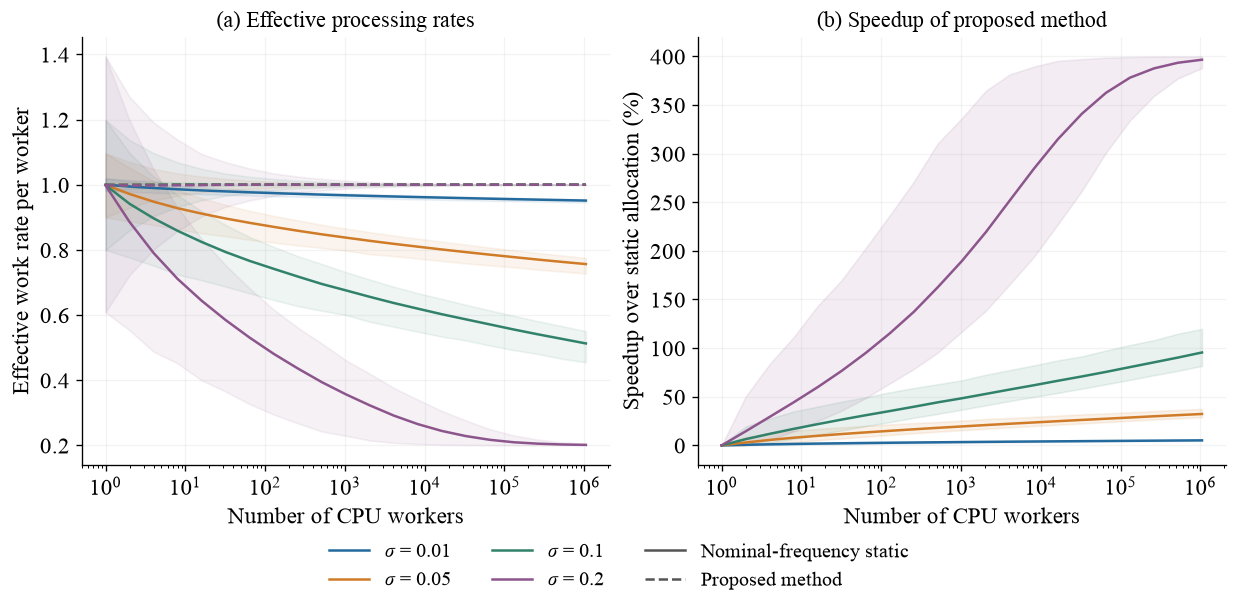

In [6]:
apply_style('comparison')
fig, axes = plt.subplots(1, 2, figsize=figure_size('fig06_mean_minimum_comparison'), layout='constrained')
for col, std in zip(COLORS, (0.01, 0.05, 0.1, 0.2)):
    rr = [r for r in a if r['parent_std'] == std]
    x = [r['workers'] for r in rr]
    axes[0].plot(x, [r['static_rate'] for r in rr], color=col, label=f'$\\sigma$ = {std:g}')
    axes[0].plot(x, [r['theory_rate'] for r in rr], color=col, ls='--', lw=1.5)
    for method in ('static', 'theory'):
        axes[0].fill_between(x, [r[method + '_rate_p025'] for r in rr], [r[method + '_rate_p975'] for r in rr], color=col, alpha=band_alpha(0.08))
    axes[1].plot(x, [r['speedup_pct'] for r in rr], color=col, label=f'$\\sigma$ = {std:g}')
    axes[1].fill_between(x, [r['speedup_pct_p025'] for r in rr], [r['speedup_pct_p975'] for r in rr], color=col, alpha=band_alpha(0.1))
axes[0].plot([], [], color='#555', ls='-', label='Nominal-frequency static')
axes[0].plot([], [], color='#555', ls='--', label='Proposed method')
axes[0].set(ylabel='Effective work rate per worker', title='(a) Effective processing rates')
axes[1].set(ylabel='Speedup over static allocation (%)', title='(b) Speedup of proposed method')
for ax in axes:
    ax.set(xscale='log', xlabel='Number of CPU workers')
    ax.legend(frameon=False)
    ax.grid(alpha=0.15)
comparison_legend(fig, axes, ncol=3)
show_figure(fig, 'fig06_mean_minimum_comparison')

## 2 — Figure A.2: Finite-history time variability and trial-rate estimates

The figure uses the original 12,000 repetitions. The left panel shows relative standard deviations of completion time.
The right panel shows median trial-rate estimates and central 95% ranges.


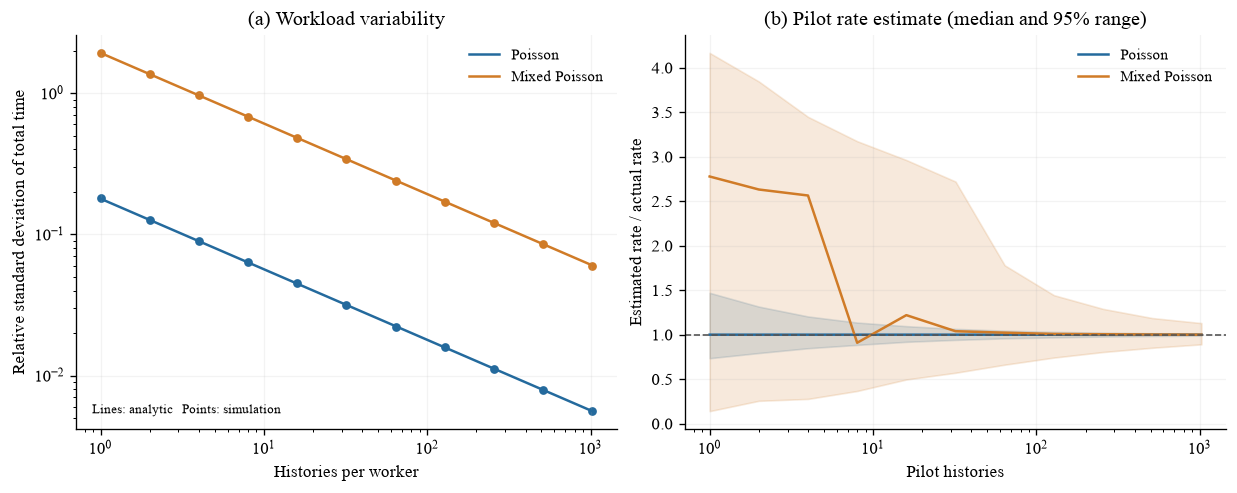

In [7]:
apply_style('original')
fig, axes = plt.subplots(1, 2, figsize=figure_size('fig02_history_variability'), layout='constrained')
for color, model, label in zip(COLORS, ('poisson', 'mixed_poisson'), ('Poisson', 'Mixed Poisson')):
    rows = [r for r in histories if r['model'] == model]
    x = [r['histories'] for r in rows]
    axes[0].loglog(x, [r['analytic_time_cv'] for r in rows], color=color, label=label)
    axes[0].scatter(x, [r['empirical_time_cv'] for r in rows], color=color, s=18)
    axes[1].plot(x, [r['speed_median'] for r in rows], color=color, label=label)
    axes[1].fill_between(x, [r['speed_p025'] for r in rows], [r['speed_p975'] for r in rows], color=color, alpha=band_alpha(0.16))
axes[0].set(xlabel='Histories per worker', ylabel='Relative standard deviation of total time', title='(a) Workload variability')
axes[0].text(0.03, 0.04, 'Lines: analytic   Points: simulation', transform=axes[0].transAxes, fontsize=8 * FONT_SCALE)
axes[1].set(xscale='log', xlabel='Pilot histories', ylabel='Estimated rate / actual rate', title='(b) Pilot rate estimate (median and 95% range)')
axes[1].axhline(1, color='#555555', ls='--', lw=1)
for ax in axes:
    ax.legend(frameon=False)
    ax.grid(alpha=0.15)
show_figure(fig, 'fig02_history_variability')

## 3 — Figure A.3: Combined history-cost and CPU-rate variation

Each setting uses 2,000 paired realizations. CPU σ = 0 and 0.1 identify the two available rate settings.
The completion-time and paired-speedup plots retain central 95% sample ranges.


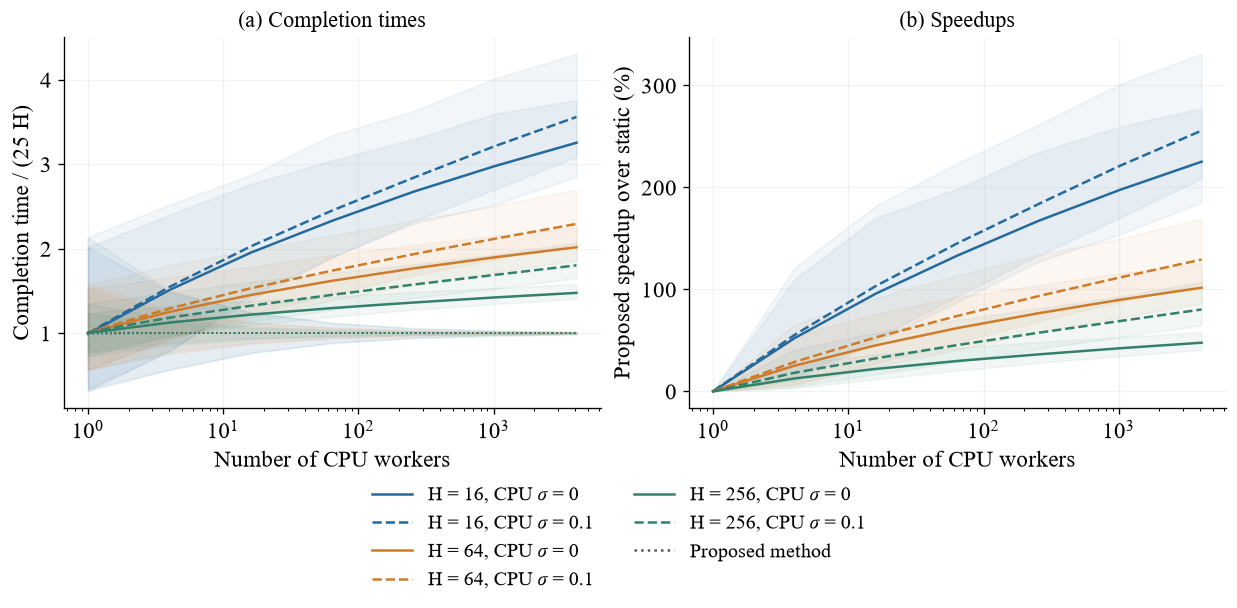

In [8]:
apply_style('comparison')
fig, axes = plt.subplots(1, 2, figsize=figure_size('fig07_history_rate_comparison'), layout='constrained')
for col, h in zip(COLORS, (16, 64, 256)):
    for std, ls in ((0.0, '-'), (0.1, '--')):
        rr = [r for r in b if r['model'] == 'mixed_poisson' and r['histories'] == h and (r['parent_std'] == std)]
        x = [r['workers'] for r in rr]
        label = f'H = {h}, CPU ' + f'$\\sigma$ = {std:g}'
        axes[0].plot(x, [r['static_time'] for r in rr], color=col, ls=ls, label=label)
        axes[1].plot(x, [r['speedup_pct'] for r in rr], color=col, ls=ls, label=label)
        axes[0].plot(x, [r['theory_time'] for r in rr], color=col, ls=':', lw=1)
        for method in ('static', 'theory'):
            axes[0].fill_between(x, [r[method + '_time_p025'] for r in rr], [r[method + '_time_p975'] for r in rr], color=col, alpha=band_alpha(0.06))
        axes[1].fill_between(x, [r['speedup_pct_p025'] for r in rr], [r['speedup_pct_p975'] for r in rr], color=col, alpha=band_alpha(0.06))
axes[0].plot([], [], color='#555', ls=':', label='Proposed method')
axes[0].set(ylabel='Completion time / (25 H)', title='(a) Completion times')
axes[1].set(ylabel='Proposed speedup over static (%)', title='(b) Speedups')
for ax in axes:
    ax.set(xscale='log', xlabel='Number of CPU workers')
    ax.legend(frameon=False)
    ax.grid(alpha=0.15)
comparison_legend(fig, axes, ncol=2)
show_figure(fig, 'fig07_history_rate_comparison')

## 4 — Figure A.4: Abrupt and gradual rate changes

The rate profiles and cumulative work use a 40% reduction, an onset time of 0.30, and a gradual-transition duration of 0.25.
The parameters are specified in `profile` in the following cell.


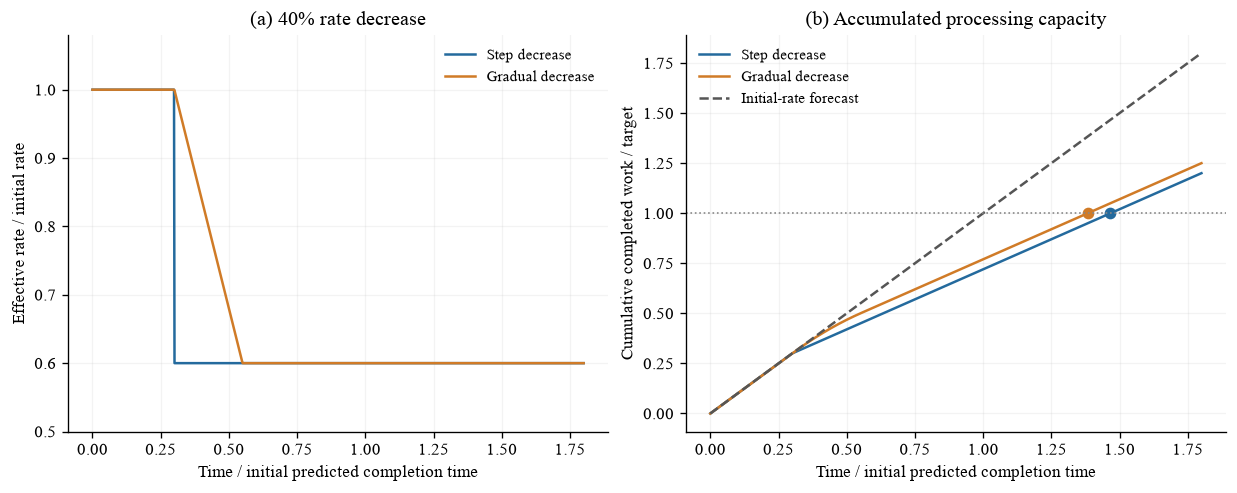

In [9]:
apply_style('original')
fig, axes = plt.subplots(1, 2, figsize=figure_size('fig03_rate_drift'), layout='constrained')
time = np.linspace(0, 1.8, 1001)
for color, mode, label in zip(COLORS, ('step', 'ramp'), ('Step decrease', 'Gradual decrease')):
    profile = dict(drop=0.4, onset=0.3, ramp=0.25, mode=mode)
    axes[0].plot(time, rate_at(time, **profile), color=color, label=label)
    axes[1].plot(time, capacity_at(time, **profile), color=color, label=label)
    finish = float(completion_time(1, **profile))
    axes[1].plot([finish], [1], marker='o', color=color)
axes[0].set(xlabel='Time / initial predicted completion time', ylabel='Effective rate / initial rate', title='(a) 40% rate decrease', ylim=(0.5, 1.08))
axes[1].plot(time, time, color='#555555', ls='--', label='Initial-rate forecast')
axes[1].axhline(1, color='#888888', ls=':', lw=1)
axes[1].set(xlabel='Time / initial predicted completion time', ylabel='Cumulative completed work / target', title='(b) Accumulated processing capacity')
for ax in axes:
    ax.legend(frameon=False)
    ax.grid(alpha=0.15)
show_figure(fig, 'fig03_rate_drift')

## 5 — Figure A.5: Affected CPU fraction and allocation performance

The figure shows analytical results for abrupt and gradual 40% rate reductions.
The variable `c` also contains results for reductions of 20%, 60%, and approximately 70.09%.
Update the figure caption when selecting another reduction magnitude.


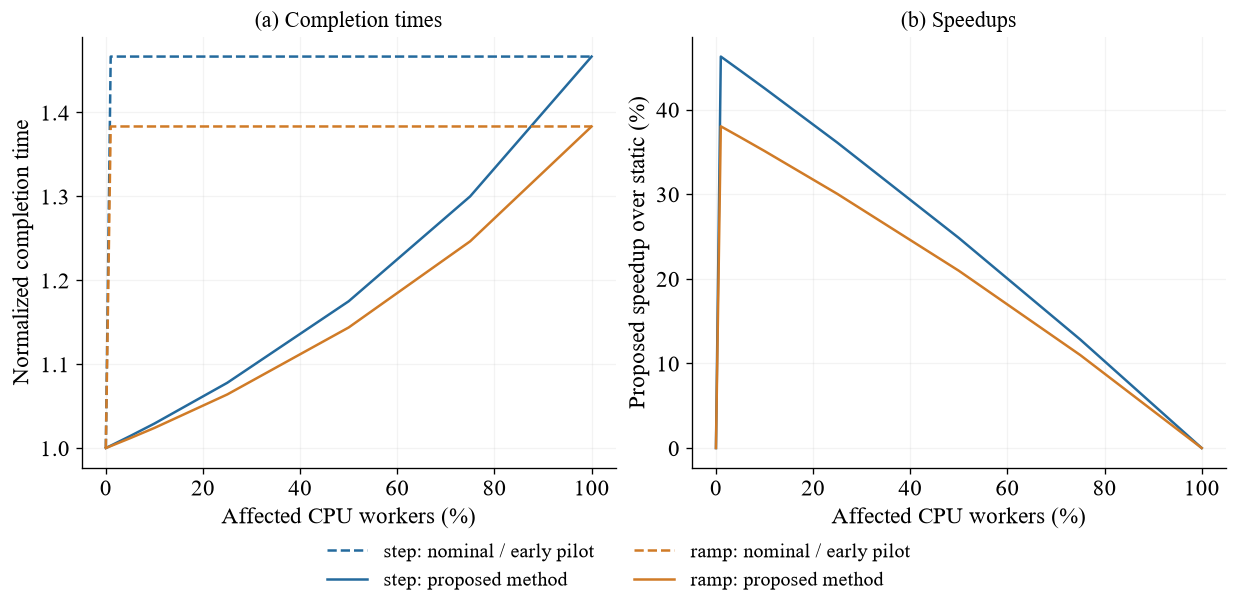

In [10]:
apply_style('comparison')
fig, axes = plt.subplots(1, 2, figsize=figure_size('fig08_drift_allocation_comparison'), layout='constrained')
for col, mode in zip(COLORS, ('step', 'ramp')):
    rr = [r for r in c if r['profile'] == mode and r['drop'] == 0.4]
    x = [100 * r['affected_fraction'] for r in rr]
    axes[0].plot(x, [r['nominal_time'] for r in rr], color=col, ls='--', label=f'{mode}: nominal / early pilot')
    axes[0].plot(x, [r['theory_time'] for r in rr], color=col, label=f'{mode}: proposed method')
    axes[1].plot(x, [r['speedup_pct'] for r in rr], color=col, label=mode)
axes[0].set(ylabel='Normalized completion time', title='(a) Completion times')
axes[1].set(ylabel='Proposed speedup over static (%)', title='(b) Speedups')
for ax in axes:
    ax.set(xlabel='Affected CPU workers (%)')
    ax.legend(frameon=False)
    ax.grid(alpha=0.15)
comparison_legend(fig, axes, ncol=2)
show_figure(fig, 'fig08_drift_allocation_comparison')

## 6 — Figure A.6: Completion-time prediction errors

The controls separate node differences, history-cost variability, rate changes, and their combination.
The left panel uses a 16-history trial.


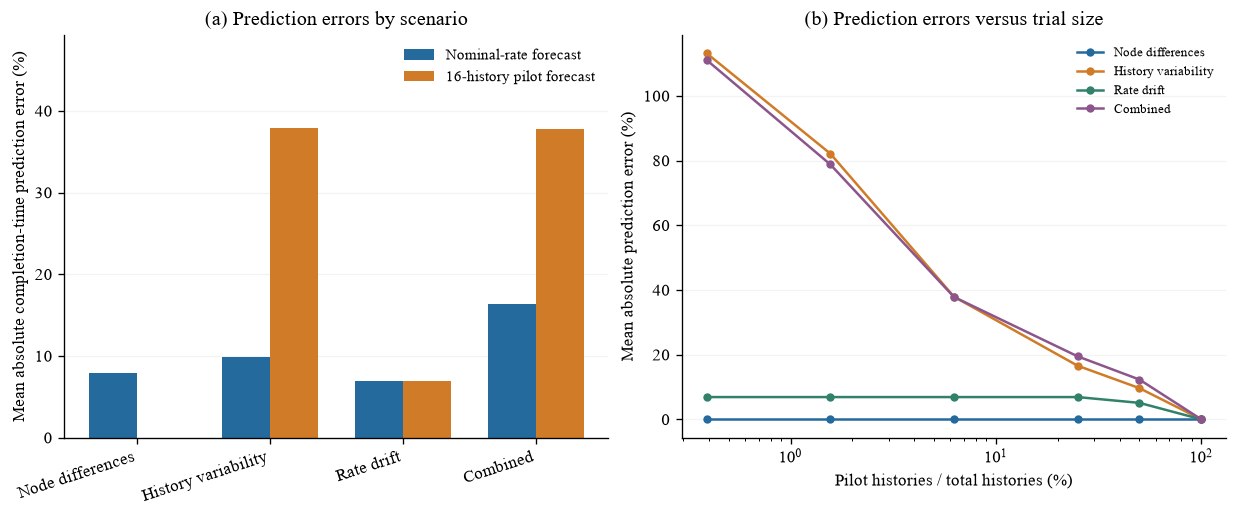

In [11]:
apply_style('original')
fig, axes = plt.subplots(1, 2, figsize=figure_size('fig04_combined'), layout='constrained')
labels = list(CASE_NAMES.values())
x = np.arange(len(labels))
barwidth = 0.36
selected = [next((r for r in combined if r['case'] == case and r['pilot_histories'] == 16)) for case in CASE_NAMES]
axes[0].bar(x - barwidth / 2, [r['nominal_mean_abs_error_pct'] for r in selected], barwidth, color=COLORS[0], label='Nominal-rate forecast')
axes[0].bar(x + barwidth / 2, [r['mean_abs_error_pct'] for r in selected], barwidth, color=COLORS[1], label='16-history pilot forecast')
axes[0].set_xticks(x, labels, rotation=18, ha='right')
axes[0].set(ylabel='Mean absolute completion-time prediction error (%)', title='(a) Prediction errors by scenario')
axes[0].set_ylim(0, 1.3 * max((r['mean_abs_error_pct'] for r in selected)))
axes[0].legend(frameon=False)
for color, case in zip(COLORS, CASE_NAMES):
    rows = [r for r in combined if r['case'] == case]
    axes[1].plot([100 * r['pilot_fraction'] for r in rows], [r['mean_abs_error_pct'] for r in rows], marker='o', ms=4, color=color, label=CASE_NAMES[case])
axes[1].set(xscale='log', xlabel='Pilot histories / total histories (%)', ylabel='Mean absolute prediction error (%)', title='(b) Prediction errors versus trial size')
axes[1].legend(frameon=False, fontsize=8 * FONT_SCALE)
for ax in axes:
    ax.grid(axis='y', alpha=0.15)
    ax.set_axisbelow(True)
show_figure(fig, 'fig04_combined')

## 7 — Figure A.7: Completion times and effective rates in the combined case

In the original combined setting, each CPU independently has a 25% probability of undergoing a 40% rate reduction.
The figure compares nominal-frequency static allocation, retained-trial static allocation, and the proposed method.


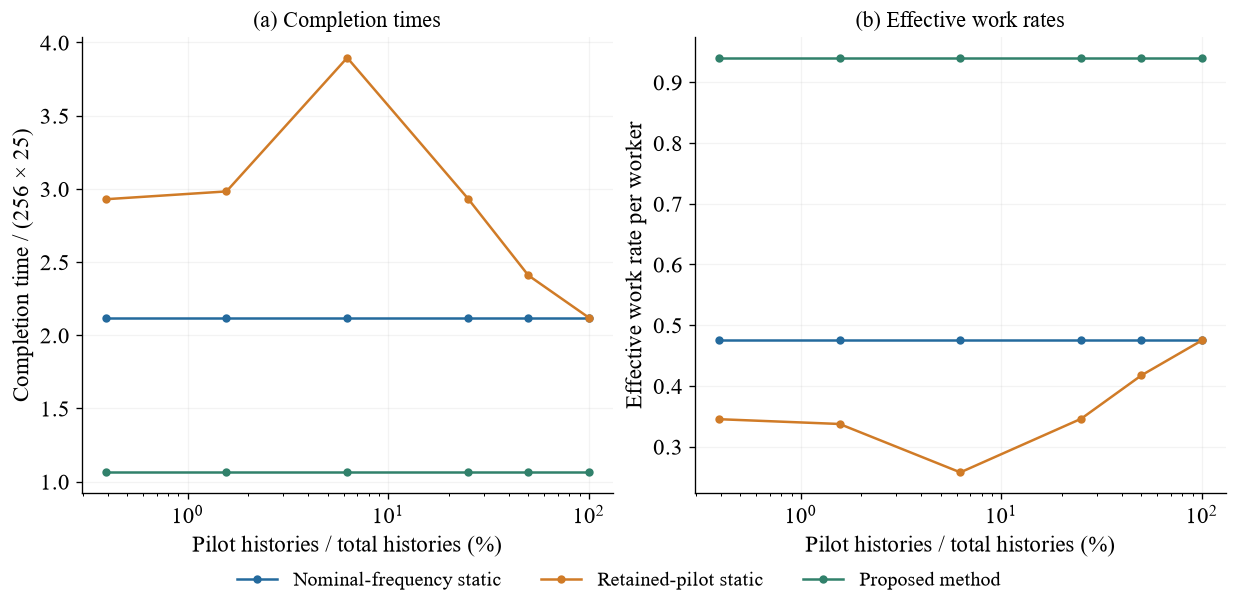

In [12]:
apply_style('comparison')
rows = d
comparison = None
title = 'Completion times'
fig, axes = plt.subplots(1, 2, figsize=figure_size('fig09_static_theory_comparison'), layout='constrained')
rr = [r for r in rows if r['case'] == 'combined']
x = [100 * r['pilot_fraction'] for r in rr]
for key, col, label in [('nominal', COLORS[0], 'Nominal-frequency static'), ('pilot', COLORS[1], 'Retained-pilot static'), ('theory', COLORS[2], 'Proposed method')]:
    axes[0].plot(x, [r[key + '_time'] for r in rr], color=col, marker='o', ms=4, label=label)
    axes[1].plot(x, [r[key + '_rate'] for r in rr], color=col, marker='o', ms=4, label=label)
    if comparison is not None:
        other = [r for r in comparison if r['case'] == 'combined']
        axes[0].plot(x, [r[key + '_time'] for r in other], color=col, ls='--', marker='s', ms=4)
        axes[1].plot(x, [r[key + '_rate'] for r in other], color=col, ls='--', marker='s', ms=4)
axes[0].set(ylabel='Completion time / (256 × 25)', title='(a) ' + title)
axes[1].set(ylabel='Effective work rate per worker', title='(b) Effective work rates')
for ax in axes:
    ax.set(xscale='log', xlabel='Pilot histories / total histories (%)')
    ax.grid(alpha=0.15)
handles, labels = axes[0].get_legend_handles_labels()
if comparison is not None:
    from matplotlib.lines import Line2D
    handles += [Line2D([], [], color='#555', ls='-', marker='o'), Line2D([], [], color='#555', ls='--', marker='s')]
    labels += ['40% reduction', '70.09% reduction (3.343:1)']
fig.legend(handles, labels, loc='outside lower center', ncol=3, frameon=False, fontsize=(11 if comparison is not None else 12) * FONT_SCALE)
show_figure(fig, 'fig09_static_theory_comparison')

## 8 — Figure A.8: Paired comparisons with exactly half the CPUs affected

Exactly 128 of the 256 CPUs undergo a rate reduction in each setting.
The two reductions are 40% and 1−1/3.343 ≈ 70.09%.
Both settings share the same histories, initial rates, and affected CPU sets; only the reduction magnitude changes.


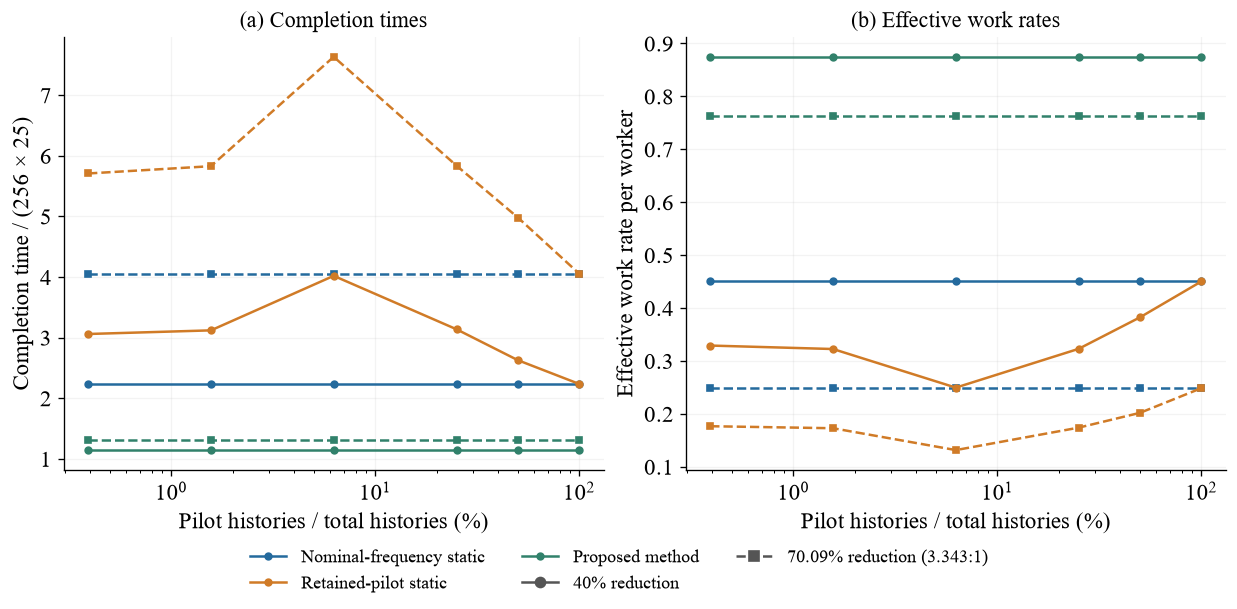

In [13]:
apply_style('comparison')
rows = d_half_40
comparison = d_half_sphere
title = 'Completion times'
fig, axes = plt.subplots(1, 2, figsize=figure_size('fig10_half_workers_paired'), layout='constrained')
rr = [r for r in rows if r['case'] == 'combined']
x = [100 * r['pilot_fraction'] for r in rr]
for key, col, label in [('nominal', COLORS[0], 'Nominal-frequency static'), ('pilot', COLORS[1], 'Retained-pilot static'), ('theory', COLORS[2], 'Proposed method')]:
    axes[0].plot(x, [r[key + '_time'] for r in rr], color=col, marker='o', ms=4, label=label)
    axes[1].plot(x, [r[key + '_rate'] for r in rr], color=col, marker='o', ms=4, label=label)
    if comparison is not None:
        other = [r for r in comparison if r['case'] == 'combined']
        axes[0].plot(x, [r[key + '_time'] for r in other], color=col, ls='--', marker='s', ms=4)
        axes[1].plot(x, [r[key + '_rate'] for r in other], color=col, ls='--', marker='s', ms=4)
axes[0].set(ylabel='Completion time / (256 × 25)', title='(a) ' + title)
axes[1].set(ylabel='Effective work rate per worker', title='(b) Effective work rates')
for ax in axes:
    ax.set(xscale='log', xlabel='Pilot histories / total histories (%)')
    ax.grid(alpha=0.15)
handles, labels = axes[0].get_legend_handles_labels()
if comparison is not None:
    from matplotlib.lines import Line2D
    handles += [Line2D([], [], color='#555', ls='-', marker='o'), Line2D([], [], color='#555', ls='--', marker='s')]
    labels += ['40% reduction', '70.09% reduction (3.343:1)']
fig.legend(handles, labels, loc='outside lower center', ncol=3, frameon=False, fontsize=(11 if comparison is not None else 12) * FONT_SCALE * FONT_SCALE)
show_figure(fig, 'fig10_half_workers_paired')

## Additional mechanism plots

The following two figures retain their complete plotting code and original data.


## 9 — Minimum effective CPU rate

This original minimum-rate plot uses 6,000 repetitions and reads `minimum_rates`.
Figure A.1 above uses the subsequently added paired results from complete CPU-rate realizations.
The original data sources are preserved for both figures.


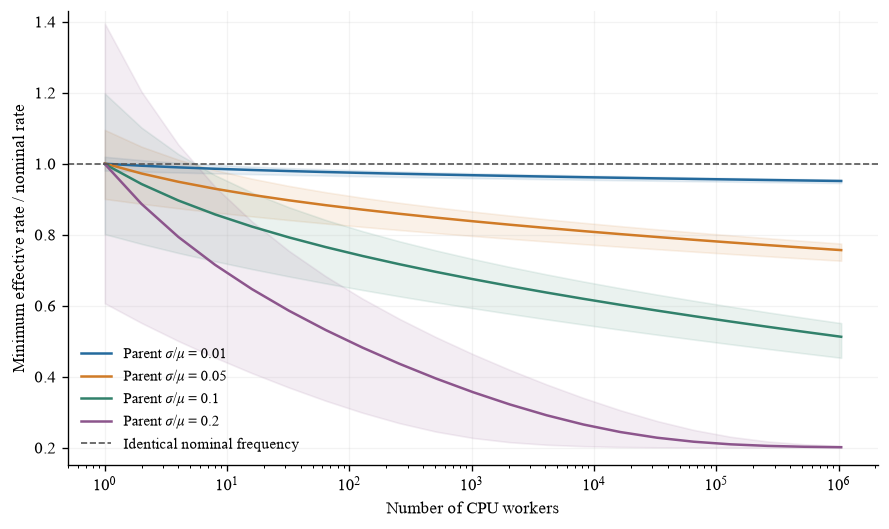

In [14]:
apply_style('original')
fig, ax = plt.subplots(figsize=figure_size('fig01_minimum_rate'), layout='constrained')
for color, cv in zip(COLORS, (0.01, 0.05, 0.1, 0.2)):
    rows = [r for r in minimum if r['parent_std'] == cv]
    x = [r['workers'] for r in rows]
    ax.plot(x, [r['mean_minimum'] for r in rows], color=color, label=f'Parent $\\sigma/\\mu$ = {cv:g}')
    ax.fill_between(x, [r['p025'] for r in rows], [r['p975'] for r in rows], color=color, alpha=band_alpha(0.1))
ax.axhline(1, color='#555555', ls='--', lw=1, label='Identical nominal frequency')
ax.set(xscale='log', xlabel='Number of CPU workers', ylabel='Minimum effective rate / nominal rate', ylim=(0.15, 1.43))
ax.legend(loc='lower left', frameon=False)
ax.grid(alpha=0.15)
show_figure(fig, 'fig01_minimum_rate')

## 10 — Finite-history completion times across multiple CPUs

The figure compares the two history-workload distributions.
Curves show means, and shaded bands show central 95% sample ranges.


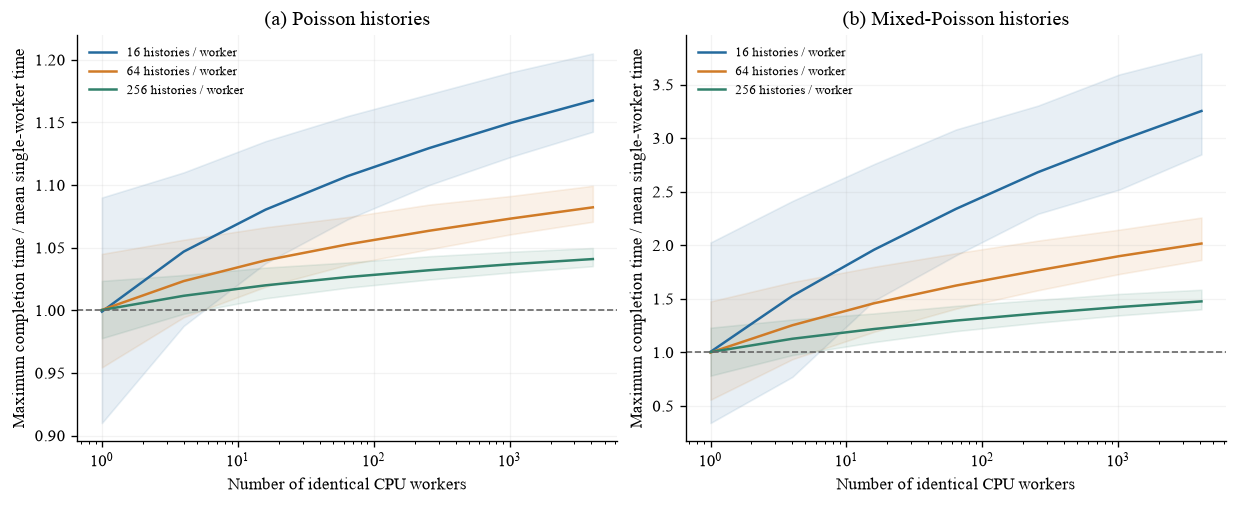

In [15]:
apply_style('original')
rows = many_workers
fig, axes = plt.subplots(1, 2, figsize=figure_size('fig05_many_workers_histories'), layout='constrained')
for ax, model, title in zip(axes, ['poisson', 'mixed_poisson'], ['(a) Poisson histories', '(b) Mixed-Poisson histories']):
    for color, count in zip(COLORS, [16, 64, 256]):
        group = [r for r in rows if r['model'] == model and r['histories'] == count]
        x = [r['workers'] for r in group]
        ax.plot(x, [r['mean_maximum'] for r in group], color=color, label=f'{count} histories / worker')
        ax.fill_between(x, [r['p025'] for r in group], [r['p975'] for r in group], color=color, alpha=band_alpha(0.1))
    ax.axhline(1, color='#666666', ls='--', lw=1)
    ax.set(xscale='log', xlabel='Number of identical CPU workers', ylabel='Maximum completion time / mean single-worker time', title=title)
    ax.legend(frameon=False, fontsize=8 * FONT_SCALE)
    ax.grid(alpha=0.15)
show_figure(fig, 'fig05_many_workers_histories')

## Data and code sources

- Embedded data are taken from `summary.json`, `allocation_summary.json`, `many_workers_histories.csv`, and the associated metadata.
- The notebook preserves the experimental numerical results. To adjust appearance only, rerun the relevant figure cells.
- Figure outputs are saved in the notebook. Exports use the specified filenames in `EXPORT_DIR` and can be used to update the corresponding manuscript figures.
